# Bayesian GARCH: From Volatility Forecasting to Portfolio Allocation

**Kang Yu** · Erdős Institute, Quantitative Methods in Finance · Fall 2026 · comprehensive research notebook

> **Comprehensive technical record.** For a shorter, self-contained tour of the same study (49 cells, about 30 s),
> start with `quick_walkthrough.ipynb`.

---

**Research question.** *Does accounting for Bayesian parameter uncertainty improve conditional variance forecasts,
predictive return distributions, and investment performance?*

**Abstract.** Four ETFs (SPY, QQQ, TLT, GLD) are forecast strictly out of sample with Gaussian GARCH(1,1), estimated
by maximum likelihood (MLE) and by Bayesian MCMC, on rolling 500- and 1,000-day windows refitted every 63 trading days.
The primary evaluation is 2017–2022; 2023–2026 had been inspected earlier and is a reproduction.
- **H1 (conditional variance).** Posterior-integrated variance forecasts lower QLIKE by about 0.005 ($p=0.10$,
  $0.08$ in 2017–22): not statistically reliable.
- **H2 (predictive distribution).** The posterior predictive mixture improves the log score by a small but reliable
  0.002–0.005 nats/day; a classical Laplace approximation captures 43–89% of it. **Student-$t$ GARCH, estimated by
  MLE, gains about five to six times as much in 2017–22** (3.6–7.5× across all period–window cells), because
  parameter uncertainty adds far too little tail mass to explain the observed fat tails.
- **H3 (investment).** A conservative rule based on the posterior 90th percentile of variance holds about 3.6 pp less
  ETF and has smaller drawdowns than MLE in 8 of 8 configurations. **Against an exposure-matched MLE control,
  calibrated only on past data, the advantage disappears,** and every Sharpe-difference interval contains zero.

**Two central findings.** (1) Innovation-distribution specification matters more for density forecasts than parameter
uncertainty in the Gaussian model. (2) Lower drawdowns that come with lower exposure are not evidence of better risk
timing; better-looking portfolios must be judged against exposure-controlled alternatives.

This notebook is the computational companion of the course report (`reports/research_report.pdf`). It follows the same
narrative, derives the models, explains the numerical methods and the reason for each metric and control, runs
representative estimations live, and recomputes every major table and figure of the report from the daily data.

<a id="toc"></a>
## Contents

| § | Section | What happens computationally |
|---|---|---|
| 1 | [Research question and motivation](#s1) | question, motivation, H1–H3, the two highlighted results |
| 2 | [Financial data and exploratory analysis](#s2) | prices → returns; stylised facts that motivate the models |
| 3 | [GARCH(1,1)](#s3) | model, moments, shock response, likelihood |
| 4 | [Maximum likelihood](#s4) | transformation, optimiser, **fresh MLE fit**, boundary cases |
| 5 | [Bayesian inference](#s5) | prior, Metropolis algorithm, **fresh 4-chain MCMC fit**, diagnostics |
| 6 | [Bayesian volatility and density forecasting](#s6) | plug-in vs integrated vs upper-quantile; predictive mixture |
| 7 | [Student-$t$ GARCH and other benchmarks](#s7) | **fresh Student-$t$ MLE fit**, EWMA, Laplace; two mechanisms for heavy tails |
| 8 | [Data and rolling experimental design](#s8) | rolling-design diagram, timeline, look-ahead guards, artifact integrity |
| 9 | [H1 — Conditional variance forecasting](#s9) | QLIKE derivation and check, Diebold–Mariano/HAC, H1 conclusion |
| 10 | [H2 — Predictive return distributions](#s10) | log score, mixture scores from draws, **Student-$t$ vs Bayes**, Finding 1 |
| 11 | [H2 continued: model adequacy, heavy tails and stress](#s11) | residuals, PIT, VaR, stress windows, $3\,\mathrm{CV}^2$ |
| 12 | [H3 — Portfolio construction and simulation](#s12) | rule, **simulation flowchart**, ledger, worked calculation |
| 13 | [H3 — Evaluation and the exposure-matched control](#s13) | **exposure-matched MLE**, tables, block bootstrap, Finding 2 |
| 14 | [Discussion, limitations and report cross-check](#s14) | findings, report cross-check, limitations, future work |
| 15 | [Reproducibility appendix](#s15) | environment, seeds, workflows, derivations, check summary |
| 16 | [Final research summary](#s16) | H1/H2/H3, the two findings, overall conclusion |

**Reproducibility levels.** Every result in this notebook carries one of three labels. The same labels are used in
`docs/notebook_coverage.md`, which maps each report figure, table and claim to a cell.

| Label | Meaning |
|---|---|
| 🟢 **raw data** | computed here from adjusted prices / DFF rates, or a model fitted here |
| 🔵 **saved forecasts** | recomputed here from the saved daily forecasts, posterior draws or fit logs of the full rolling experiment |
| ⚪ **artifact** | displayed from a checksum-verified saved artifact, because its computation is expensive or external |

Every numerical cross-check is recorded with `check(...)`, and the summary table is in [§15.6](#s15-6).

> **Conventions.** $r_t$ is the daily decimal log return. "Variance" means the *daily* conditional variance $h_t$,
> and annualised volatility is $\sqrt{252\,h_t}$, with 252 trading days per year. Exercises are marked **Q**.
> Their labels (Q A1, …, Q H3) match the answers in `docs/study_guide.md`.
>
> **Runtime.** About 1.5 minutes on a laptop, CPU only. The complete rolling experiment (320 MCMC refits) is
> **not** rerun here; see [§8.5](#s8-5).

In [1]:
import sys, time, json, tempfile, platform, zlib, warnings
from pathlib import Path
T_START = time.time()
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').exists() and (p / 'src' / 'bgarch').is_dir())
sys.path.insert(0, str(ROOT / 'src'))   # works from notebooks/ and course/notebooks/; harmless after `pip install -e .`

import numpy as np, pandas as pd, matplotlib, matplotlib.pyplot as plt
from scipy.special import expit, logit
from scipy.stats import norm, t as student_dist
from scipy.optimize import minimize, brentq
from IPython.display import Image, display

# reusable library
from bgarch import data, garch, bayes, forecast as fc, student_t as tg, ewma, evaluation as ev, diagnostics as dg, portfolio as pf
# experiment configuration, pipeline and report code (outside the library)
from bgarch_experiments import config as cfg, tables, strategies, adequacy as A, figures as FG, notebook as N
from bgarch_experiments.artifacts import verify_manifest
%matplotlib inline

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.width', 170); pd.set_option('display.max_columns', 40); pd.set_option('display.precision', 5)
C = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#8a5cd0']; MUTED, INK = '#6b6a63', '#1f1f1e'
STYLE = {'figure.dpi': 110, 'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
         'grid.color': '#e4e3dc', 'grid.linewidth': .6, 'axes.axisbelow': True, 'legend.frameon': False}
plt.rcParams.update(STYLE)

RAW, FC, ART = N.RAW, N.FORECASTS, N.ARTIFACT       # reproducibility levels
check = N.Checks()                                   # every numerical verification is recorded here
OUT = Path(tempfile.mkdtemp(prefix='walkthrough_'))  # regenerated tables/figures go here, never into validated folders
STORE = tables.Store(cfg.SAVED_FORECASTS); tables.use_store(STORE)
SEGL = {'ext': '2017–22', 'test': '2023–26'}
ASSETS, WINDOWS, SEGS = data.ASSETS, cfg.WINDOWS, cfg.SEGS

check('saved forecast/fit artifacts match SHA-256 manifest', verify_manifest() == 48, '48 files', ART)
check('saved posterior-draw artifacts match SHA-256 manifest', A.verify_manifest() == 16, '16 files', ART)
import src, bgarch
print('bgarch', bgarch.__version__, 'from', Path(bgarch.__file__).parent.relative_to(ROOT))
print('validated numerical core (original project) from', Path(src.__file__).parent.relative_to(ROOT))
print('scratch output folder (temporary):', OUT.name)

PASS  saved forecast/fit artifacts match SHA-256 manifest  [48 files]
PASS  saved posterior-draw artifacts match SHA-256 manifest  [16 files]
bgarch 1.1.0 from src/bgarch
validated numerical core (original project) from src
scratch output folder (temporary): walkthrough_i48979an


<a id="s1"></a>
## 1. Research question and motivation

### 1.1 The question and why it matters

> *Does accounting for Bayesian parameter uncertainty improve conditional variance forecasts, predictive return
> distributions, and investment performance?*

**Motivation.**
- **Volatility clustering.** Volatility, the standard deviation of returns, is forecastable because large price moves
  cluster in time. GARCH(1,1) (Bollerslev, 1986) is the benchmark model for this clustering and is notoriously hard to
  beat out of sample (Hansen & Lunde, 2005).
- **Parameter uncertainty.** Its three parameters are estimated from a few years of noisy daily data, and persistence
  often sits close to the stationarity boundary. The usual MLE forecast treats them as exact; a **Bayesian** treatment
  propagates their uncertainty by averaging forecasts over the posterior.
- **Heavy tails.** Daily returns have far more extreme days than a normal distribution allows (§2.3).
- **A variance is not a distribution.** Two forecasts can agree on the variance and still assign very different
  probabilities to a crash, so variance forecasts and density forecasts need different metrics.
- **Statistics versus economics.** A forecast can be more accurate without producing better decisions, and a strategy
  can look safer simply because it holds less risk.

| | Hypothesis | Metric | Section |
|---|---|---|---|
| **H1** | Bayesian parameter integration improves one-step-ahead **conditional variance** point forecasts relative to Gaussian GARCH MLE | QLIKE, Diebold–Mariano | [§9](#s9) |
| **H2** | Bayesian parameter integration improves the full **predictive distribution** of daily returns | log predictive score, Diebold–Mariano | [§10–§11](#s10) |
| **H3** | Using posterior uncertainty in volatility-targeted allocation produces **better investment outcomes, beyond merely reducing risky exposure** | Sharpe ratio, drawdown, exposure-matched control, block bootstrap | [§12–§13](#s12) |

Each hypothesis section answers the same six questions: *what is asked, how it is investigated, which metric, why that
metric is appropriate, what the numbers show, and what can be concluded.* H1 is completed before H2 begins.

**Two highlighted results.**
- **Student-$t$ GARCH versus Bayesian integration (§10.3).** Both widen the predictive distribution, by different
  mechanisms: mixing Gaussians over parameter uncertainty, or heavy-tailed innovations inside the model.
- **The exposure-matched MLE control (§13.4).** It separates "the Bayesian rule holds less risk" from "the posterior
  tells it *when* to hold less risk".

### 1.2 How the questions connect

$$\underbrace{\text{parameter estimation}}_{\S4\text{ MLE},\ \S5\text{ posterior}}\;\longrightarrow\;
\underbrace{\text{variance and density forecasts}}_{\S6,\ \S7}\;\longrightarrow\;
\underbrace{\text{portfolio weights } w_t=\min(1,\,0.10/\sqrt{252h_t})}_{\S11}\;\longrightarrow\;
\underbrace{\text{economic evaluation}}_{\S12}$$

Each arrow can lose the Bayesian effect.
- A posterior that differs from the MLE may still give nearly the same variance forecast (H1).
- A better predictive density may come from its *shape*, which the portfolio rule ignores because it uses only a
  variance (H2 vs H3).
- A portfolio rule may "win" only because it holds less risk (H3). The exposure-matched control of §13 is
  designed to separate *information* from *conservatism*.

The study separates two Bayesian mechanisms:
1. **Shrinkage**: the prior moves the point estimate. This is measured by MLE → posterior-mean plug-in.
2. **Integration**: averaging over the posterior. This is measured by posterior-mean plug-in → posterior-integrated
   forecast.

It also asks whether either mechanism matters as much as a simple *model change*: Student-$t$ innovations.

### 1.3 Roadmap and computational strategy

- **Derivations** (§3–§7, §9–§10, §13, §15.4) state each model, estimator, scoring rule and test, with the
  assumptions they need.
- **Live computations.** One representative MLE fit, one four-chain MCMC fit, Student-$t$, EWMA and Laplace fits,
  and a hand-written portfolio ledger are computed here and matched to the saved research run.
- **Full-experiment results** (4 ETFs × 2 windows × 2 periods, 320 quarterly refits, 9,896 forecast days per
  model) are **recomputed from the saved daily forecasts**: losses, scores, tests, diagnostics, portfolios and
  bootstraps. The 320 MCMC refits themselves are loaded, not rerun. A command for rerunning them is in §8.5.
- **Cross-check against the report.** The report's LaTeX tables are regenerated from this notebook's numbers and
  compared byte for byte ([§14.2](#s14-2)), and its figures are compared pixel for pixel.

<a id="s2"></a>
## 2. Financial data and exploratory analysis

### 2.1 Assets, prices and returns

| Ticker | What it is | Why it is in the study |
|---|---|---|
| **SPY** | ETF tracking the S&P 500 index of large US companies | the canonical equity-risk asset |
| **QQQ** | ETF tracking the Nasdaq-100 (technology-heavy) | equity with higher volatility |
| **TLT** | ETF holding US Treasury bonds with 20+ years to maturity | long-duration interest-rate risk, different volatility dynamics |
| **GLD** | ETF holding physical gold | a commodity, weakly related to equities |

An **ETF** (exchange-traded fund) trades like a stock, and its price tracks a basket of underlying assets. The
**close** is the last trade price of the day; all signals and trades here use closing prices. **Cash**, the safe
alternative to holding the ETF, earns the effective federal funds rate (**DFF**, FRED). DFF is the overnight rate at
which US banks lend to one another and is a proxy for what a cash account earns.

**Adjusted prices.** ETFs pay dividends (equity ETFs) or coupon income (bond ETFs). On the ex-dividend date the
quoted price drops by roughly the payment, but an investor who keeps the cash has lost nothing. Funds can also
split shares. An *adjusted* price series rescales history so that ratios of adjusted prices equal total-return growth:
$$P^{\text{adj}}_t=P_t\prod_{s>t}\kappa_s,\qquad \kappa_s=1-\frac{D_s}{P_{s-1}}\ \text{for a dividend }D_s,\qquad \kappa_s=\tfrac1k\ \text{for a }k\text{-for-1 split}.$$
The project's files were downloaded from Yahoo Finance with `yfinance(..., auto_adjust=True)`, and only adjusted
closes were stored.

**Returns.** The model uses the daily **log return**
$$r_t=\log\!\left(\frac{P_t}{P_{t-1}}\right),$$
and the portfolio uses the **simple return** $R_t=e^{r_t}-1$, because wealth compounds multiplicatively in simple
returns. We model returns rather than prices for three reasons:
- Prices are non-stationary: their level and variance grow over time.
- Daily returns are approximately stationary, close to serially uncorrelated, and scale-free, so different assets
  are comparable.
- Log returns add over time, $\log(P_{t+k}/P_t)=\sum_{j=1}^k r_{t+j}$, which makes multi-day aggregation and
  likelihoods simple.

**Annualisation.** If daily returns were uncorrelated with variance $\sigma^2_d$, the variance of a 252-day sum
would be $252\sigma_d^2$. Annualised volatility is therefore $\sigma_d\sqrt{252}$: a daily standard deviation of 1%
is about 15.9% a year.

🟢 *raw data* — the next cell loads the four price files, builds returns and summarises them.

In [2]:
prices = pd.DataFrame({a: data.load_prices(a) for a in ASSETS})
rets = data.all_returns()                                # r_t = log(P_t / P_{t-1}); first date dropped
check('all four ETFs share one trading calendar', all(data.load_prices(a).index.equals(prices.index) for a in ASSETS), level=RAW)
check('log returns equal log price ratios', np.allclose(rets.SPY.to_numpy(), np.diff(np.log(prices.SPY.to_numpy()))), level=RAW)
print(f'{len(prices)} trading days of adjusted closes, {prices.index[0].date()} to {prices.index[-1].date()}; '
      f'{len(rets)} daily returns')
summ = pd.DataFrame({'ann. mean log return': rets.mean() * 252, 'ann. volatility': rets.std() * np.sqrt(252),
                     'daily sd': rets.std(), 'skewness': rets.skew(), 'excess kurtosis': rets.kurt(),
                     'worst day': rets.min(), 'date of worst': rets.idxmin().dt.date, 'best day': rets.max()})
display(summ.round(4))

PASS  all four ETFs share one trading calendar
PASS  log returns equal log price ratios
3482 trading days of adjusted closes, 2013-01-02 to 2026-11-04; 3481 daily returns


,ann. mean log return,ann. volatility,daily sd,skewness,excess kurtosis,worst day,date of worst,best day
SPY,0.1369,0.1675,0.0105,-0.5873,15.1437,-0.1159,2020-03-16,0.0999
QQQ,0.1770,0.2086,0.0131,-0.3995,7.9459,-0.1276,2020-03-16,0.1134
TLT,0.0004,0.1437,0.0091,-0.0440,4.3679,-0.0690,2020-03-17,0.0725
GLD,0.0598,0.1674,0.0105,-0.7055,7.6389,-0.1084,2026-01-30,0.0616


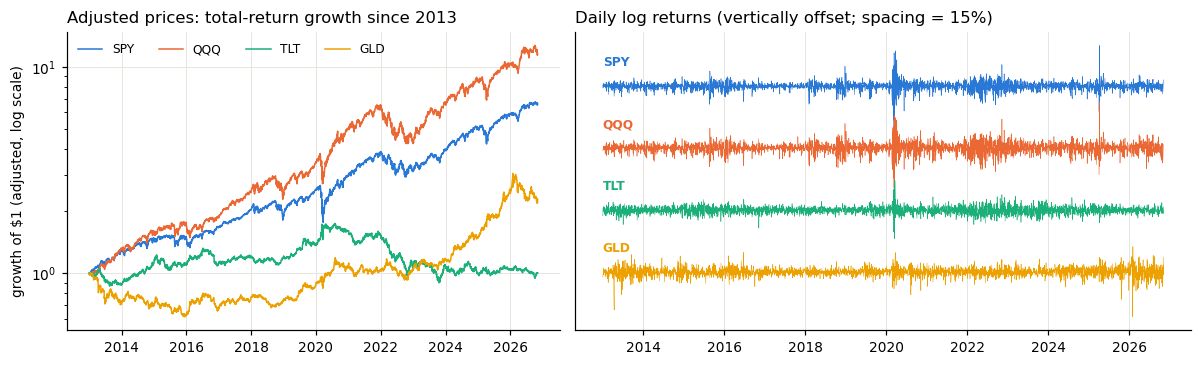

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={'width_ratios': [1, 1.25]})
for a, c in zip(ASSETS, C):
    ax[0].plot(prices.index, prices[a] / prices[a].iloc[0], lw=1, color=c, label=a)
ax[0].set_yscale('log'); ax[0].set_ylabel('growth of $1 (adjusted, log scale)')
ax[0].set_title('Adjusted prices: total-return growth since 2013', loc='left'); ax[0].legend(ncol=4, fontsize=8)
for a, c, off in zip(ASSETS, C, [0, 1, 2, 3]):
    ax[1].plot(rets.index, rets[a] - 0.15 * off, lw=.35, color=c)
    ax[1].text(rets.index[0], -0.15 * off + 0.05, a, color=c, fontsize=8, fontweight='bold')
ax[1].set_yticks([]); ax[1].set_title('Daily log returns (vertically offset; spacing = 15%)', loc='left')
plt.tight_layout(); plt.show()

**Reading the figures.**
- **Left.** Over almost 14 years the equity ETFs compounded far more than gold and long Treasuries. TLT lost most
  of its decade of gains in the 2022 rate-hike cycle. Prices trend, so their level has no stable distribution; this
  is why we model returns.
- **Right.** Returns fluctuate around zero with no visible trend. Their *amplitude* changes: quiet stretches
  alternate with turbulent ones, most visibly in March 2020 for all four ETFs and in 2022 for TLT. The mean is tiny
  compared with the day-to-day variation: SPY's annual mean log return of about 14% is roughly 0.05% a day, against
  a daily sd above 1%. This is why the model sets the conditional mean to zero (§3.1).

### 2.2 Volatility clustering: returns versus squared returns

If returns were independent, $r_t$ and every function of it, such as $r_t^2$, would be serially uncorrelated.
Empirically, returns are nearly uncorrelated, but their *magnitudes* are strongly and persistently correlated. Big
moves follow big moves, of either sign. The sample autocorrelation at lag $k$ is
$$\hat\rho_k=\frac{\sum_{t=k+1}^n(x_t-\bar x)(x_{t-k}-\bar x)}{\sum_{t=1}^n(x_t-\bar x)^2},$$
and under independence $\hat\rho_k\approx N(0,1/n)$, giving the approximate 95% band $\pm1.96/\sqrt n$. The
Ljung–Box statistic $Q(m)=n(n+2)\sum_{k\le m}\hat\rho_k^2/(n-k)$ jointly tests the first $m$ lags against
$\chi^2_m$. 🟢 *raw data*

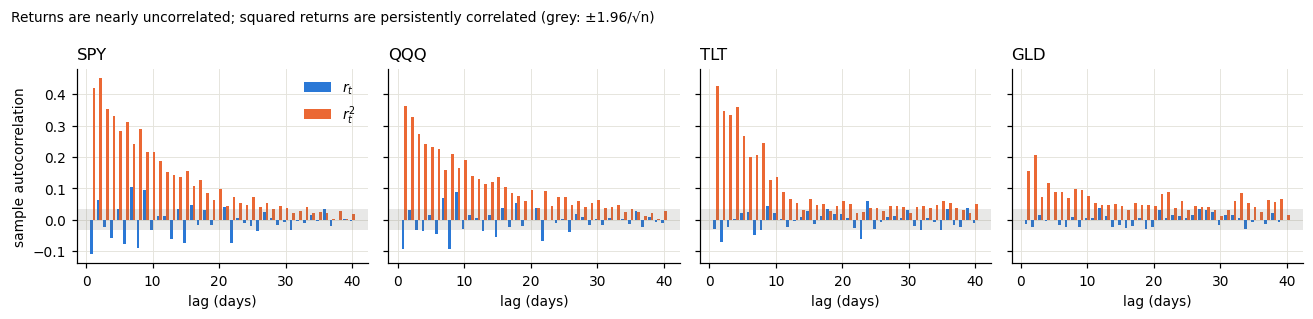

,ACF1 r,ACF1 r^2,"LB(10) p, r","LB(10) p, r^2"
SPY,-0.1106,0.4207,0.0000,0.0
QQQ,-0.0943,0.3633,0.0000,0.0
TLT,-0.0311,0.4264,0.0000,0.0
GLD,-0.0126,0.1565,0.6244,0.0


In [4]:
L = 40; band = 1.96 / np.sqrt(len(rets))
fig, ax = plt.subplots(1, 4, figsize=(12, 2.9), sharey=True)
for a_, a in zip(ax, ASSETS):
    a_.bar(np.arange(1, L + 1) - .2, dg.acf(rets[a], L), width=.4, color=C[0], label='$r_t$')
    a_.bar(np.arange(1, L + 1) + .2, dg.acf(rets[a] ** 2, L), width=.4, color=C[1], label='$r_t^2$')
    a_.axhspan(-band, band, color=MUTED, alpha=.15, lw=0); a_.set_title(a, loc='left'); a_.set_xlabel('lag (days)')
ax[0].set_ylabel('sample autocorrelation'); ax[0].legend()
fig.suptitle('Returns are nearly uncorrelated; squared returns are persistently correlated (grey: ±1.96/√n)', x=.01, ha='left', fontsize=9)
plt.tight_layout(); plt.show()
lb = pd.DataFrame({a: {'ACF1 r': dg.acf(rets[a], 1)[0], 'ACF1 r^2': dg.acf(rets[a] ** 2, 1)[0],
                       'LB(10) p, r': dg.ljung_box_p(rets[a], 10), 'LB(10) p, r^2': dg.ljung_box_p(rets[a] ** 2, 10)} for a in ASSETS}).T
display(lb.round(4))

**Interpretation.**
- The autocorrelations of $r_t$ are small. For SPY, QQQ and TLT the lag-1 value is significantly negative
  (about −0.03 to −0.11; Ljung–Box $p\approx0$), largely a feature of the 2020 turbulence, when large moves
  partially reversed the next day. GLD shows no significant autocorrelation. These effects are tiny next to the
  daily variance: a lag-1 coefficient of −0.1 explains 1% of the return variance. The model therefore keeps a zero
  conditional mean.
- The autocorrelations of $r_t^2$ are positive and decay slowly over dozens of lags. The Ljung–Box test rejects
  independence of $r_t^2$ overwhelmingly ($p\approx0$).
- This slowly decaying dependence in the second moment is exactly what GARCH models: a high variance today
  predicts a high variance tomorrow.
- Gold (GLD) shows the weakest clustering of the four.

### 2.3 Heavy tails

A Gaussian puts probability $2\Phi(-3)=0.27\%$ beyond $\pm3$ standard deviations and has excess kurtosis 0.
Daily returns have far more extreme days and large excess kurtosis (SPY above 15 over the full sample). Part of
this is volatility clustering itself, because mixing calm and turbulent periods fattens the unconditional tails;
§3.2 makes this precise. Whether *conditional* returns are still fat-tailed is a key question for §7 and §11.
🟢 *raw data*

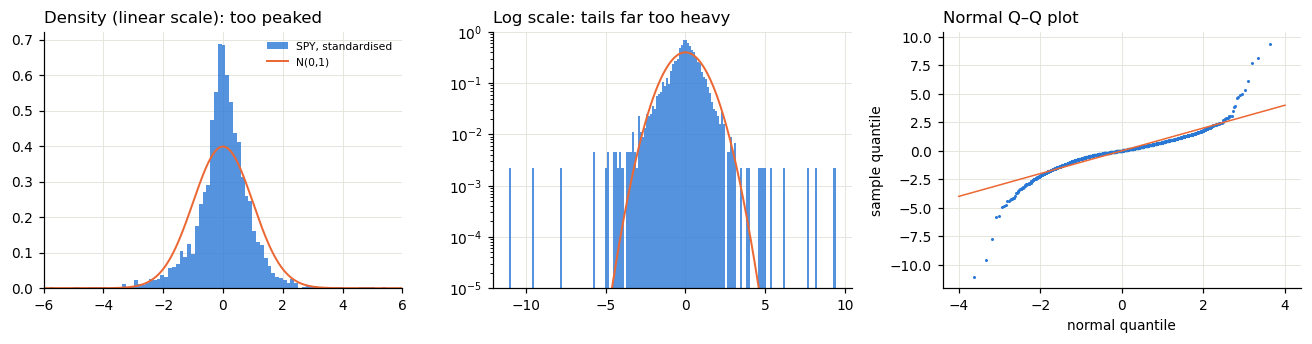

,days |r - mean| > 3 sd,expected if Gaussian,skewness,excess kurtosis
SPY,45.0,9.4,-0.59,15.14
QQQ,52.0,9.4,-0.40,7.95
TLT,26.0,9.4,-0.04,4.37
GLD,46.0,9.4,-0.71,7.64


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
z = (rets.SPY - rets.SPY.mean()) / rets.SPY.std()
x = np.linspace(-8, 8, 400)
ax[0].hist(z, bins=160, density=True, color=C[0], alpha=.8, label='SPY, standardised')
ax[0].plot(x, norm.pdf(x), color=C[1], lw=1.3, label='N(0,1)'); ax[0].set_xlim(-6, 6); ax[0].legend(fontsize=7)
ax[0].set_title('Density (linear scale): too peaked', loc='left')
ax[1].hist(z, bins=160, density=True, color=C[0], alpha=.8); ax[1].plot(x, norm.pdf(x), color=C[1], lw=1.3)
ax[1].set_yscale('log'); ax[1].set_ylim(1e-5, 1); ax[1].set_title('Log scale: tails far too heavy', loc='left')
qq = norm.ppf((np.arange(1, len(z) + 1) - .5) / len(z))
ax[2].plot(qq, np.sort(z), '.', ms=2, color=C[0]); ax[2].plot([-4, 4], [-4, 4], color=C[1], lw=1)
ax[2].set_xlabel('normal quantile'); ax[2].set_ylabel('sample quantile'); ax[2].set_title('Normal Q–Q plot', loc='left')
plt.tight_layout(); plt.show()
tails = pd.DataFrame({a: {'days |r - mean| > 3 sd': int((np.abs(rets[a] - rets[a].mean()) > 3 * rets[a].std()).sum()),
                          'expected if Gaussian': 2 * norm.sf(3) * len(rets), 'skewness': rets[a].skew(), 'excess kurtosis': rets[a].kurt()} for a in ASSETS}).T
display(tails.round(2))

**Interpretation.** The histogram is more peaked in the centre and much heavier in the tails than the Gaussian.
On the log scale the empirical tails decay roughly exponentially, not like $e^{-x^2/2}$. The Q–Q plot bends away
from the diagonal at both ends, more strongly on the loss side for SPY (negative skewness). Every ETF has several
times the Gaussian number of 3-sd days.

### 2.4 Market stress periods

The sample contains several distinct stress episodes. **Rolling 21-day realised volatility**,
$\sqrt{252\cdot\tfrac1{21}\sum_{j=0}^{20}r_{t-j}^2}$, is a simple *descriptive* measure of the local level of
volatility. It is backward-looking and noisy, it includes today's return, and it is **not** the latent conditional
volatility $\sqrt{h_t}$ that GARCH forecasts. 🟢 *raw data*

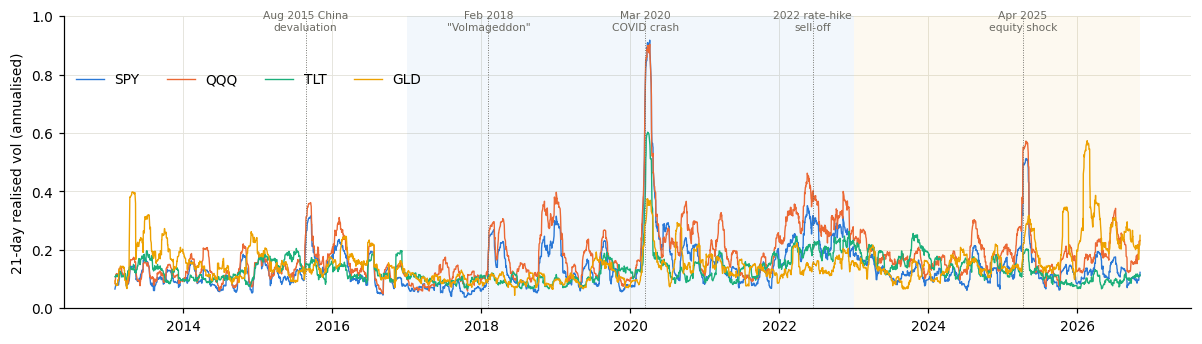

asset             SPY                              QQQ                              TLT                              GLD                      
date       2020-03-16 2020-03-12 2020-03-09 2020-03-16 2020-03-12 2020-03-09 2020-03-17 2020-03-18 2020-03-10 2026-01-30 2013-04-15 2025-10-21
log_return    -0.1159    -0.1006    -0.0813    -0.1276    -0.0962     -0.072     -0.069    -0.0581    -0.0526    -0.1084    -0.0919    -0.0664

In [6]:
fig, ax = plt.subplots(figsize=(11, 3.2))
for a, c in zip(ASSETS, C):
    ax.plot(rets.index, dg.realized_vol(rets[a].to_numpy()), lw=.9, color=c, label=a)
events = {'2015-08-24': 'Aug 2015 China\ndevaluation', '2018-02-05': 'Feb 2018\n"Volmageddon"', '2020-03-16': 'Mar 2020\nCOVID crash',
          '2022-06-13': '2022 rate-hike\nsell-off', '2025-04-09': 'Apr 2025\nequity shock'}
for d, lab in events.items():
    ax.axvline(pd.Timestamp(d), color=MUTED, lw=.6, ls=':'); ax.text(pd.Timestamp(d), 1.02, lab, fontsize=7, color=MUTED, va='top', ha='center',
                                                                    transform=ax.get_xaxis_transform())
for (lo, hi), lab in [(('2017-01-01', '2022-12-31'), 'independent evaluation 2017–22'), (('2023-01-01', '2026-11-04'), 'previously inspected 2023–26')]:
    ax.axvspan(pd.Timestamp(lo), pd.Timestamp(hi), color=C[0] if '2017' in lo else C[3], alpha=.06, lw=0)
ax.set_ylabel('21-day realised vol (annualised)'); ax.set_ylim(0, 1.0); ax.legend(ncol=4, loc='upper left', bbox_to_anchor=(0, .85))
plt.tight_layout(); plt.show()
worst = pd.DataFrame([dict(asset=a, date=d.date(), log_return=v) for a in ASSETS for d, v in rets[a].nsmallest(3).items()])
display(worst.round(4).set_index(['asset', 'date']).T)

**Interpretation.**
- Volatility regimes are visible: long calm stretches (2017, 2019, 2023–24) and abrupt spikes. The COVID crash
  pushed equity volatility above 80% annualised within days, from about 12%.
- The worst days cluster: for SPY, QQQ and TLT, all three worst days fall in March 2020. GLD's worst days are
  gold-specific sell-offs (April 2013, October 2025, January 2026).
- The independent evaluation period (blue shading) contains the 2018 shock, the 2020 crash and the 2022 joint
  stock–bond sell-off. It is a demanding test.
- Spikes start abruptly and decay gradually. No model that conditions only on past returns can foresee the first
  day of a crash; it can only react quickly afterwards (§11.5).

**Limitations of the data.** Yahoo Finance adjusted closes are a convenient but unofficial source, and unadjusted
closes were not stored, so the adjustment cannot be audited here. DFF is a proxy for the cash rate. Close-to-close
returns ignore intraday information. These approximations are shared by every method, so *contrasts* between
methods are unaffected, but absolute performance levels are approximate.

**Q A1.** Why would using $r_t$ in the forecast of $h_t$ inflate the apparent forecast skill, and why would it also
inflate backtest returns?

<a id="s3"></a>
## 3. Mathematical introduction to GARCH(1,1)

### 3.1 The model

Let $\mathcal F_{t-1}=\sigma(r_1,\dots,r_{t-1})$ be the information available at the close of day $t-1$. The
zero-mean Gaussian GARCH(1,1) model is
$$r_t=\sqrt{h_t}\,z_t,\qquad z_t\overset{iid}{\sim}N(0,1),\qquad h_t=\omega+\alpha\,r_{t-1}^2+\beta\,h_{t-1}.$$

- **Conditional mean.** $E[r_t\mid\mathcal F_{t-1}]=\sqrt{h_t}\,E[z_t]=0$. Daily expected returns are tiny
  compared with their sd (§2.1), and estimating them adds noise without improving variance forecasts, so the mean
  is set to zero.
- **Conditional variance.** $\operatorname{Var}(r_t\mid\mathcal F_{t-1})=E[r_t^2\mid\mathcal F_{t-1}]=h_t$. Because
  $h_t$ is a function of past returns, it is *known* at the end of day $t-1$. That is what makes it a one-step-ahead
  forecast.
- **Variance versus volatility.** $h_t$ is a variance in squared daily return units, about $10^{-4}$ for SPY.
  Volatility is its square root $\sqrt{h_t}$, quoted annualised as $\sqrt{252h_t}$. Portfolio rules use volatility;
  likelihoods and loss functions use variance.

**Parameters.**

| Parameter | Interpretation |
|---|---|
| $\omega>0$ | baseline level; with no shocks, $h$ would converge to $\omega/(1-\beta)$ |
| $\alpha\ge0$ | **reaction**: how much yesterday's squared return (the "news") moves today's variance |
| $\beta\ge0$ | **memory**: how much of yesterday's variance carries over |
| $p=\alpha+\beta$ | **persistence**: how slowly variance shocks die out |

**Volatility shocks.** Write $r_{t-1}^2=h_{t-1}+v_{t-1}$, where $v_{t-1}=h_{t-1}(z_{t-1}^2-1)$ is a zero-mean
"surprise". Then
$$h_t=\omega+(\alpha+\beta)h_{t-1}+\alpha v_{t-1}:$$
variance follows an AR(1)-like recursion with coefficient $p$, driven by the surprises with loading $\alpha$.

### 3.2 Positivity, stationarity, long-run variance and shock decay

- **Positivity.** If $\omega>0$ and $\alpha,\beta\ge0$, then $h_t>0$ for every return path, because each term is
  non-negative and $\omega$ is strictly positive.
- **Covariance stationarity.** Taking unconditional expectations, $E[h_t]=\omega+pE[h_{t-1}]$. A finite constant
  solution exists if and only if $p<1$, giving the **unconditional (long-run) variance**
  $$V=E[r_t^2]=\frac{\omega}{1-\alpha-\beta}.$$
- **Multi-step forecasts.** Since $E[r_{t+j}^2\mid\mathcal F_t]=E[h_{t+j}\mid\mathcal F_t]$, iterating the
  recursion gives
  $$E[h_{t+k}\mid\mathcal F_t]-V=p^{\,k-1}\,(h_{t+1}-V),$$
  so forecasts revert geometrically to $V$ (derivation in [§15.4](#s15-4)).
- **Half-life.** A shock's effect halves after $\log(1/2)/\log p$ days: $p=0.98$ gives about 34 days and
  $p=0.90$ about 7 days.
- **Integrated GARCH** ($p=1$). Shocks never die out and $V$ is undefined.
- **Fat unconditional tails.** Conditionally Gaussian returns with a time-varying variance form a *scale mixture*:
  $$\operatorname{kurt}(r_t)=\frac{E[r_t^4]}{E[r_t^2]^2}=3\,\frac{E[h_t^2]}{E[h_t]^2}\ \ge 3.$$
  GARCH therefore produces fat *unconditional* tails even with Gaussian innovations (§2.3).

**Initialisation.** The recursion needs a starting value. The project uses the stationary initialisation $h_1=V$,
which is implied by the parameters themselves. With $p<1$ the influence of $h_1$ on $h_t$ decays like $p^{t-1}$, so
after a 500-day window its effect on forecasts is negligible unless $p$ is very close to 1.

**One-step-ahead forecast.** At the close of day $T$, after observing $r_T$,
$$h_{T+1}=\omega+\alpha r_T^2+\beta h_T.$$
In the rolling experiment the parameters are re-estimated every 63 days. Between refits the parameters are frozen
and this update is applied daily with each new return (§8).

### 3.3 Numerical demonstration: the response to a single shock

We start a GARCH process at its long-run level and feed it one large negative return followed by "typical" days.
The demonstration uses $r^2=h$, i.e. the conditional expectation of each later squared return. The three
illustrative parameter sets share $V$ (15.9% annualised) and $\alpha=0.08$ but differ in persistence. The response
is computed by the plain-Python reference recursion (`garch.variance_path_reference`).

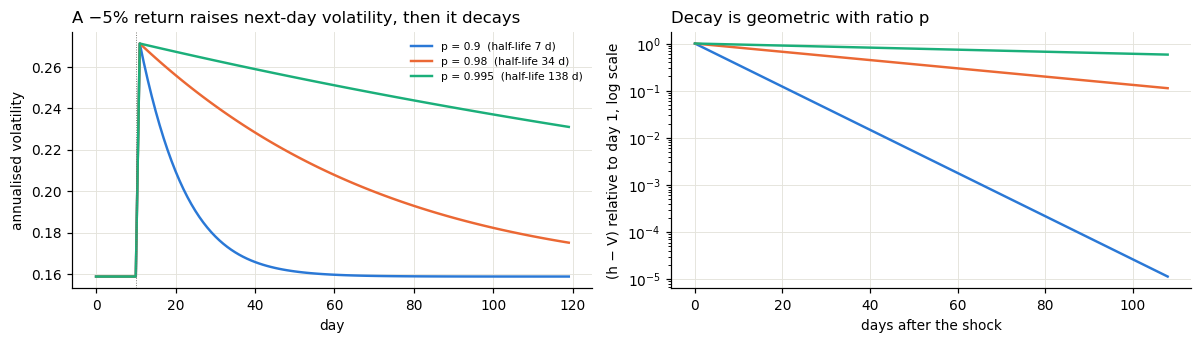

,persistence,alpha,beta,omega,jump_in_ann_vol,half_life_days,excess_after_20d
0,0.900,0.08,0.820,0.00001,0.11252,6.57881,0.12158
1,0.980,0.08,0.900,0.00000,0.11252,34.30962,0.66761
2,0.995,0.08,0.915,0.00000,0.11252,138.28257,0.90461


In [7]:
V0 = 1e-4                                                 # long-run variance: sqrt(252e-4) = 15.9% per year
n, shock_day, shock = 120, 10, -0.05                     # a -5% day
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
rows = []
for k, p_ in enumerate([0.90, 0.98, 0.995]):
    al = 0.08; be = p_ - al; om = V0 * (1 - p_)
    h = np.empty(n); h[0] = V0; r = np.zeros(n)
    for t in range(1, n):                                  # h_t = omega + alpha r_{t-1}^2 + beta h_{t-1}
        r_prev2 = shock ** 2 if t - 1 == shock_day else h[t - 1]   # E[r^2] = h on ordinary days
        h[t] = om + al * r_prev2 + be * h[t - 1]
    ax[0].plot(np.sqrt(252 * h), color=C[k], lw=1.6, label=f'p = {p_}  (half-life {garch.half_life(p_):.0f} d)')
    excess = h[shock_day + 1:] - V0
    ax[1].semilogy(np.arange(len(excess)), excess / excess[0], color=C[k], lw=1.6)
    rows.append(dict(persistence=p_, alpha=al, beta=be, omega=om, jump_in_ann_vol=np.sqrt(252 * h[shock_day + 1]) - np.sqrt(252 * V0),
                     half_life_days=garch.half_life(p_), excess_after_20d=excess[20] / excess[0]))
ax[0].axvline(shock_day, color=MUTED, lw=.6, ls=':'); ax[0].set_xlabel('day'); ax[0].set_ylabel('annualised volatility')
ax[0].set_title('A −5% return raises next-day volatility, then it decays', loc='left'); ax[0].legend(fontsize=7)
ax[1].set_xlabel('days after the shock'); ax[1].set_ylabel('(h − V) relative to day 1, log scale')
ax[1].set_title('Decay is geometric with ratio p', loc='left')
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows).round(5))

**Interpretation.**
- All three models react identically on the first day: the jump is $\alpha\,(r^2-h)$, set by $\alpha$ alone.
- Afterwards the excess variance shrinks by the factor $p$ each day; on a log scale the decay is a straight line
  with slope $\log p$.
- With $p=0.995$ the shock is still about 90% present after 20 days; with $p=0.90$ it is gone within a month.
- Daily equity data typically give $p\approx0.97$–$0.99$. In that region the half-life is very sensitive to $p$,
  from 23 to 69 days, so the estimation uncertainty in $p$ near 1 matters (§4.5, §5).

The same filter on a *simulated* GARCH path reproduces the stylised facts of §2: clustering, and fat unconditional
tails from Gaussian innovations.

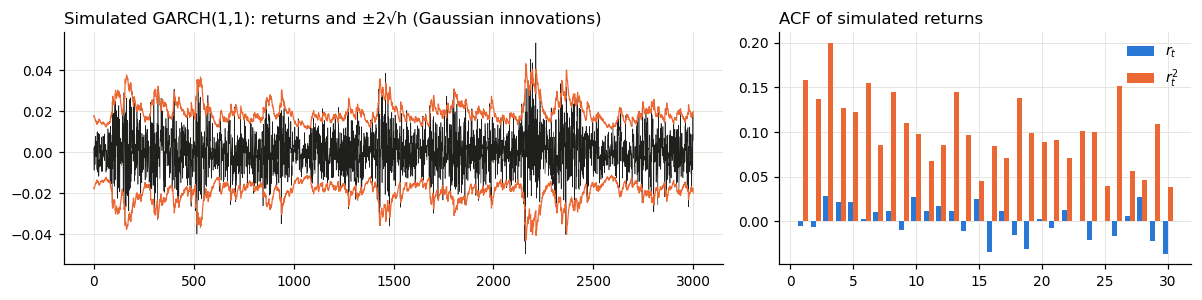

simulated excess kurtosis 1.03 (innovations are Gaussian: 0); scale-mixture prediction 3E[h^2]/E[h]^2 - 3 = 1.00


In [8]:
r_sim, h_sim = garch.simulate(n=3000, seed=11, V=1e-4, alpha=.08, beta=.90)
fig, ax = plt.subplots(1, 2, figsize=(11, 2.8), gridspec_kw={'width_ratios': [1.6, 1]})
ax[0].plot(r_sim, lw=.4, color=INK); ax[0].plot(2 * np.sqrt(h_sim), lw=.8, color=C[1]); ax[0].plot(-2 * np.sqrt(h_sim), lw=.8, color=C[1])
ax[0].set_title('Simulated GARCH(1,1): returns and ±2√h (Gaussian innovations)', loc='left')
ax[1].bar(np.arange(1, 31) - .2, dg.acf(r_sim, 30), width=.4, color=C[0], label='$r_t$')
ax[1].bar(np.arange(1, 31) + .2, dg.acf(r_sim ** 2, 30), width=.4, color=C[1], label='$r_t^2$'); ax[1].legend()
ax[1].set_title('ACF of simulated returns', loc='left'); plt.tight_layout(); plt.show()
print(f'simulated excess kurtosis {pd.Series(r_sim).kurt():.2f} (innovations are Gaussian: 0); '
      f'scale-mixture prediction 3E[h^2]/E[h]^2 - 3 = {fc.mixture_excess_kurtosis(h_sim):.2f}')

### 3.4 The conditional Gaussian likelihood

The joint density of $r_1,\dots,r_n$ factorises sequentially by the **prediction-error decomposition**:
$$p(r_1,\dots,r_n\mid\theta)=\prod_{t=1}^n p(r_t\mid\mathcal F_{t-1},\theta)=\prod_{t=1}^n\frac{1}{\sqrt{2\pi h_t(\theta)}}\exp\!\Big(-\frac{r_t^2}{2h_t(\theta)}\Big),$$
because, given the past, $r_t\sim N(0,h_t)$ and $h_t$ is a deterministic function of the past and $\theta$. The
log-likelihood is
$$\ell(\theta)=-\frac12\sum_{t=1}^n\Big[\log(2\pi)+\log h_t(\theta)+\frac{r_t^2}{h_t(\theta)}\Big],\qquad h_1=V.$$

**Recursive evaluation.** One forward pass computes $h_t$ from $h_{t-1}$ and $r_{t-1}$ and accumulates the term
for day $t$. The cost is $O(n)$ with $O(1)$ memory. The project's version (`garch.loglik_u`) is compiled with numba
and returns $-10^{300}$ for invalid parameters or non-finite variances, so optimisers and samplers reject such
points safely. A plain-Python transcription of the formula (`garch.loglik_reference`) serves as an independent
check. 🟢 *raw data*

In [9]:
r_spy = data.log_returns('SPY'); RR = r_spy.to_numpy()
st = int(r_spy.index.searchsorted(pd.Timestamp('2023-01-01')))    # first forecast day of the 2023 segment
W = 500; train = RR[st - W:st]
print(f'Representative estimation window: SPY, {r_spy.index[st-W].date()} .. {r_spy.index[st-1].date()} (n = {len(train)}); '
      f'first forecast day {r_spy.index[st].date()}')
u_demo = garch.encode(1e-4, .97, .1); garch.loglik_u(train, u_demo)      # first call triggers numba compilation
t0 = time.perf_counter(); ll_fast = garch.loglik_u(train, u_demo); t_fast = time.perf_counter() - t0
t0 = time.perf_counter(); ll_ref = garch.loglik_reference(train, *garch.to_natural(u_demo)); t_ref = time.perf_counter() - t0
check('numba log-likelihood == plain-Python reference', abs(ll_fast - ll_ref) < 1e-8, f'{ll_fast:.6f} vs {ll_ref:.6f}', RAW)
print(f'evaluation time: compiled {t_fast*1e6:.0f} µs, plain Python {t_ref*1e6:.0f} µs')

Representative estimation window: SPY, 2021-01-07 .. 2022-12-30 (n = 500); first forecast day 2023-01-03
PASS  numba log-likelihood == plain-Python reference  [1533.972001 vs 1533.972001]
evaluation time: compiled 33 µs, plain Python 274 µs


**Q B1.** Show that if $p=1$ (IGARCH), the forecast $E[h_{t+k}\mid\mathcal F_t]$ never reverts to a long-run level.
What happens to $V$ in the $u$-parametrisation as $p\to1$ with $\omega$ fixed?

<a id="s4"></a>
## 4. Classical maximum likelihood estimation

> **Experiment card — Classical maximum likelihood.** Each experimental section follows this format: motivation, formulation,
> numerical method, implementation, results, interpretation, limitations.
>
> | Step | This section |
> |---|---|
> | **Motivation** | The classical baseline. Every Bayesian forecast in this project is compared with the MLE plug-in forecast. |
> | **Mathematical formulation** | Maximise $\ell(\theta)=-\tfrac12\sum_t[\log 2\pi+\log h_t(\theta)+r_t^2/h_t(\theta)]$ subject to $\omega>0$, $\alpha,\beta\ge0$, $\alpha+\beta<1$ (§3.4, §4.1). |
> | **Numerical method** | Unconstrained coordinates $u=(\log V,\operatorname{logit}p,\operatorname{logit}q)$; multi-start L-BFGS-B with box bounds and a Powell fallback; compiled recursion (§4.2–4.3). |
> | **Implementation** | `garch.mle_fit`, `garch.loglik_u`, `garch.variance_path`, checked against a plain-Python reference and an independent Nelder–Mead fit (§4.3). |
> | **Results** | A representative SPY fit run live; Hessian conditioning in the two coordinate systems; boundary cases in the 320 refits (§4.3–4.5). |
> | **Interpretation** | Persistence close to one is typical, and the likelihood is flat along the $\alpha+\beta$ ridge. This is why parameter uncertainty is worth studying. |
> | **Limitations** | The cap $p\le0.99909$ binds in 30 of 320 refits; curvature-based standard errors are unreliable near that boundary. |

### 4.1 The estimation problem

$$\hat\theta=\arg\max_{\theta}\ \ell(\theta)\quad\text{subject to}\quad \omega>0,\ \alpha\ge0,\ \beta\ge0,\ \alpha+\beta<1 .$$

There is no closed form, because $h_t(\theta)$ is a nonlinear recursion in $\theta$. The optimisation is harder than
its dimension (3) suggests:

| Challenge | Why it arises |
|---|---|
| **Positivity constraints** | $\omega>0,\ \alpha,\beta\ge0$; unconstrained steps can produce negative or undefined variances |
| **Persistence near one** | daily data typically give $\alpha+\beta\approx0.97$–$0.99$, and the likelihood is often still rising towards the boundary $p=1$ |
| **Numerical conditioning** | $\omega$ is about $10^{-6}$ while $\alpha,\beta$ are about $10^{-1}$; $\alpha$ and $\beta$ are strongly negatively correlated along a ridge $\alpha+\beta\approx$ const |
| **Sensitivity to initialisation** | flat ridges and near-boundary optima can make a local optimiser stop at different points from different starts |
| **Boundary solutions** | if the maximum lies on (or beyond) the edge of the allowed region, the usual asymptotic theory (zero score, Wald standard errors) fails |

### 4.2 The parameter transformation

The project estimates in unconstrained coordinates
$$u=(u_1,u_2,u_3)=(\log V,\ \operatorname{logit}p,\ \operatorname{logit}q),\qquad V=\frac{\omega}{1-\alpha-\beta},\quad p=\alpha+\beta,\quad q=\frac{\alpha}{p},$$
where $\operatorname{logit}x=\log\frac{x}{1-x}$ and $\operatorname{expit}y=1/(1+e^{-y})$.

**Recovering the GARCH parameters.** Inverting each coordinate,
$$V=e^{u_1},\qquad p=\operatorname{expit}(u_2)\in(0,1),\qquad q=\operatorname{expit}(u_3)\in(0,1),$$
and then
$$\alpha=pq,\qquad \beta=p-\alpha=p(1-q),\qquad \omega=V(1-p).$$

**Why this helps.**
- *Every* $u\in\mathbb R^3$ maps to a valid model: $\omega=e^{u_1}(1-p)>0$, $\alpha=pq>0$, $\beta=p(1-q)>0$,
  and $\alpha+\beta=p<1$. The constrained problem becomes an unconstrained one, apart from optional box bounds.
- The coordinates separate the **level** ($V$), the **persistence** ($p$) and the **split** between reaction
  and memory ($q$). This removes most of the $\alpha$–$\beta$ ridge (§4.4).
- $\operatorname{logit}p$ stretches the region near $p=1$: $p=0.99$ is $u_2=4.6$ and $p=0.999$ is $u_2=6.9$. This
  gives the optimiser room to resolve near-integrated estimates.

The MLE is invariant to reparametrisation ($\widehat{g(\theta)}=g(\hat\theta)$), so no Jacobian enters the MLE. For
the Bayesian posterior, the prior is specified directly as a density in $u$ (§5.2), so no Jacobian is needed there
either.

In [10]:
rng0 = np.random.default_rng(0)
U = rng0.normal(0, 4, size=(10_000, 3))                       # arbitrary unconstrained points
nat = np.array([garch.to_natural(u) for u in U])
check('every u in R^3 gives omega>0, alpha,beta>=0, alpha+beta<1',
      bool((nat[:, 0] > 0).all() and (nat[:, 1:] >= 0).all() and (nat[:, 1] + nat[:, 2] < 1).all()), '10,000 random u', RAW)
u_back = np.array([garch.from_natural(*x) for x in nat[(nat[:, 1] > 1e-12) & (nat[:, 2] > 1e-12)][:2000]])
check('u -> (omega, alpha, beta) -> u round trip', np.allclose(u_back, U[(nat[:, 1] > 1e-12) & (nat[:, 2] > 1e-12)][:2000], atol=1e-6), level=RAW)
lo, hi = np.array(garch.MLE_BOUNDS).T
display(pd.DataFrame({'coordinate': ['log V', 'logit p', 'logit q'], 'MLE box bound': [f'[{a:g}, {b:g}]' for a, b in garch.MLE_BOUNDS],
                      'implied natural range': [f'annual vol {np.sqrt(252*np.exp(-15)):.2%} .. {np.sqrt(252*np.exp(-5)):.0%}',
                                                f'p in [{expit(-7):.5f}, {expit(7):.5f}]', f'q in [{expit(-7):.5f}, {expit(7):.5f}]']}))
print(f'persistence cap of the MLE: p <= expit(7) = {garch.P_MAX_MLE:.6f}  (half-life <= {garch.half_life(garch.P_MAX_MLE):.0f} days)')

PASS  every u in R^3 gives omega>0, alpha,beta>=0, alpha+beta<1  [10,000 random u]
PASS  u -> (omega, alpha, beta) -> u round trip


,coordinate,MLE box bound,implied natural range
0,log V,"[-15, -5]",annual vol 0.88% .. 130%
1,logit p,"[-7, 7]","p in [0.00091, 0.99909]"
2,logit q,"[-7, 7]","q in [0.00091, 0.99909]"


persistence cap of the MLE: p <= expit(7) = 0.999089  (half-life <= 760 days)


### 4.3 The optimiser and its safeguards

`garch.mle_fit` (the validated `src.garch.mle_fit`, unchanged) minimises $-\ell(u)$ as follows.
1. **Three starting points**: $(V_0,p,q)\in\{(\widehat{\operatorname{Var}}(r),0.94,0.12),\ (\cdot,0.80,0.20),\ (\cdot,0.98,0.08)\}$, which
   cover moderate, low and high persistence.
2. **L-BFGS-B** from each start, with box bounds $\log V\in[-15,-5]$ and $\operatorname{logit}p,\operatorname{logit}q\in[-7,7]$
   (`maxiter=2000, maxls=50, ftol=1e-12`). L-BFGS-B is a quasi-Newton method that builds a low-rank
   approximation of the inverse Hessian from recent gradients (finite-difference gradients here) and projects steps
   onto the box.
3. **Safeguards.** Invalid objective values are replaced by $10^{100}$. A start that reports failure is never
   silently chosen. If a failed start reaches a materially better objective ($>10^{-5}$) than every successful
   one, a derivative-free **Powell** search is run from both candidates. If the conflict still cannot be resolved,
   the function raises an error instead of returning a doubtful optimum.

🟢 *raw data* — a fresh fit on the representative window, compared with the saved research fit, the original
Milestone 10 fit, and an **independent** Nelder–Mead optimisation of the plain-Python likelihood.

In [11]:
t0 = time.perf_counter(); u1, fit1 = garch.mle_fit(train); t_mle = time.perf_counter() - t0
om1, al1, be1 = garch.to_natural(u1); p1 = al1 + be1; V1 = om1 / (1 - p1)
h_next = garch.next_variance(train, u1)
display(pd.DataFrame(fit1.attempts).rename_axis('attempt').round(6))
display(pd.DataFrame({'value': {
    'omega': om1, 'alpha': al1, 'beta': be1, 'persistence p = alpha+beta': p1, 'q = alpha/p': al1 / p1,
    'long-run variance V': V1, 'long-run ann. vol sqrt(252 V)': np.sqrt(252 * V1), 'half-life (days)': garch.half_life(p1),
    'maximised log-likelihood': -fit1.fun, 'converged (success)': fit1.success, 'method of best fit': fit1.method,
    'Powell fallback used': fit1.fallback_used, 'iterations': fit1.nit, 'at a box bound': bool(np.any(np.isclose(u1, lo, atol=1e-6) | np.isclose(u1, hi, atol=1e-6))),
    'next-day variance h_{T+1}': h_next, 'next-day ann. vol': np.sqrt(252 * h_next), 'seconds': t_mle}}))

,method,success,status,message,objective,iterations
attempt,,,,,,
0,L-BFGS-B,True,0,CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH,-1536.02891,12
1,L-BFGS-B,True,0,CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH,-1536.02891,17
2,L-BFGS-B,True,0,CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH,-1536.02891,11


,value
omega,0.0
alpha,0.05998
beta,0.93179
persistence p = alpha+beta,0.99177
q = alpha/p,0.06048
long-run variance V,0.00014
long-run ann. vol sqrt(252 V),0.18469
half-life (days),83.91907
maximised log-likelihood,1536.02891
converged (success),True


In [12]:
nll_ref = lambda u: -garch.loglik_reference(train, *garch.to_natural(u))
fit_nm = minimize(nll_ref, garch.encode(np.var(train), .94, .12), method='Nelder-Mead',
                  options={'xatol': 1e-8, 'fatol': 1e-10, 'maxiter': 20000})
saved_fit = STORE.fits('SPY', 500, 'test').iloc[0]
m10 = pd.read_csv(cfg.SAVED_M10 / 'SPY_500_moderate' / 'fit_diagnostics.csv').iloc[0]
display(pd.DataFrame({'fresh mle_fit': [-fit1.fun, p1], 'independent Nelder-Mead': [-fit_nm.fun, expit(fit_nm.x[1])],
                      'saved research fit': [saved_fit.mle_loglik, saved_fit.mle_persistence],
                      'original Milestone 10': [-m10.mle_objective, m10.mle_persistence]}, index=['log-likelihood', 'persistence']))
check('fresh MLE log-likelihood == saved research fit', abs(-fit1.fun - saved_fit.mle_loglik) < 1e-8, level=RAW)
check('fresh MLE log-likelihood == original Milestone 10 fit', abs(-fit1.fun + m10.mle_objective) < 1e-8, level=RAW)
check('independent Nelder-Mead agrees (log-lik within 1e-5)', abs(fit_nm.fun - fit1.fun) < 1e-5, f'{fit_nm.fun - fit1.fun:+.1e}', RAW)

,fresh mle_fit,independent Nelder-Mead,saved research fit,original Milestone 10
log-likelihood,1536.02891,1536.02891,1536.02891,1536.02891
persistence,0.99177,0.99177,0.99177,0.99177


PASS  fresh MLE log-likelihood == saved research fit
PASS  fresh MLE log-likelihood == original Milestone 10 fit
PASS  independent Nelder-Mead agrees (log-lik within 1e-5)  [-3.2e-10]


**The fitted variance path, three ways.** With $\hat u$ fixed, we filter the window plus the first 63 forecast days
using (i) the plain-Python reference loop, (ii) the validated filter `garch.variance_path`, and (iii) the saved
research column `variance_mle`. 🟢 *raw data* vs 🔵 *saved forecasts*

PASS  reference recursion == validated filter  [max rel diff 0.0e+00]
PASS  fresh filter == saved variance_mle (63 days)  [max rel diff 8.5e-13]
PASS  next_variance(train) == first forecast row


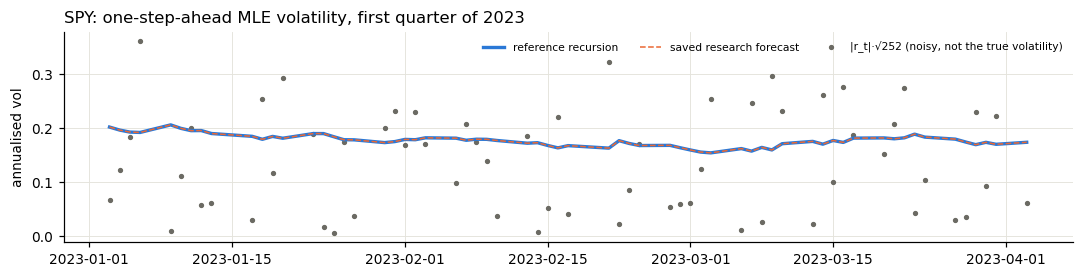

In [13]:
f_spy = STORE.daily('SPY', 500, 'test')                       # saved forecasts, 2023-01-03 onward
local = RR[st - W: st + 63]                                   # estimation window + first 63-day forecast block
h_ref = garch.variance_path_reference(local, W, om1, al1, be1)
h_mle = garch.variance_path(local, W, u1)
h_saved = f_spy.variance_mle.to_numpy()[:63]
check('reference recursion == validated filter', np.max(np.abs(h_ref / h_mle - 1)) < 1e-12, f'max rel diff {np.max(np.abs(h_ref/h_mle-1)):.1e}', RAW)
check('fresh filter == saved variance_mle (63 days)', np.max(np.abs(h_mle / h_saved - 1)) < 1e-10, f'max rel diff {np.max(np.abs(h_mle/h_saved-1)):.1e}', RAW)
check('next_variance(train) == first forecast row', np.isclose(h_next, h_saved[0], rtol=1e-12), level=RAW)
fig, ax = plt.subplots(figsize=(10, 2.6))
ax.plot(f_spy.date[:63], np.sqrt(252 * h_ref), color=C[0], lw=2.2, label='reference recursion')
ax.plot(f_spy.date[:63], np.sqrt(252 * h_saved), color=C[1], lw=1, ls='--', label='saved research forecast')
ax.scatter(f_spy.date[:63], np.abs(local[W:]) * np.sqrt(252), s=6, color=MUTED, label='|r_t|·√252 (noisy, not the true volatility)')
ax.set_ylabel('annualised vol'); ax.legend(fontsize=7, ncol=3); ax.set_title('SPY: one-step-ahead MLE volatility, first quarter of 2023', loc='left')
plt.tight_layout(); plt.show()

### 4.4 Conditioning: why the coordinates matter

The curvature of $-\ell$ at the optimum (the observed information) determines both how well conditioned the
optimisation is and the classical standard errors. We compute it by central finite differences in $u$ and in
natural coordinates $(\omega,\alpha,\beta)$, and draw the log-likelihood surface in the $(\alpha,\beta)$ plane with
$V$ held at its estimate. 🟢 *raw data*

,condition number of Hessian,implied corr of first two coordinates,pair
"u = (log V, logit p, logit q)",1.99501e+01,0.2250,"(log V, logit p)"
"(omega, alpha, beta)",1.71227e+10,-0.9805,"(alpha, beta)"


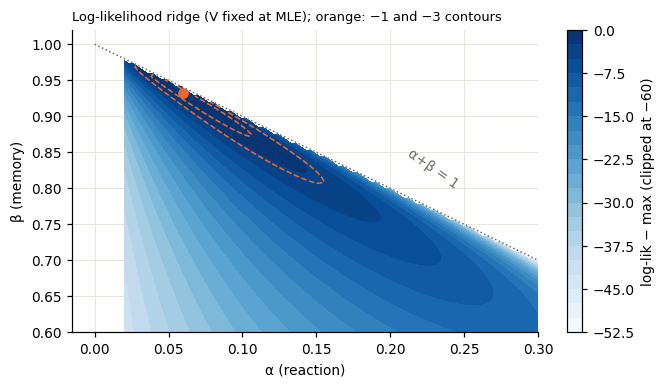

In [14]:
H_u = N.fd_hessian(lambda u: -garch.loglik_u(train, u), u1, h=1e-3)
x_nat = np.array([om1, al1, be1])
H_nat = N.fd_hessian(lambda x: -garch.loglik_reference(train, *x), x_nat, h=1e-7)   # tiny step: omega ~ 1e-6
cor = lambda H: (lambda S: S / np.sqrt(np.outer(np.diag(S), np.diag(S))))(np.linalg.inv(H))
display(pd.DataFrame({'condition number of Hessian': [np.linalg.cond(H_u), np.linalg.cond(H_nat)],
                      'implied corr of first two coordinates': [cor(H_u)[0, 1], cor(H_nat)[1, 2]],
                      'pair': ['(log V, logit p)', '(alpha, beta)']}, index=['u = (log V, logit p, logit q)', '(omega, alpha, beta)']).round(4))
A_, B_ = np.meshgrid(np.linspace(.02, .30, 90), np.linspace(.60, .995, 90))
LL = np.full(A_.shape, np.nan)
for i in range(A_.shape[0]):
    for j in range(A_.shape[1]):
        if A_[i, j] + B_[i, j] < .9995:
            LL[i, j] = garch.loglik_u(train, garch.encode(V1, A_[i, j] + B_[i, j], A_[i, j] / (A_[i, j] + B_[i, j])))
fig, ax = plt.subplots(figsize=(6.2, 3.6))
cs = ax.contourf(A_, B_, np.clip(LL - np.nanmax(LL), -60, 0), levels=24, cmap='Blues')
ax.contour(A_, B_, LL - np.nanmax(LL), levels=[-3, -1], colors=[C[1]], linewidths=1)
ax.plot(al1, be1, 'o', color=C[1]); ax.plot([0, .3], [1, .7], color=MUTED, ls=':', lw=1); ax.text(.21, .80, 'α+β = 1', color=MUTED, rotation=-35)
ax.set_xlabel('α (reaction)'); ax.set_ylabel('β (memory)'); plt.colorbar(cs, label='log-lik − max (clipped at −60)')
ax.set_title('Log-likelihood ridge (V fixed at MLE); orange: −1 and −3 contours', loc='left', fontsize=8.5)
plt.tight_layout(); plt.show()

**Interpretation.**
- In natural coordinates the Hessian is extremely ill-conditioned, because $\omega$ is six orders of magnitude
  smaller than $\alpha,\beta$. The implied correlation between $\hat\alpha$ and $\hat\beta$ is strongly negative,
  the classic ridge: the data pin down $\alpha+\beta$ much better than the split between them.
- In $u$ coordinates the condition number drops by many orders of magnitude, and the coordinates are much closer to
  orthogonal.
- The contour plot shows the elongated ridge running parallel to the stationarity line $\alpha+\beta=1$. A 1-unit
  drop in log-likelihood, about one standard error, spans a wide range of $(\alpha,\beta)$ pairs. That spread is
  what the Bayesian posterior of §5 quantifies.

### 4.5 Boundary solutions in the full experiment

The bound $\operatorname{logit}p\le7$ caps the MLE persistence at $p\le\operatorname{expit}(7)=0.99909$. On equity and
bond data the likelihood is sometimes still rising towards $p=1$, and L-BFGS-B then stops **on the bound** and
reports success. 🔵 *saved forecasts* (fit logs of all 320 refits) and ⚪ *artifact* (research audit of the bound).

PASS  MLE on the persistence bound in 30 of 320 refits (report §2.1)  [30 of 320]


segment  ext      test     
window  500  1000 500  1000
asset                      
GLD        5    3    0    0
QQQ        0    0    5    0
SPY        0    0    2    0
TLT        4    3    4    4

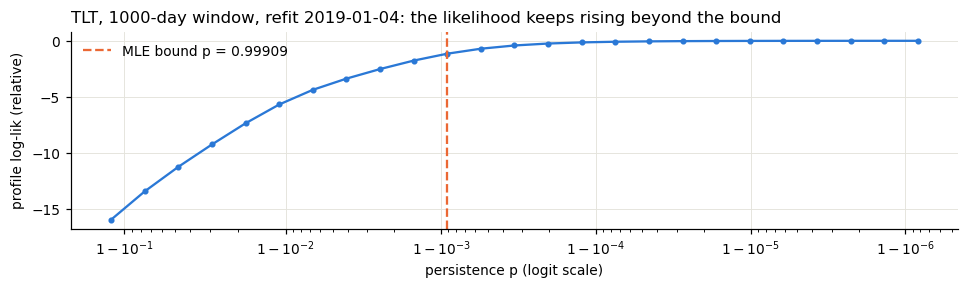

n_refits_at_bound_2017_2026    25.00000
max_loglik_gain                 1.15036
median_abs_next_var_change      0.04903
max_abs_next_var_change         0.09703
Name: research audit of relaxing the bound (continuous 2017–26 refit schedule), dtype: float64

In [15]:
fits_all = pd.concat([STORE.fits(a, w, s).assign(asset=a, window=w, segment=s) for s in SEGS for a in ASSETS for w in WINDOWS])
n_bound = int(fits_all.mle_at_bound.sum())
check('MLE on the persistence bound in 30 of 320 refits (report §2.1)', n_bound == 30 and len(fits_all) == 320, f'{n_bound} of {len(fits_all)}')
display(fits_all.pivot_table(index='asset', columns=['segment', 'window'], values='mle_at_bound', aggfunc='sum'))
case = fits_all[fits_all.mle_at_bound & (fits_all.asset == 'TLT') & (fits_all.window == 1000)].iloc[0]
r_tlt = data.log_returns('TLT'); i0 = int(r_tlt.index.searchsorted(pd.Timestamp(case.refit_date)))
tr = r_tlt.to_numpy()[i0 - 1000:i0]
grid = np.linspace(2, 14, 25); prof = []; x0 = np.array([np.log(np.var(tr)), -2.0])
for g in grid:                                   # profile likelihood: maximise over (log V, logit q) at each logit p
    res = minimize(lambda z: -garch.loglik_u(tr, np.array([z[0], g, z[1]])), x0, method='Nelder-Mead',
                   options={'xatol': 1e-7, 'fatol': 1e-9, 'maxiter': 4000}); x0 = res.x; prof.append(-res.fun)
prof = np.array(prof)
fig, ax = plt.subplots(figsize=(9, 2.7))
ax.plot(expit(grid), prof - prof.max(), 'o-', ms=3, color=C[0]); ax.axvline(garch.P_MAX_MLE, color=C[1], ls='--', label='MLE bound p = 0.99909')
ax.set_xscale('logit'); ax.set_xlabel('persistence p (logit scale)'); ax.set_ylabel('profile log-lik (relative)')
ax.set_title(f'TLT, 1000-day window, refit {case.refit_date}: the likelihood keeps rising beyond the bound', loc='left'); ax.legend()
plt.tight_layout(); plt.show()
aud = json.loads((cfg.PROJECT / 'agent_research/results/audit_checks.json').read_text())['mle_boundary']
display(pd.Series(aud, name='research audit of relaxing the bound (continuous 2017–26 refit schedule)'))

**Interpretation and limitations.**
- **Where it happens.** In 30 of the 320 refits the MLE stops at the bound, mostly for TLT and SPY.
- **What relaxing the bound would change.** The research audit used one continuous 2017–2026 refit schedule and
  found 25 such cases. Relaxing the bound would raise the log-likelihood by at most 1.15 units, but would move
  next-day variance by a median of about 5% (maximum about 10%).
- **Why the bound is kept.** It is part of the estimator's definition, so changing it would change the classical
  benchmark. It is therefore **kept**, and this is treated as a limitation.
- **Consequence for the comparison.** In boundary refits, part of any Bayes-versus-MLE difference is
  *regularisation versus an ad-hoc truncation*, not parameter uncertainty as such.
- **Initialisation.** On the representative window, all three L-BFGS-B starts reach the same optimum (the attempts
  table above). The Powell fallback is needed only rarely in the full experiment.
- **Inference at a boundary.** When $\hat u$ lies on a bound, the score is not zero, and Wald/Laplace standard
  errors from the Hessian are unreliable. This motivates a full posterior (§5) and the Laplace comparison (§7).

**Q C1.** Why is the Hessian-based (Laplace / Wald) standard error unreliable when $\hat u$ is on a bound?

<a id="s5"></a>
## 5. Bayesian inference for GARCH

> **Experiment card — Bayesian inference.** Each experimental section follows this format: motivation, formulation,
> numerical method, implementation, results, interpretation, limitations.
>
> | Step | This section |
> |---|---|
> | **Motivation** | Represent parameter uncertainty explicitly instead of treating $\hat\theta$ as exact. |
> | **Mathematical formulation** | Posterior $p(u\mid r)\propto L(u\mid r)\,p(u)$ with independent normal priors on $u$ (§5.1–5.2). |
> | **Numerical method** | Random-walk Metropolis: 4 over-dispersed chains, 2,500 adaptive warm-up iterations (proposal then frozen), 4,000 retained draws per chain (§5.3). |
> | **Implementation** | `bayes.reliable_bayes_fit`, `bayes.diagnostics`; a short teaching sampler reproduces the posterior mean within Monte Carlo error (§5.4). |
> | **Results** | A representative fit run live with the research seed; trace, autocorrelation, rank-normalised $\hat R$, bulk/tail ESS and MCSE; convergence over all 320 refits (§5.4–5.8). |
> | **Interpretation** | The posterior is well identified and close to the MLE in this window; its spread is what the forecasts of §6 integrate over. |
> | **Limitations** | Monte Carlo and platform variability (§5.7); 4 of 320 refits marginally miss the strict rule; only Gaussian GARCH receives a Bayesian treatment. |

### 5.1 From likelihood to posterior

For data $r_{1:T}$ and parameters $\theta$ (here $u$), Bayes' theorem gives
$$p(\theta\mid r_{1:T})=\frac{p(r_{1:T}\mid\theta)\,p(\theta)}{p(r_{1:T})}\ \propto\ \underbrace{p(r_{1:T}\mid\theta)}_{\text{likelihood }e^{\ell(\theta)}}\ \underbrace{p(\theta)}_{\text{prior}}.$$

- **Likelihood vs posterior.** The likelihood is a function of $\theta$ for fixed data and is not a probability
  density in $\theta$. The posterior is one: it states which parameter values are plausible after seeing the data,
  given the prior.
- **Why parameter uncertainty matters.** A plug-in forecast $h_{T+1}(\hat\theta)$ treats $\hat\theta$ as exact. With
  500–1,000 noisy daily returns and persistence near 1, plausible values of $p$ range over, say, 0.95–0.995 (§4.4),
  with half-lives from 14 to 140 days. The Bayesian forecast averages over that range (§6).
- **Two kinds of uncertainty.**
  - *Parameter uncertainty*: what we do not know about $\theta$. It shrinks as $T$ grows.
  - *Future return uncertainty*: given $\theta$, $r_{T+1}=\sqrt{h_{T+1}}z_{T+1}$ is still random with variance
    $h_{T+1}$. It never disappears.

  The predictive distribution combines both (§6.2). Typically the second dominates by far.
- **Why numerical methods.** The normalising constant $p(r_{1:T})=\int e^{\ell(\theta)}p(\theta)\,d\theta$ and all
  posterior expectations are integrals of a likelihood defined by a nonlinear recursion. There is no conjugate
  prior and no closed form. In three dimensions quadrature would be feasible for one fit but costly for 320, so the
  project uses Markov chain Monte Carlo (MCMC), cross-checked against importance sampling (§5.6).

### 5.2 The prior

The project's **moderate** prior is a product of independent Gaussians on the unconstrained coordinates:
$$\log V\sim N(\log10^{-4},\,1.5^2),\qquad \operatorname{logit}p\sim N(\operatorname{logit}0.80,\,1.5^2),\qquad \operatorname{logit}q\sim N(\operatorname{logit}0.10,\,1.5^2).$$
- $V=10^{-4}$ corresponds to 15.9% annual volatility. A prior sd of 1.5 on $\log V$ spans annual volatility from
  about 7.5% to 34% at $\pm1$ sd (volatility scales as $e^{u_1/2}$).
- The prior on $p$ is centred at 0.80 but wide on the logit scale, so it still allows 0.99. It deliberately puts
  substantial mass away from 1 and therefore **shrinks near-integrated estimates** away from the boundary.
- $q=\alpha/p$ centred at 0.10 says that most persistence is memory ($\beta$) rather than reaction ($\alpha$).
- Because the density is defined directly on $u$, the posterior $\pi(u\mid r)\propto e^{\ell(u)}\pi(u)$ needs **no
  Jacobian**. The prior is *not* uniform in $(\omega,\alpha,\beta)$.
- **Robustness.** A *broad* prior with $\operatorname{logit}p\sim N(0,3^2)$ was also run in the research; see §15.5.

🟢 *raw data* — the prior's implications for the natural parameters, by simulation.

In [16]:
prior = bayes.PRIORS['moderate']
print('prior mean of u:', prior.mean_u.round(3), '  prior sd of u:', prior.sd_u)
u_prior = np.random.default_rng(1).normal(prior.mean_u, prior.sd_u, size=(200_000, 3))
pri = bayes.natural_draws(u_prior)
display(pri[['persistence', 'alpha', 'beta', 'long_run_ann_vol', 'half_life_days']].quantile([.05, .25, .5, .75, .95]).round(4)
        .rename_axis('prior quantile'))

prior mean of u: [-9.21   1.386 -2.197]   prior sd of u: [1.5 1.5 1.5]


,persistence,alpha,beta,long_run_ann_vol,half_life_days
prior quantile,,,,,
0.05,0.2543,0.0054,0.1716,0.0465,0.5063
0.25,0.5923,0.0250,0.4366,0.0958,1.3232
0.50,0.8002,0.0678,0.6454,0.1584,3.1100
0.75,0.9163,0.1642,0.8034,0.2622,7.9303
0.95,0.9792,0.4341,0.9263,0.5430,32.9466


### 5.3 The random-walk Metropolis algorithm

**Target.** $\pi(u)\propto e^{\ell(u)}\pi_0(u)$, known up to a constant: the function `prior.log_posterior(u, r)`.

**Algorithm (one chain).** Given the current state $u^{(i)}$:
1. Propose $u^\star=u^{(i)}+s\,L\,\varepsilon$, with $\varepsilon\sim N(0,I_3)$, $LL^\top=\Sigma$ a proposal
   covariance and $s$ a scale.
2. Accept with probability
   $$a(u^{(i)},u^\star)=\min\Big\{1,\ \frac{\pi(u^\star)}{\pi(u^{(i)})}\Big\}=\min\big\{1,\ \exp[\log\pi(u^\star)-\log\pi(u^{(i)})]\big\}.$$
   The Gaussian proposal is symmetric, so the proposal densities cancel and the unknown normalising constant
   cancels too.
3. If accepted, $u^{(i+1)}=u^\star$; otherwise $u^{(i+1)}=u^{(i)}$. The repeated value is kept, not skipped.

This kernel satisfies detailed balance, $\pi(u)K(u,u')=\pi(u')K(u',u)$ (§15.4). The chain therefore has $\pi$ as
its stationary distribution, and averages along it converge to posterior expectations.

**The project's sampler** (`bayes.reliable_bayes_fit`, the validated `src.reliable_mcmc` unchanged):

| Element | Setting |
|---|---|
| mode and local covariance | BFGS on $-\log\pi$ from the MLE gives the MAP; $\Sigma_0$ = finite-difference inverse Hessian, eigenvalues clipped to $[0.02,10^8]$ |
| chains | 4, started **over-dispersed** at $u_{\text{MAP}}+N(0,3\Sigma_0)$ |
| warm-up | 2,500 iterations. Every 100: $\log s\leftarrow\log s+(\hat a-0.234)\min(0.65,\,b^{-1/2})$ ($b$ = batch number); from iteration 900 on, $\Sigma$ is the empirical covariance of the warm-up history |
| sampling | adaptation **frozen**; 4,000 retained draws per chain (16,000 total), no thinning |
| target acceptance | 23.4%, the asymptotically optimal rate for random-walk Metropolis (Roberts, Gelman & Gilks, 1997) |
| initial scale | $s=2.38/\sqrt d$ (Haario et al., 2001) |
| convergence rule | rank-normalised split $\hat R<1.01$ and bulk and tail ESS $\ge400$ for $u$ and $(V,p,q,\omega,\alpha,\beta)$ |
| seeds | refit $i$ of a job uses seed $s_0+173i$ (starting points), chain $k$ uses that seed $+1000+97k$ |

Adapting the proposal while sampling would break the Markov property. Freezing it after warm-up makes the retained
draws an ordinary, valid Metropolis chain.

**Pseudocode** (warm-up adaptation omitted):
```
u <- start;  lp <- log_post(u)
for i in 1..n:
    u_star <- u + s * L @ normal(3)
    lp_star <- log_post(u_star)
    if log(uniform()) < lp_star - lp:  u, lp <- u_star, lp_star
    keep u
```
The teaching implementation in §5.5 is exactly this loop.

### 5.4 A representative Bayesian fit

🟢 *raw data* — the same window as §4, with the **same seed as the research run** (2026, the first refit of the
2023 segment).

In [17]:
t0 = time.perf_counter()
chains, meta = bayes.reliable_bayes_fit(train, u1, n_chains=4, warmup=2500, draws=4000, seed=2026, log_density=prior.log_posterior)
t_mcmc = time.perf_counter() - t0
diag, passed = bayes.diagnostics(chains)
flat = chains.reshape(-1, 3)
print(f'MCMC: 4 chains x (2,500 warm-up + 4,000 retained) = {4*6500:,} log-posterior evaluations of a {len(train)}-day recursion, '
      f'{t_mcmc:.1f} s; acceptance per chain {[round(m["acceptance"], 3) for m in meta]}')
check('posterior mean persistence == saved research fit (same seed, this platform)',
      abs(expit(flat[:, 1]).mean() - saved_fit.post_mean_persistence) < 1e-12, f'{expit(flat[:,1]).mean():.6f}', RAW)
check('strict convergence rule passed, as in the saved fit', passed == bool(saved_fit.convergence_pass), level=RAW)
post = bayes.posterior_summary(chains)
post['MLE'] = [om1, al1, be1, p1, V1, np.sqrt(252 * V1), al1 / p1, garch.half_life(p1)]
display(post.round(5))

MCMC: 4 chains x (2,500 warm-up + 4,000 retained) = 26,000 log-posterior evaluations of a 500-day recursion, 0.2 s; acceptance per chain [0.221, 0.237, 0.235, 0.268]
PASS  posterior mean persistence == saved research fit (same seed, this platform)  [0.982882]
PASS  strict convergence rule passed, as in the saved fit


,mean,sd,q05,q50,q95,MLE
omega,0.00000,0.00000,0.00000,0.00000,0.00001,0.00000
alpha,0.08274,0.03103,0.04278,0.07800,0.14036,0.05998
beta,0.90014,0.03810,0.82997,0.90688,0.94875,0.93179
persistence,0.98288,0.01057,0.96220,0.98509,0.99523,0.99177
long_run_variance,0.00014,0.00004,0.00008,0.00013,0.00022,0.00014
long_run_ann_vol,0.18515,0.02807,0.14623,0.18260,0.23602,0.18469
q,0.08439,0.03230,0.04318,0.07912,0.14424,0.06048
half_life_days,60.63265,56.85500,17.98960,46.14768,145.07607,83.91907


**Interpretation.**
- The posterior mean persistence is pulled from the MLE towards the prior centre. This is **shrinkage**. Its
  90% interval still lies well above the prior centre 0.80, so the data dominate at $n=500$.
- The half-life is the most uncertain derived quantity: its posterior is long right-skewed, because
  $\log(1/2)/\log p$ explodes as $p\to1$.
- The long-run volatility $\sqrt{252V}$ is also quite uncertain. Five hundred days contain only a few independent
  volatility "episodes".

### 5.5 Convergence diagnostics

| Diagnostic | Definition | What it detects |
|---|---|---|
| **trace plot** | draws against iteration, one line per chain | chains stuck, trending, or exploring different regions |
| **autocorrelation** $\rho_k$ | correlation of draws $k$ steps apart | slow mixing; high $\rho_k$ means few effectively independent draws |
| **effective sample size** | $\text{ESS}=\dfrac{mn}{1+2\sum_{k\ge1}\rho_k}$ ($m$ chains of length $n$) | the number of independent draws with the same Monte Carlo precision |
| **rank-normalised split $\hat R$** | split each chain in half, rank-normalise all draws, compare between- and within-chain variance: $\hat R=\sqrt{\widehat{\operatorname{var}}^+/W}$ (Vehtari et al., 2021) | non-convergence; $\hat R\to1$ when all chains sample the same distribution |
| **bulk / tail ESS** | ESS of rank-normalised draws / of the 5% and 95% quantile indicators | precision of central summaries / of interval endpoints |
| **Monte Carlo standard error** | $\text{MCSE}(\bar g)\approx\operatorname{sd}(g)/\sqrt{\text{ESS}}$ | the numerical error of a posterior estimate, separate from posterior uncertainty |

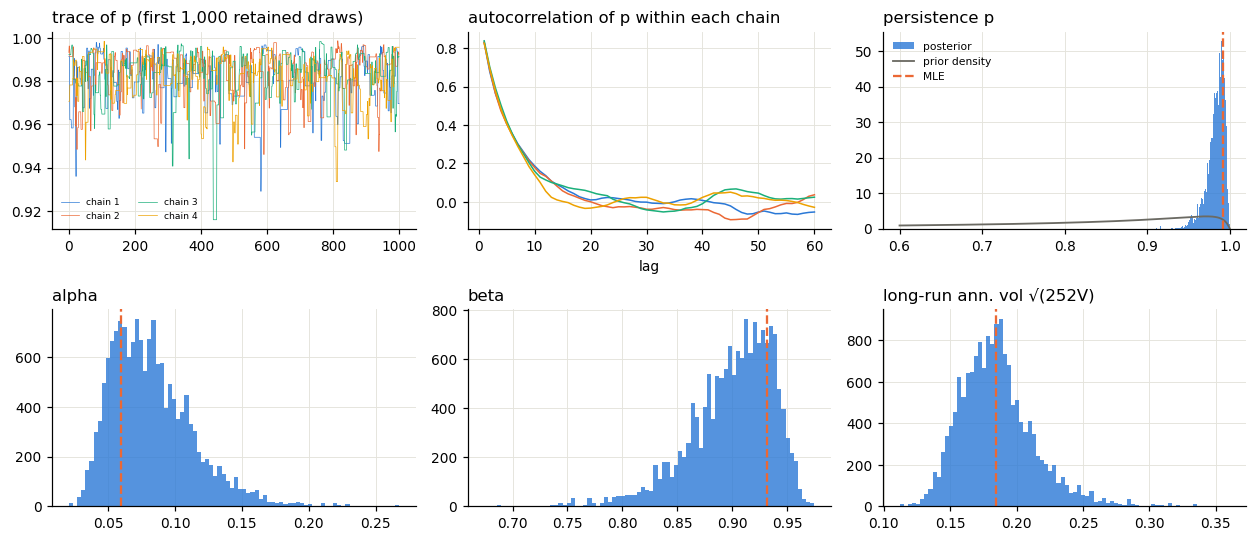

,posterior mean,posterior sd,MCSE(mean),MCSE(q90),ESS bulk,ESS tail,R-hat
p,0.98288,0.01057,2.74000e-04,2.31000e-04,1375.32307,1696.94251,1.00259
alpha,0.08274,0.03103,8.30000e-04,1.84800e-03,1325.54588,1822.62192,1.00356
beta,0.90014,0.03810,1.01800e-03,8.61000e-04,1358.19806,1952.84419,1.00344
V,0.00014,0.00005,1.00000e-06,3.00000e-06,1459.10156,1954.05248,1.00178


In [18]:
import arviz as az
V_, p_, q_ = np.exp(chains[:, :, 0]), expit(chains[:, :, 1]), expit(chains[:, :, 2])
fig, ax = plt.subplots(2, 3, figsize=(11.5, 5))
for k in range(4):
    ax[0, 0].plot(p_[k, :1000], lw=.45, color=C[k], label=f'chain {k+1}')
    ax[0, 1].plot(np.arange(1, 61), dg.acf(p_[k], 60), color=C[k], lw=1)
ax[0, 0].set_title('trace of p (first 1,000 retained draws)', loc='left'); ax[0, 0].legend(fontsize=6, ncol=2)
ax[0, 1].set_title('autocorrelation of p within each chain', loc='left'); ax[0, 1].set_xlabel('lag')
pp = np.linspace(.6, .9995, 400)
ax[0, 2].hist(p_.ravel(), bins=80, density=True, color=C[0], alpha=.8, label='posterior')
ax[0, 2].plot(pp, norm.pdf(logit(pp), prior.mean_u[1], prior.sd_u[1]) / (pp * (1 - pp)), color=MUTED, lw=1.2, label='prior density')
ax[0, 2].axvline(p1, color=C[1], ls='--', label='MLE'); ax[0, 2].set_title('persistence p', loc='left'); ax[0, 2].legend(fontsize=7)
for a_, vals, name in [(ax[1, 0], p_ * q_, 'alpha'), (ax[1, 1], p_ * (1 - q_), 'beta'), (ax[1, 2], np.sqrt(252 * V_), 'long-run ann. vol √(252V)')]:
    a_.hist(vals.ravel(), bins=80, color=C[0], alpha=.8); a_.set_title(name, loc='left')
ax[1, 0].axvline(al1, color=C[1], ls='--'); ax[1, 1].axvline(be1, color=C[1], ls='--'); ax[1, 2].axvline(np.sqrt(252 * V1), color=C[1], ls='--')
plt.tight_layout(); plt.show()
sc = lambda x: float(np.ravel(x)[0])
mc = pd.DataFrame({nm: {'posterior mean': v.mean(), 'posterior sd': v.std(), 'MCSE(mean)': sc(az.mcse(v, method='mean')),
                        'MCSE(q90)': sc(az.mcse(v, method='quantile', prob=.9)), 'ESS bulk': diag.loc[nm, 'ess_bulk'],
                        'ESS tail': diag.loc[nm, 'ess_tail'], 'R-hat': diag.loc[nm, 'r_hat']}
                   for nm, v in [('p', p_), ('alpha', p_ * q_), ('beta', p_ * (1 - q_)), ('V', V_)]}).T
display(mc.round(6))

**Reading the diagnostics.** The four chains overlap in the trace plot and are indistinguishable. The
autocorrelation of $p$ decays within a few dozen iterations, typical of random-walk Metropolis in three dimensions.
Thousands of effective draws remain from 16,000. $\hat R$ is essentially 1. The Monte Carlo standard error of the
posterior mean of $p$ is two orders of magnitude smaller than its posterior sd, so the numerical error is
negligible next to the statistical uncertainty.

**Teaching implementation.** Below, the pseudocode of §5.3 is written out (about ten lines) and run for one chain
with the *final* proposal covariance adapted by the production sampler. It targets the same posterior, so it should
agree with the production result to within Monte Carlo error. It is **not** used for any reported result.
🟢 *raw data*

In [19]:
def rwm(log_post, u0, prop_cov, n, rng):
    L_ = np.linalg.cholesky(prop_cov); u = np.array(u0, float); lp = log_post(u); out = np.empty((n, len(u))); acc = 0
    for i in range(n):
        u_star = u + L_ @ rng.standard_normal(len(u))          # symmetric Gaussian random walk
        lp_star = log_post(u_star)
        if np.log(rng.random()) < lp_star - lp:                 # Metropolis acceptance
            u, lp, acc = u_star, lp_star, acc + 1
        out[i] = u                                               # repeated state is kept on rejection
    return out, acc / n

t0 = time.perf_counter()
toy, acc = rwm(lambda u: prior.log_posterior(u, train), flat.mean(0), meta[0]['proposal_cov'], 12_000, np.random.default_rng(5))
toy = toy[2000:]                                                 # discard burn-in
p_toy = expit(toy[:, 1]); ess_toy = float(az.ess(p_toy[None, :]))
mcse_toy = p_toy.std() / np.sqrt(ess_toy); diff = p_toy.mean() - p_.mean()
print(f'teaching sampler: acceptance {acc:.3f}, {time.perf_counter()-t0:.1f} s, ESS(p) {ess_toy:.0f}; '
      f'posterior mean p {p_toy.mean():.5f} vs production {p_.mean():.5f} (difference {diff:+.5f}, MCSE {mcse_toy:.5f})')
check('teaching Metropolis sampler agrees with production MCMC (|diff| < 4 MCSE)', abs(diff) < 4 * np.hypot(mcse_toy, mc.loc['p', 'MCSE(mean)']), level=RAW)

teaching sampler: acceptance 0.235, 0.1 s, ESS(p) 991; posterior mean p 0.98335 vs production 0.98288 (difference +0.00047, MCSE 0.00034)
PASS  teaching Metropolis sampler agrees with production MCMC (|diff| < 4 MCSE)


### 5.6 Independent validation of the sampler

The research audit compared MCMC with an independent **importance sampler** for four representative fits.
Importance sampling draws from a wide proposal and reweights by the posterior, so it shares no Markov-chain
machinery with MCMC. ⚪ *artifact*

In [20]:
isamp = pd.DataFrame(json.loads((cfg.PROJECT / 'agent_research/results/audit_checks.json').read_text())['mcmc_vs_importance_sampling'])
display(isamp.round(5))
check('MCMC vs importance sampling: next-day variance mean and q90 within 0.3% (report §2.2)',
      round(isamp[['next_var_mean_rel_diff', 'next_var_q90_rel_diff']].abs().max().max(), 3) <= .003,
      f"max |rel diff| {isamp[['next_var_mean_rel_diff', 'next_var_q90_rel_diff']].abs().max().max():.4%}", ART)

,asset,window,date,is_ess,post_mean_p_mcmc,post_mean_p_is,next_var_mean_rel_diff,next_var_q90_rel_diff
0,SPY,500,2023-01-03,39688.36425,0.98312,0.98311,-0.00105,-0.00303
1,TLT,500,2023-01-03,36535.45835,0.98308,0.98288,-0.00071,-0.00035
2,GLD,500,2023-01-03,37776.10080,0.61032,0.61012,0.00126,-0.00123
3,QQQ,1000,2020-03-02,40713.45476,0.93692,0.93661,-0.00095,-0.00098


PASS  MCMC vs importance sampling: next-day variance mean and q90 within 0.3% (report §2.2)  [max |rel diff| 0.3031%]


### 5.7 Monte Carlo variability across seeds and platforms

MCMC estimates are Monte Carlo averages, with error of order $\operatorname{sd}(g)/\sqrt{\text{ESS}}$. A different
seed gives a different but equally valid sample. In addition, the chains' *starting points* come from
`Generator.multivariate_normal`, whose output depends on the linear-algebra backend (an SVD), so the same seed can
produce different chains on different machines. In the research audit, a same-seed rerun on another machine changed
Bayesian variance quantiles by 0.5–1.7%, and two refits that had passed the strict diagnostics failed them marginally
($\hat R=1.010$–$1.011$). Classical quantities reproduce to about $10^{-12}$ on any platform.

🟢 *raw data* (a second seed) and ⚪ *artifact* (the research run's three-seed study).

In [21]:
rng_sub = np.random.default_rng(2026)                            # the research protocol's subsample of M = 300 draws
us = flat[rng_sub.choice(len(flat), size=300, replace=False)]
Hd = fc.variance_draws(local, W, us)                             # (300 draws, 63 days)
ch11, _ = bayes.reliable_bayes_fit(train, u1, seed=11, log_density=prior.log_posterior)
f11 = ch11.reshape(-1, 3); H11 = fc.variance_draws(local, W, f11[np.random.default_rng(11).choice(len(f11), 300, replace=False)])
s26, s11 = fc.predictive_summary(Hd), fc.predictive_summary(H11)
print(f'seed 2026 vs seed 11: posterior mean p {p_.mean():.5f} vs {expit(f11[:, 1]).mean():.5f}; max relative difference over 63 days: '
      f'integrated variance {np.max(np.abs(s11["integrated"]/s26["integrated"]-1)):.2%}, upper-90 variance {np.max(np.abs(s11["q90"]/s26["q90"]-1)):.2%}')
sp = pd.read_csv(cfg.SAVED_PRIMARY / 'seed_prior_sensitivity.csv')
rng_sh = sp[(sp.prior == 'moderate') & (sp.segment == 'test')].groupby(['asset', 'window']).sharpe_upper90.agg(lambda s: s.max() - s.min())
print('Range of the Bayes upper-90 strategy Sharpe ratio across 3 MCMC seeds (2023–26), per configuration:')
display(rng_sh.unstack().round(4))
check('upper-90 Sharpe varies by at most 0.010 across seeds (report App. B)', rng_sh.max() <= 0.0105, f'max {rng_sh.max():.4f}', ART)

seed 2026 vs seed 11: posterior mean p 0.98288 vs 0.98342; max relative difference over 63 days: integrated variance 2.95%, upper-90 variance 4.01%
Range of the Bayes upper-90 strategy Sharpe ratio across 3 MCMC seeds (2023–26), per configuration:


window,500,1000
asset,,
GLD,0.0078,0.0057
QQQ,0.0099,0.0060
SPY,0.0045,0.0052
TLT,0.0095,0.0015


PASS  upper-90 Sharpe varies by at most 0.010 across seeds (report App. B)  [max 0.0099]


For this refit, two seeds give integrated and upper-90 variances that differ by up to 3–4% on individual days.
That is a Monte Carlo difference between two equally valid posterior samples.

**Implication.** Differences in portfolio Sharpe ratios below about 0.01 between Bayesian and classical rules are
the size of pure sampler noise and must not be interpreted.

### 5.8 Convergence across the 320 refits and computational cost

🔵 *saved forecasts* — the fit logs of the full experiment, summarised exactly as in **report Table 1**.

In [22]:
fs = tables.fit_summary()
t1 = fs.groupby('segment').agg(refits=('refits', 'sum'), failed=('failed_convergence', 'sum'), max_rhat=('max_rhat', 'max'),
                               min_tail_ess=('min_tail_ess', 'min'), mle_on_bound=('mle_at_bound', 'sum'), median_t_nu=('median_t_nu', 'median'))
display(t1.rename(index=SEGL).round(3))
display(fs[fs.failed_convergence > 0][['segment', 'asset', 'window', 'failed_convergence', 'max_rhat', 'min_tail_ess']].round(4))
check('4 of 320 refits miss the strict rule, all marginally (R-hat < 1.02)', int(t1.failed.sum()) == 4 and t1.max_rhat.max() < 1.02, level=FC)

,refits,failed,max_rhat,min_tail_ess,mle_on_bound,median_t_nu
segment,,,,,,
2017–22,192,2,1.019,254.060,15,5.586
2023–26,128,2,1.010,502.346,15,11.882


,segment,asset,window,failed_convergence,max_rhat,min_tail_ess
4,ext,TLT,500,1,1.0185,254.0598
7,ext,GLD,1000,1,1.0110,944.8636
8,test,SPY,500,1,1.0101,926.6525
11,test,QQQ,1000,1,1.0103,754.3044


PASS  4 of 320 refits miss the strict rule, all marginally (R-hat < 1.02)


**Cost and limitations.**
- **Cost.** One refit costs $4\times6{,}500=26{,}000$ log-posterior evaluations, each an $O(n)$ recursion:
  about $1.3\times10^7$ variance updates for $n=500$, compiled with numba. The MCMC run above takes well under a second. A complete refit, including MLE, MAP, Laplace and
  Student-$t$ fits and the 300 filtered draws, costs about one core-second. The 320 refits took about 45 s on 7 cores.
- **Failures.** Four refits miss the strict rule, and only marginally. The research verified that excluding their
  forecast days leaves every forecast comparison unchanged; this is recomputed in §10.4.
- **Posterior shape.** The posterior is unimodal for the moderate prior. Under the broad prior, a bimodal TLT
  posterior caused more failures (§15.5). Random-walk Metropolis would mix poorly in higher-dimensional models.
- **Refresh frequency.** Posteriors are refreshed only every 63 days. Within a quarter, uncertainty changes only
  through the filter.

**Q D1.** The prior centre for $p$ is 0.80, but daily equity persistence is usually 0.95–0.99. Is this prior
"wrong"? What does the posterior here tell you about how informative it is at $n=500$?

<a id="s6"></a>
## 6. Bayesian volatility and density forecasting

### 6.1 Three posterior-based variance forecasts

Write $h_{t+1}(\theta)$ for the one-step variance implied by parameters $\theta$ and data up to $t$, and
$D_t=r_{1:t}$. With $M$ posterior draws $\theta^{(m)}$:

| Forecast | Definition | Monte Carlo estimate | Mechanism |
|---|---|---|---|
| **posterior-mean plug-in** | $h_{t+1}\big(E[\theta\mid D_t]\big)$ | $h_{t+1}(\bar\theta)$ with $\bar\theta=(\overline V,\bar p,\bar q)$, the means of the **natural** parameters | shrinkage only |
| **posterior-integrated variance** | $E\big[h_{t+1}(\theta)\mid D_t\big]$ | $\bar h_{t+1}=M^{-1}\sum_m h_{t+1}(\theta^{(m)})$ | shrinkage + integration |
| **posterior upper-quantile variance** | $q_{0.9}\{h_{t+1}(\theta)\mid D_t\}$ | 90th percentile of the $M$ values $h_{t+1}(\theta^{(m)})$ | deliberately conservative |

**Why they differ.** $h_{t+1}(\theta)$ is a nonlinear function of $\theta$: unrolling the recursion,
$h_{t+1}=\omega\sum_{j\ge0}\beta^j+\alpha\sum_{j\ge0}\beta^j r_{t-j}^2+\dots$, which is a power series in $\beta$.
By Jensen's inequality $E[h(\theta)]\ne h(E[\theta])$. The difference is of second order in the posterior spread,
$\tfrac12\operatorname{tr}(\nabla^2h\,\operatorname{Cov}\theta)$. The upper quantile is larger than both by
construction. It reflects how widely the plausible $\theta$ spread $h_{t+1}$, which is greatest after shocks, when
the estimated persistence matters most.

Following the research protocol, $M=300$ draws are subsampled from the 16,000 retained draws, and each is filtered
through the same observed returns. 🟢 *raw data*, checked against 🔵 *saved forecasts*.

PASS  fresh variance_bayes_meanplug == saved (same seed, this platform)  [max rel diff 8.6e-13]
PASS  fresh variance_bayes_integrated == saved (same seed, this platform)  [max rel diff 8.6e-13]
PASS  fresh variance_bayes_q90 == saved (same seed, this platform)  [max rel diff 8.8e-13]


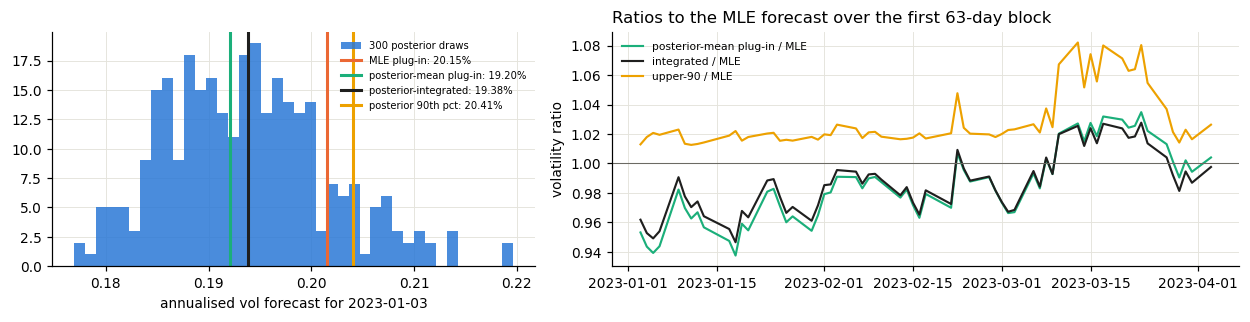

day 1: posterior CV of next-day variance 0.082;  "uncertainty premium" q90 / integrated - 1 = 0.109


In [23]:
h_mp = garch.variance_path(local, W, bayes.posterior_mean_u(flat))
h_int, h_q90 = s26['integrated'], s26['q90']
for col, val in [('variance_bayes_meanplug', h_mp), ('variance_bayes_integrated', h_int), ('variance_bayes_q90', h_q90)]:
    rel = np.max(np.abs(val / f_spy[col].to_numpy()[:63] - 1))
    check(f'fresh {col} == saved (same seed, this platform)', rel < 1e-10, f'max rel diff {rel:.1e}', RAW)
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3), gridspec_kw={'width_ratios': [1, 1.3]})
ax[0].hist(np.sqrt(252 * Hd[:, 0]), bins=40, color=C[0], alpha=.85, label='300 posterior draws')
for v, lab, c in [(h_mle[0], 'MLE plug-in', C[1]), (h_mp[0], 'posterior-mean plug-in', C[2]), (h_int[0], 'posterior-integrated', INK), (h_q90[0], 'posterior 90th pct', C[3])]:
    ax[0].axvline(np.sqrt(252 * v), color=c, lw=2, label=f'{lab}: {np.sqrt(252*v):.2%}')
ax[0].set_xlabel(f'annualised vol forecast for {f_spy.date[0].date()}'); ax[0].legend(fontsize=6.5)
for v, lab, c in [(h_mp, 'posterior-mean plug-in / MLE', C[2]), (h_int, 'integrated / MLE', INK), (h_q90, 'upper-90 / MLE', C[3])]:
    ax[1].plot(f_spy.date[:63], np.sqrt(v / h_mle), color=c, lw=1.4, label=lab)
ax[1].axhline(1, color=MUTED, lw=.7); ax[1].set_ylabel('volatility ratio'); ax[1].legend(fontsize=7)
ax[1].set_title('Ratios to the MLE forecast over the first 63-day block', loc='left'); plt.tight_layout(); plt.show()
cv0 = Hd[:, 0].std() / Hd[:, 0].mean()
print(f'day 1: posterior CV of next-day variance {cv0:.3f};  "uncertainty premium" q90 / integrated - 1 = {h_q90[0]/h_int[0]-1:.3f}')

### 6.2 The posterior predictive density

The quantity a forecaster ultimately needs is the distribution of tomorrow's return given today's data:
$$p(r_{t+1}\mid D_t)=\int p(r_{t+1}\mid\theta,D_t)\,p(\theta\mid D_t)\,d\theta=\int N\big(r_{t+1};0,h_{t+1}(\theta)\big)\,p(\theta\mid D_t)\,d\theta .$$
Replacing the posterior by its $M$ draws gives a **Gaussian scale mixture**:
$$\hat p(r_{t+1}\mid D_t)=\frac1M\sum_{m=1}^M N\big(r_{t+1};\,0,\,h^{(m)}_{t+1}\big).$$

Its properties follow from the law of total variance and moments:
- **Mean** 0 and **variance** $E[h_{t+1}(\theta)]=\bar h_{t+1}$. The integrated variance of §6.1 *is* the
  predictive variance.
- **Excess kurtosis** $3E[h^2]/E[h]^2-3=3\,\mathrm{CV}^2$, with CV the posterior coefficient of variation of
  $h_{t+1}$. Integration fattens the tails, but only by $3\,\mathrm{CV}^2$.
- **Numerical evaluation.** The log density is computed with log-sum-exp (`forecast.mixture_logpdf`). The CDF is
  $M^{-1}\sum_m\Phi(r/\sqrt{h^{(m)}})$ (`forecast.mixture_cdf`), and quantiles come from bisection on the CDF
  (`forecast.mixture_var`).

🟢 *raw data* — the predictive density for 2023-01-03, and for a turbulent day, 2020-03-17, using the saved draws
of the 2017–22 run (🔵).

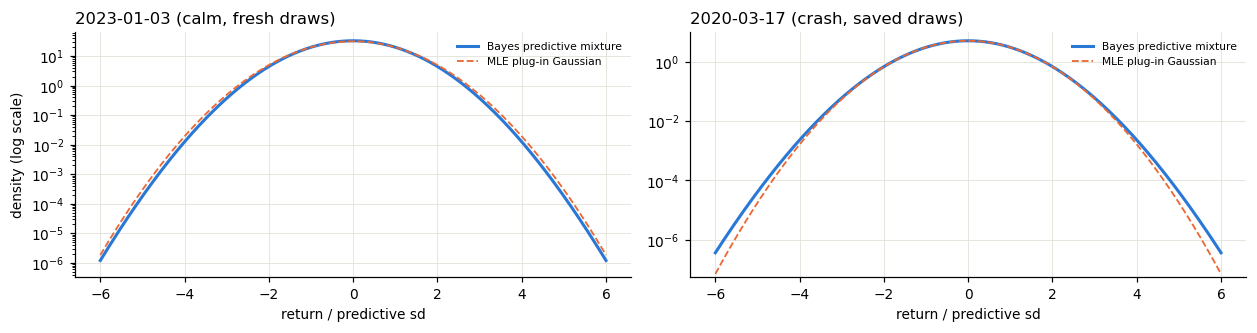

,posterior_CV,excess_kurt_3CV2,excess_kurt_mixture,P_loss_gt_4sd_mixture,P_loss_gt_4sd_gaussian
day,,,,,
"2023-01-03 (calm, fresh draws)",0.08211,0.02022,0.02022,0.00004,0.00003
"2020-03-17 (crash, saved draws)",0.12616,0.04775,0.04775,0.00005,0.00003


In [24]:
fpan, Dpan = A.load_panel('SPY', 500, ('ext',)); i_c = int(np.flatnonzero(fpan.date == '2020-03-17')[0])
cases = {'2023-01-03 (calm, fresh draws)': (Hd[:, 0], h_mle[0]), '2020-03-17 (crash, saved draws)': (Dpan[:, i_c], fpan.variance_mle.iloc[i_c])}
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.1))
rows = []
for k, (lab, (v, hm)) in enumerate(cases.items()):
    sd = np.sqrt(v.mean()); x = np.linspace(-6 * sd, 6 * sd, 600)
    mix = np.exp(fc.mixture_logpdf(x, v[:, None] * np.ones((1, len(x)))))
    gau = norm.pdf(x, scale=np.sqrt(hm))
    ax[k].semilogy(x / sd, mix, color=C[0], lw=2, label='Bayes predictive mixture'); ax[k].semilogy(x / sd, gau, color=C[1], lw=1.2, ls='--', label='MLE plug-in Gaussian')
    ax[k].set_ylim(mix.max() * 1e-8, mix.max() * 2); ax[k].set_xlabel('return / predictive sd'); ax[k].set_title(lab, loc='left'); ax[k].legend(fontsize=7)
    cv = v.std() / v.mean()
    rows.append(dict(day=lab, posterior_CV=cv, excess_kurt_3CV2=3 * cv ** 2, excess_kurt_mixture=fc.mixture_excess_kurtosis(v),
                     P_loss_gt_4sd_mixture=float(fc.mixture_cdf(np.array([-4 * sd]), v[:, None])[0]), P_loss_gt_4sd_gaussian=norm.cdf(-4)))
ax[0].set_ylabel('density (log scale)'); plt.tight_layout(); plt.show()
display(pd.DataFrame(rows).set_index('day').round(6))

### 6.3 Point, variance and density forecasts; credible and predictive intervals; VaR

| Object | Question it answers | Example (next cell) |
|---|---|---|
| **point forecast** | best single guess of $r_{t+1}$ | 0, by the zero-mean model |
| **variance forecast** | expected squared move $E[r_{t+1}^2\mid D_t]$ | $\bar h_{t+1}$ or $h_{t+1}(\hat\theta)$ |
| **density forecast** | the whole distribution of $r_{t+1}$ | the mixture or the plug-in Gaussian |
| **parameter credible interval** | where $\theta$, or $h_{t+1}(\theta)$, lies with 90% posterior probability | 5th–95th percentile of $h^{(m)}_{t+1}$ |
| **predictive interval** | where the *return* $r_{t+1}$ lies with 90% probability | 5th–95th percentile of the mixture |
| **Value-at-Risk** $\text{VaR}_\alpha$ | a loss exceeded with probability $\alpha$: $P(r_{t+1}<-\text{VaR}_\alpha)=\alpha$ | lower 1% quantile of the predictive distribution |

A credible interval for the *variance* is narrow, because it reflects only parameter uncertainty. A predictive
interval for the *return* is wide, because it is dominated by $z_{t+1}$. The upper-90 variance used in portfolios
(§12) is a quantile of the variance, **not** a return quantile. 🟢 *raw data*, checked against 🔵 *saved forecasts*.

In [25]:
v0 = Hd[:, [0]]; ann = lambda h: np.sqrt(252 * h)
q_mix = lambda prob: brentq(lambda x: fc.mixture_cdf(np.array([x]), v0)[0] - prob, -1, 1)
var01_mix = float(fc.mixture_var(v0, .01)[0])
check('mixture 1% VaR == saved var01_bayes_mixture', np.isclose(var01_mix, f_spy.var01_bayes_mixture.iloc[0], rtol=1e-8), level=RAW)
display(pd.DataFrame({'value': {
    '90% credible interval of next-day VOL (ann.)': f'[{ann(np.quantile(v0, .05)):.2%}, {ann(np.quantile(v0, .95)):.2%}]',
    '90% predictive interval of RETURN, mixture': f'[{q_mix(.05):+.3%}, {q_mix(.95):+.3%}]',
    '90% predictive interval of RETURN, MLE Gaussian': f'[{norm.ppf(.05)*np.sqrt(h_mle[0]):+.3%}, {norm.ppf(.95)*np.sqrt(h_mle[0]):+.3%}]',
    '1% VaR, MLE Gaussian': f'{tg.gaussian_var(h_mle[0], .01):.3%}',
    '1% VaR, Bayes predictive mixture': f'{var01_mix:.3%}',
    '1% "VaR" of N(0, upper-90 variance) (not calibrated by design)': f'{tg.gaussian_var(h_q90[0], .01):.3%}'}}))

PASS  mixture 1% VaR == saved var01_bayes_mixture


,value
90% credible interval of next-day VOL (ann.),"[18.18%, 20.76%]"
"90% predictive interval of RETURN, mixture","[-2.007%, +2.007%]"
"90% predictive interval of RETURN, MLE Gaussian","[-2.088%, +2.088%]"
"1% VaR, MLE Gaussian",2.953%
"1% VaR, Bayes predictive mixture",2.846%
"1% ""VaR"" of N(0, upper-90 variance) (not calibrated by design)",2.991%


### 6.4 Why the effect of integration is small

Parameter uncertainty enters the predictive distribution only through the spread of $h_{t+1}(\theta)$ across the
posterior. With a posterior CV of the variance of about 10%, the mixture's excess kurtosis is
$3\times0.1^2=0.03$. The variance of $z_{t+1}$ is 1, against $\mathrm{CV}^2\approx0.01$ of parameter-driven
variance. Return uncertainty therefore dominates parameter uncertainty by roughly two orders of magnitude.
Integration nudges the density's shoulders and tails; it cannot create the fat tails seen in the data (excess
kurtosis of standardised returns 0.4–2.9, §11). The full-sample consequences:
- *QLIKE*, which depends only on the variance, barely moves (H1).
- The *log score*, which rewards correct tail mass, improves slightly but reliably (H2).

The cell below scores the 63-day block, the template for the full evaluation of §9–§10. 🟢 *raw data*

In [26]:
y = local[W:]                                                  # the 63 realised returns of the block
ql = lambda h: ev.qlike(y ** 2, h)
ls_mle, ls_mix = fc.gaussian_logpdf(y, h_mle), fc.mixture_logpdf(y, Hd)
check('fresh MLE log score == saved', np.allclose(ls_mle, f_spy.logscore_mle[:63], atol=1e-10), level=RAW)
check('fresh predictive-mixture log score == saved', np.allclose(ls_mix, f_spy.logscore_bayes_mixture[:63], atol=1e-10), level=RAW)
display(pd.DataFrame({'mean QLIKE (lower better)': [ql(h_mle).mean(), ql(h_mp).mean(), ql(h_int).mean()],
                      'mean log score (higher better)': [ls_mle.mean(), fc.gaussian_logpdf(y, h_mp).mean(), ls_mix.mean()]},
                     index=['MLE plug-in', 'posterior-mean plug-in', 'integrated / predictive mixture']).round(5))

PASS  fresh MLE log score == saved
PASS  fresh predictive-mixture log score == saved


,mean QLIKE (lower better),mean log score (higher better)
MLE plug-in,-8.07534,3.11873
posterior-mean plug-in,-8.07035,3.11624
integrated / predictive mixture,-8.07073,3.11573


**Q E1.** Show that for a zero-mean Gaussian scale mixture with mixing variance $H$, $\operatorname{kurt}=3E[H^2]/E[H]^2$.

<a id="s7"></a>
## 7. Student-$t$ GARCH and other benchmark models

Four benchmarks put the Bayesian results in context. Each answers a different question. **Student-$t$ GARCH is fully implemented and estimated by MLE at every one of the 320 refits**; its comparison with the Bayesian mixture is one of the two central results (§10.3).

| Model | Formulation | Assumptions | Purpose |
|---|---|---|---|
| **Gaussian GARCH, MLE** | §3–§4 | Gaussian $z_t$; $\hat\theta$ treated as exact | the classical baseline |
| **Student-$t$ GARCH, MLE** | same recursion; $z_t\sim t_\nu$ scaled to unit variance | fat-tailed but symmetric innovations; $\nu>2$ | tests the *innovation* assumption |
| **EWMA (RiskMetrics)** | $h_t=\lambda h_{t-1}+(1-\lambda)r_{t-1}^2$, $\lambda=0.94$ | no estimation; integrated ($p=1$, $\omega=0$) | the industry heuristic |
| **Laplace approximation** | draws from $N(\hat u,\hat{\mathcal I}^{-1})$, then the same mixture as §6.2 | asymptotic normality of the MLE | *classical* parameter uncertainty |

**Student-$t$ GARCH.** With $z_t=\sqrt{(\nu-2)/\nu}\,\tau_t$, $\tau_t\sim t_\nu$, so that $\operatorname{Var}z_t=1$,
$$\log f(r_t\mid h_t)=\log\Gamma\!\big(\tfrac{\nu+1}2\big)-\log\Gamma\!\big(\tfrac\nu2\big)-\tfrac12\log\!\big(\pi(\nu-2)h_t\big)-\tfrac{\nu+1}2\log\!\Big(1+\frac{r_t^2}{(\nu-2)h_t}\Big).$$
It is estimated jointly with $u$ in the coordinate $\eta=\log(\nu-2)\in[\log0.05,\log200]$, by L-BFGS-B from three
starting values of $\nu$ (`student_t.t_mle_fit`). Its excess kurtosis $6/(\nu-4)$ for $\nu>4$ is not small: $\nu=6$
gives 3.

**EWMA** is GARCH with $\omega=0$ and $\alpha+\beta=1$ fixed. It never reverts to a long-run level and forgets the past
at a fixed rate. It is initialised at the variance of the first 100 returns of 2013, which cannot leak into any
evaluation period.

**Laplace.** $\hat{\mathcal I}=-\nabla^2\ell(\hat u)$ is the observed information. It is computed by finite differences
with step 0.01, with eigenvalues clipped to keep it positive definite (`bayes.laplace_cov`). Three hundred draws
$u^{(m)}\sim N(\hat u,\hat{\mathcal I}^{-1})$ are taken from a separate RNG (seed $s_0+7{,}777{,}777$) and filtered
like posterior draws; any draw giving a non-finite variance is dropped. It uses no prior. Comparing it with the
Bayesian mixture separates "acknowledging estimation uncertainty" from "Bayesian inference as such".

**Parameter uncertainty versus heavy-tailed innovations.**
- *Parameter uncertainty* makes the variance $h_{t+1}$ uncertain. The predictive density becomes a mixture of
  Gaussians with slightly different scales, at most $3\,\mathrm{CV}^2\approx0.03$ excess kurtosis.
- *Heavy-tailed innovations* make every conditional distribution fat-tailed, whatever $h_{t+1}$ is.

If the data's conditional tails are fat (§11), only the second mechanism can fit them. Student-$t$ can then improve
density forecasts substantially even when posterior integration barely helps, and even though both models produce
nearly the same *variance* forecast.

🟢 *raw data* — all three alternatives fitted on the representative window, checked against 🔵 *saved forecasts*.

In [27]:
tu, nu_hat, tres = tg.t_mle_fit(train, u1)
h_t = garch.variance_path(local, W, tu)
h_ew = ewma.ewma_variance(RR)[st:st + 63]
cov_lap = bayes.laplace_cov(train, u1)
us_lap = np.random.default_rng(2026 + 7_777_777).multivariate_normal(u1, cov_lap, size=300)   # the pipeline's RNG stream (refit 0)
v_lap = fc.variance_draws(local, W, us_lap); v_lap = v_lap[np.isfinite(v_lap).all(1) & (v_lap > 0).all(1)]
check('fresh Student-t nu and variance == saved', np.isclose(nu_hat, saved_fit.t_nu) and np.allclose(h_t, f_spy.variance_t[:63], rtol=1e-10), f'nu = {nu_hat:.2f}', RAW)
check('EWMA variance == saved', np.allclose(h_ew, f_spy.variance_ewma[:63], rtol=1e-12), level=RAW)
check('fresh Laplace sd(logit p) == saved', np.isclose(np.sqrt(cov_lap[1, 1]), saved_fit.lap_sd_logit_p, rtol=1e-10), level=RAW)
check('fresh Laplace integrated variance == saved (same RNG stream)', np.allclose(v_lap.mean(0), f_spy.variance_laplace_integrated[:63], rtol=1e-10), level=RAW)
lap_sd_p = pd.Series(expit(us_lap[:, 1])).std()
display(pd.DataFrame({'next-day ann. vol': {k: np.sqrt(252 * v) for k, v in
                      [('Gaussian MLE', h_mle[0]), ('Bayes integrated', h_int[0]), ('Bayes upper-90', h_q90[0]), ('Laplace integrated', v_lap[:, 0].mean()),
                       ('Student-t MLE', h_t[0]), ('EWMA', h_ew[0])]}}).T.round(4))
print(f'Student-t: nu = {nu_hat:.2f}, persistence {garch.unpack(tu)["persistence"]:.4f};  sd of p: posterior {p_.std():.4f}, Laplace {lap_sd_p:.4f}')

PASS  fresh Student-t nu and variance == saved  [nu = 12.24]
PASS  EWMA variance == saved
PASS  fresh Laplace sd(logit p) == saved
PASS  fresh Laplace integrated variance == saved (same RNG stream)


,Gaussian MLE,Bayes integrated,Bayes upper-90,Laplace integrated,Student-t MLE,EWMA
next-day ann. vol,0.2015,0.1938,0.2041,0.2021,0.1948,0.2077


Student-t: nu = 12.24, persistence 0.9901;  sd of p: posterior 0.0106, Laplace 0.0153


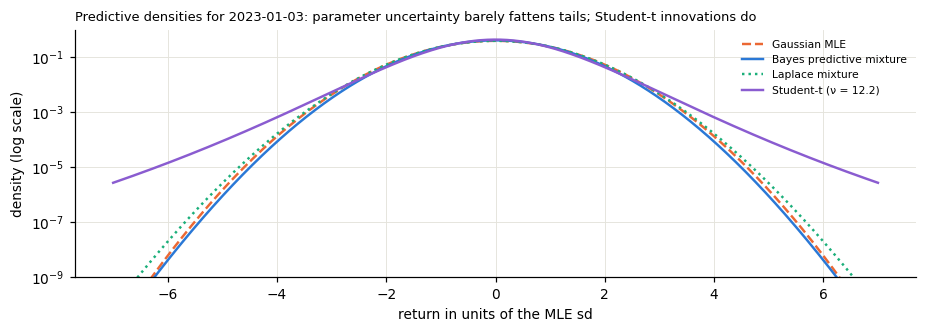

In [28]:
x = np.linspace(-7, 7, 700); sd0 = np.sqrt(h_mle[0]); xs = x * sd0
dens = {'Gaussian MLE': norm.pdf(xs, scale=sd0),
        'Bayes predictive mixture': np.exp(fc.mixture_logpdf(xs, Hd[:, [0]] * np.ones((1, len(xs))))),
        'Laplace mixture': np.exp(fc.mixture_logpdf(xs, v_lap[:, [0]] * np.ones((1, len(xs))))),
        f'Student-t (ν = {nu_hat:.1f})': np.exp(tg.t_logpdf(xs, np.full(len(xs), h_t[0]), nu_hat))}
fig, ax = plt.subplots(figsize=(8.5, 3.1))
for (k, d), c, ls in zip(dens.items(), [C[1], C[0], C[2], C[4]], ['--', '-', ':', '-']):
    ax.semilogy(x, d * sd0, color=c, lw=1.6, ls=ls, label=k)
ax.set_ylim(1e-9, 1); ax.set_xlabel('return in units of the MLE sd'); ax.set_ylabel('density (log scale)'); ax.legend(fontsize=7)
ax.set_title('Predictive densities for 2023-01-03: parameter uncertainty barely fattens tails; Student-t innovations do', loc='left', fontsize=8.5)
plt.tight_layout(); plt.show()

**Interpretation.**
- **Similar variances, different shapes.** All Gaussian-family forecasts are close to the MLE: posterior-integrated,
  Laplace and posterior-mean plug-in. The Student-$t$ forecast differs somewhat in level, because the $t$ likelihood
  down-weights outliers when it estimates $\alpha$ and $\beta$. EWMA differs most, because it has no mean reversion.
- **Density shape.** On the log scale, the Bayesian and Laplace mixtures are visually indistinguishable from the
  Gaussian out to about 4 sd. The Student-$t$ density puts far more mass beyond 5 sd, even with the fairly large
  $\hat\nu\approx12$ of this calm window. Across the 2017–22 refits the median $\hat\nu$ is about 5.6 (§5.8),
  with much heavier tails still. This is the mechanism behind the main finding of §9–§10: **the innovation distribution matters much more than
  parameter uncertainty.**
- **Laplace versus Bayes.** The Laplace spread of $p$ is of the same order as the posterior's (here somewhat
  wider), which is why the classical Laplace mixture recovers a large share (43–89%) of the Bayesian log-score gain (§10.2).

**Limitations.** Student-$t$ is symmetric, so it cannot represent the negative skewness of equity returns (§11). The
Laplace approximation is unreliable at the persistence bound (§4.5). EWMA's $\lambda$ is fixed by convention, not
estimated. No Bayesian Student-$t$ or asymmetric (GJR) model was fitted; this is outside the scope of this study.

<a id="s8"></a>
## 8. Data and rolling out-of-sample experimental design

### 8.1 Design

| Element | Setting |
|---|---|
| data | daily adjusted closes 2013-01-02 → 2026-11-04 (3,481 returns per ETF); DFF through 2026-11-03 |
| assets × windows | 4 ETFs × rolling estimation windows of **500** and **1,000** trading days (about 2 and 4 years) |
| refits | parameters re-estimated every **63** trading days (about one quarter) on the preceding 500 or 1,000 returns; each refit = MLE, MAP, 4-chain MCMC, Laplace, Student-$t$ |
| forecasts | **daily one-step-ahead** variance and density forecasts; between refits the parameters are frozen and the filter $h_{t+1}=\omega+\alpha r_t^2+\beta h_t$ is updated with each new return |
| **primary, independent period** | **2017-01-03 → 2022-12-30** (1,510 days, 24 refits per job). Never used by the earlier project milestones; all specifications were frozen before it was evaluated |
| previously inspected period | 2023-01-03 → 2026-11-04 (964 days, 16 refits per job). Studied repeatedly in earlier milestones; reported as a reproduction, **not** as independent evidence |
| jobs | 4 assets × 2 windows × 2 periods = **16 jobs, 320 refits** |

**Parameters versus states.**
- Refitted quarterly: the parameters $(\omega,\alpha,\beta)$ or $u$, the posterior draws, the Student-$t$ $\nu$ and
  the Laplace covariance.
- Updated daily: the conditional variances $h_t$ (one filter per posterior draw), and with them every forecast,
  score and portfolio weight.

**In-sample estimation versus out-of-sample forecasting.** A refit on days $[s-W,s)$ is *in-sample* for those
days. Every forecast for a day $d\ge s$ uses parameters that have never seen $r_d$ and a filter that has seen only
$r_{<d}$. Every score in §9–§13 is computed on such genuinely out-of-sample days.

### 8.2 Timeline

**Rolling design at a glance.**

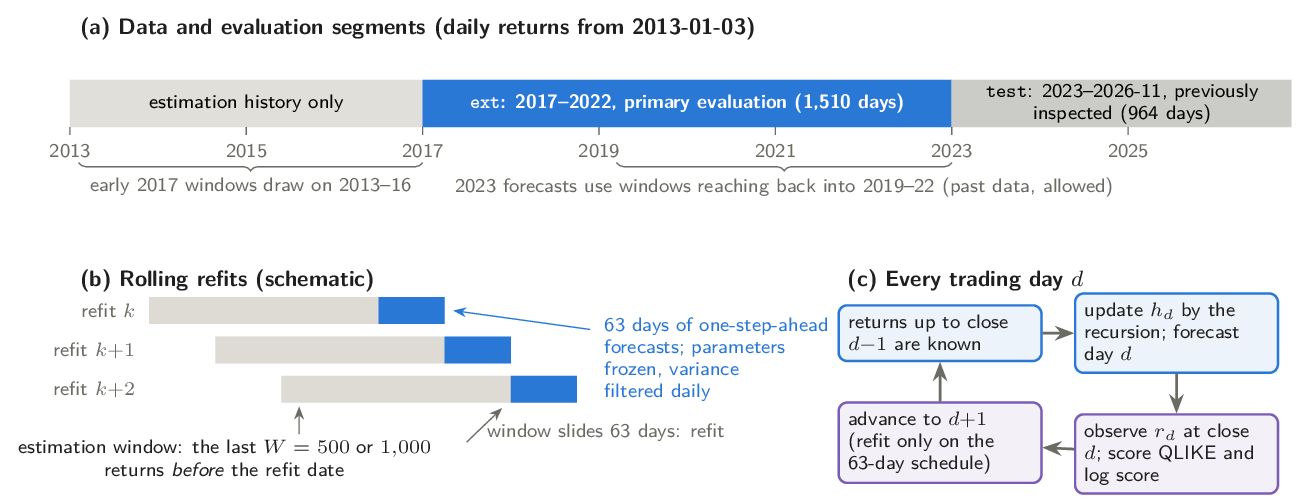

Five objects must be kept apart: (1) the **complete return history** from 2013; (2) the **moving estimation window**,
the last $W$ returns before a refit date; (3) the **evaluation dates**, each receiving a one-step-ahead forecast; (4) the
**refit schedule**, every 63 trading days; (5) the **daily variance updates** between refits.

**Evaluation segments.** `ext` (2017–22) is the primary evaluation: it is independent of earlier research-development
*inspection*, because the methods were frozen before it was examined; it does not mean the returns or windows are
statistically independent of other years. `test` (2023–26) had been inspected before and is a reproduction. Neither is
a "training set": both are chronological out-of-sample forecasts, and earlier returns legitimately enter later windows
(the first 2017 windows draw on 2013–16; 2023 windows reach back into 2019–22). No forecast uses information from its
own day or later (§8.3).

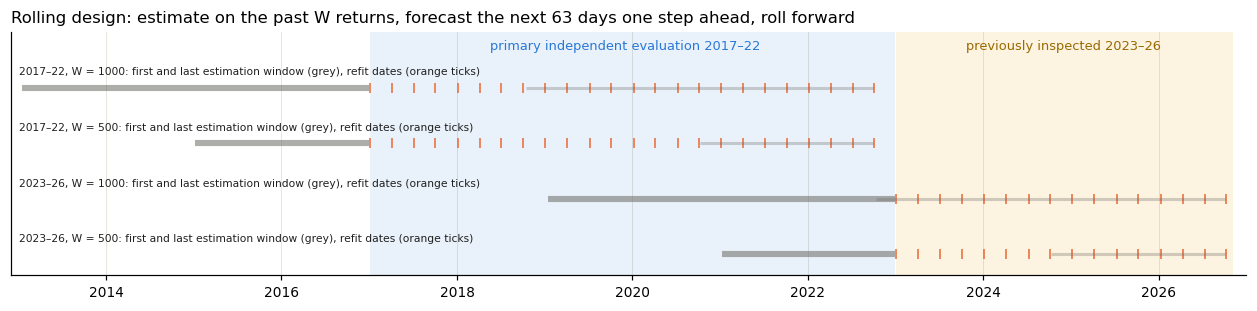

In [29]:
fig, ax = plt.subplots(figsize=(11.5, 2.9))
yr = lambda d: pd.Timestamp(d)
ax.axvspan(yr('2017-01-03'), yr('2022-12-30'), color=C[0], alpha=.10, lw=0); ax.axvspan(yr('2023-01-03'), yr('2026-11-04'), color=C[3], alpha=.12, lw=0)
ax.text(yr('2019-12-01'), 3.55, 'primary independent evaluation 2017–22', ha='center', color=C[0], fontsize=8.5)
ax.text(yr('2024-12-01'), 3.55, 'previously inspected 2023–26', ha='center', color='#9a6a00', fontsize=8.5)
idx = rets.index
for row, (seg, w) in enumerate([('ext', 1000), ('ext', 500), ('test', 1000), ('test', 500)]):
    fits_ = STORE.fits('SPY', w, seg); y0 = 3 - row * .8
    for j, (fs_, fe_, rd) in enumerate(zip(fits_.fit_start, fits_.fit_end, fits_.refit_date)):
        if j in (0, len(fits_) - 1):
            ax.plot([yr(fs_), yr(fe_)], [y0, y0], color=MUTED, lw=4 if j == 0 else 2, alpha=.55 if j == 0 else .3, solid_capstyle='butt')
        ax.plot([yr(rd)], [y0], '|', color=C[1], ms=7)
    ax.text(yr('2013-01-02'), y0 + .18, f'{SEGL[seg]}, W = {w}: first and last estimation window (grey), refit dates (orange ticks)', fontsize=7, color=INK)
ax.set_ylim(.3, 3.8); ax.set_yticks([]); ax.set_xlim(yr('2012-12-01'), yr('2026-12-31'))
ax.set_title('Rolling design: estimate on the past W returns, forecast the next 63 days one step ahead, roll forward', loc='left')
plt.tight_layout(); plt.show()

### 8.3 How look-ahead bias is avoided

1. **Truncation.** Each job truncates the return series at the segment end *before* any computation
   (`walkforward.run`), so nothing after the end can enter a fit or a filter.
2. **Fit windows** end on the trading day *before* the first forecast day of their block.
3. **Filter.** Row $d$ holds $h_d$ computed from $r_{<d}$; `variance_path` never reads $r_d$ when producing $h_d$.
4. **Execution.** A forecast for day $d$ is available after close $d-1$, the trade is placed at close $d$, and it
   earns the close $d\to d+1$ return (§12). The cash rate uses DFF strictly before the decision date.
5. **Controls.** The exposure-matched control uses only past rows (§13.4).
6. **No tuning.** No model, prior, window or strategy parameter was chosen using 2017–22 results.

🔵 *saved forecasts* — structural checks on all 16 saved jobs, plus two **perturbation canaries**. A canary changes a
single return and verifies that only *later* forecasts change.

In [30]:
struct = pd.DataFrame([N.artifact_structure(STORE, a, w, s, draws_dir=cfg.SAVED_FORECASTS) for s in SEGS for a in ASSETS for w in WINDOWS])
flags = struct.select_dtypes(bool)
display(struct.groupby('segment').agg(jobs=('asset', 'size'), rows_per_job=('rows', 'first'), refits=('refits', 'sum')).join(flags.groupby(struct.segment).all()))
check('all 16 jobs: calendar, 63-day refits, W-return fit windows ending before the forecasts, prices, finiteness, draw shapes',
      bool(flags.all().all()) and struct.refits.sum() == 320, f'{struct.refits.sum()} refits, {struct.rows.sum():,} forecast rows')
blk = RR[st - W: st + 63].copy(); base_h = garch.variance_path(blk, W, u1)
blk[W + 30] *= 25                                             # a huge return on forecast day 30 of the block
pert_h = garch.variance_path(blk, W, u1); changed = np.flatnonzero(pert_h != base_h)
check('canary: a shock to r_d changes forecasts only from row d+1 on', changed.min() == 31, f'first changed row {changed.min()}', RAW)
rows = []
for a in ASSETS:
    f_, _ = A.load_panel(a, 500)
    r2, h = f_.return_log.to_numpy() ** 2, f_.variance_mle.to_numpy()
    rows.append(dict(asset=a, corr_r2_with_h_same_row=np.corrcoef(r2, h)[0, 1], corr_r2_with_h_NEXT_row_LOOKAHEAD=np.corrcoef(r2[:-1], h[1:])[0, 1]))
display(pd.DataFrame(rows).set_index('asset').round(3))

,jobs,rows_per_job,refits,dates_equal_calendar,refit_every_63,refit_dates_match_log,fit_windows_have_W_returns,fit_ends_before_forecast,returns_match_prices,all_finite,variances_positive,draws_shape_ok
segment,,,,,,,,,,,,
ext,8,1510,192,True,True,True,True,True,True,True,True,True
test,8,964,128,True,True,True,True,True,True,True,True,True


PASS  all 16 jobs: calendar, 63-day refits, W-return fit windows ending before the forecasts, prices, finiteness, draw shapes  [320 refits, 19,792 forecast rows]
PASS  canary: a shock to r_d changes forecasts only from row d+1 on  [first changed row 31]


,corr_r2_with_h_same_row,corr_r2_with_h_NEXT_row_LOOKAHEAD
asset,,
SPY,0.530,0.747
QQQ,0.443,0.664
TLT,0.369,0.523
GLD,0.289,0.581


The last table shows why alignment matters. The forecast one row *later*, $h_{d+1}$, has already seen $r_d$, and it
is far more correlated with $r_d^2$ than the genuine forecast $h_d$. An off-by-one error would make every model look
much better than it is. `adequacy.load_panel` refuses to return data if any alignment condition fails.

<a id="s8-5"></a>
### 8.4 Computational strategy: what is loaded and what is recomputed

| Step | In this notebook | Level |
|---|---|---|
| representative MLE, MCMC, Student-$t$, Laplace, EWMA fits | rerun live (§4–§7) and matched to the saved fits | 🟢 |
| 320 rolling refits (MCMC dominates the cost) | **loaded** from the saved walk-forward artifacts (checksum-verified, structure-checked above) | ⚪ → 🔵 |
| daily losses, log scores (incl. the mixture score from the saved posterior draws), DM/HAC tests | recomputed from the daily forecasts | 🔵 |
| diagnostics, VaR back-tests, stress metrics | recomputed from the daily forecasts and draws | 🔵 |
| portfolios, exposure control, block bootstraps | recomputed from the daily forecasts, prices and DFF | 🔵 / 🟢 |

**How the saved forecasts were generated** (`bgarch_experiments.walkforward.run`, one call per job). For each refit
date $s$ (every 63 rows from the segment start), using `train` $=r_{[s-W,s)}$:
1. `garch.mle_fit` and `bayes.map_fit`.
2. `bayes.reliable_bayes_fit` (4 chains, seed $s_0+173i$) and `bayes.diagnostics`.
3. Subsample $M=300$ draws with `default_rng(s_0).choice`.
4. Filter the block $[s,s+63)$ with the MLE, MAP, posterior-mean and each posterior draw, and summarise with
   `forecast.predictive_summary`.
5. Compute `bayes.laplace_cov`, draw 300 Laplace samples, and filter them.
6. Fit `student_t.t_mle_fit` and filter.
7. Take EWMA from the full truncated series.
8. Compute log scores (`forecast.gaussian_logpdf`, `forecast.mixture_logpdf`, `student_t.t_logpdf`) and VaR at 1%
   and 5%.

Each job writes `<job>_daily.csv.gz` (one row per forecast day), `<job>_fits.csv` (one row per refit) and
`<job>_draws.npz` (300 × days variance draws, stored as float32).

**Full reproduction from market data** (about 70 s on 7 cores of an Apple M3; CPU only):
```bash
python -m bgarch_experiments.reproduce full --out /tmp/bgarch_full_run   # from the repository root; NEW or empty directory; never reads cached forecasts
```
This reruns all 16 jobs, rebuilds every table and figure from its *own* output, and compares them with the saved
results. ⚪ *artifact* — the record of the last two full runs:

In [31]:
runs = {name: json.loads((cfg.RESULTS / p).read_text()) for name, p in
        [('original course build', 'full_run/full_run.json'), ('after package refactor (2026-11-06)', 'package_refactor_check/full_run.json')]}
keys = ['jobs', 'refits', 'failed_convergence', 'fit_seconds', 'table_columns_identical', 'table_columns_compared',
        'max_rel_diff_classical_variance', 'max_rel_diff_bayesian_variance']
display(pd.DataFrame({k: {kk: v[kk] for kk in keys} for k, v in runs.items()}))
check('full rerun from market data reproduced all 282 table columns, both builds', all(v['table_columns_identical'] == 282 for v in runs.values()), level=ART)

,original course build,after package refactor (2026-11-06)
jobs,16.0,16.0
refits,320.0,320.0
failed_convergence,4.0,4.0
fit_seconds,47.2,43.5
table_columns_identical,282.0,282.0
table_columns_compared,282.0,282.0
max_rel_diff_classical_variance,0.0,0.0
max_rel_diff_bayesian_variance,0.0,0.0


PASS  full rerun from market data reproduced all 282 table columns, both builds


**Limitations.**
- **Platform dependence.** Bit-identical Bayesian columns are guaranteed only on the platform that produced them;
  elsewhere expect Monte Carlo-level differences (§5.7).
- **What "independent" means.** The 2017–22 period is independent of the *specification choices*. It is not
  independent of the general literature on GARCH, which was known in advance.

<a id="s9"></a>
## 9. H1 — Conditional variance forecasting

**Question.** Does the posterior-integrated forecast $\hat h^{\text{Bayes}}_t=E_{\theta\mid D_{t-1}}[h_t(\theta)]$ beat the
MLE forecast $\hat h^{\text{MLE}}_t=h_t(\hat\theta)$ as a point forecast of the conditional variance?

> **Experiment card — H1, conditional variance forecasting.**
>
> | Step | This section |
> |---|---|
> | **Motivation** | The variance forecast is what a risk manager or a volatility-targeting rule actually uses. |
> | **Mathematical formulation** | QLIKE $\log h_t+r_t^2/h_t$; loss differentials $d_t$; Diebold–Mariano statistic with Newey–West standard errors, pooled across ETFs by day (§9.1–9.3). |
> | **Numerical method** | Losses recomputed from the saved daily forecasts (§9.2); HAC test rebuilt step by step (§9.3). |
> | **Implementation** | `evaluation.qlike`, `evaluation.hac_mean`, `tables.forecast_tables`. |
> | **Results** | Report Table 2 and Figure 2 (§9.4). |
> | **Interpretation** | Small improvements, not statistically reliable: H1 not supported. |
> | **Limitations** | $r_t^2$ is a noisy proxy; HAC $p$-values are asymptotic; failing to reject is not evidence of equality. |

### 9.1 Variance forecasts: QLIKE

**Motivation.** The conditional variance $h_t$ is latent: it is never observed, even after the fact. The only
model-free proxy is the squared return $r_t^2$, which is *unbiased*, $E[r_t^2\mid\mathcal F_{t-1}]=h_t$, but very
noisy. Under Gaussian innovations $\operatorname{Var}(r_t^2\mid\mathcal F_{t-1})=2h_t^2$, so the proxy's standard
deviation is $\sqrt2$ times its mean. A good forecast will still look poor against $r_t^2$ on any single day.

**Loss function.** For a variance forecast $h$ and realised return $r_t$,
$$L(h,r_t)=\log h+\frac{r_t^2}{h}\qquad\text{(QLIKE; lower is better).}$$
- *Consistent ranking.* $E[L(h,r_t)\mid\mathcal F_{t-1}]=\log h+h_t/h$, which is minimised at $h=h_t$:
  $\partial/\partial h=1/h-h_t/h^2=0$. Patton (2011) shows that QLIKE belongs to the family of losses that rank
  forecasts the same way *in expectation* under the noisy proxy as under the true variance; in a finite sample the
  proxy noise remains, so average differences must be tested (§9.3). Not every loss has this property.
- *Relation to the likelihood.* QLIKE equals $-2\times$ the Gaussian log-density up to constants. It evaluates only
  the variance, not the shape of the distribution.
- *Robustness.* It depends on the ratio $r_t^2/h$, so it is scale-free and penalises under-prediction more than
  over-prediction.
- *Excess loss.* With $x=h_t/h$, the expected excess loss of a forecast $h$ over the truth is $x-1-\log x\ge0$, zero only
  at $x=1$. The argument uses only $E[r_t^2\mid\mathcal F_{t-1}]=h_t$; **it does not require Gaussian returns**, which
  matters because the returns are heavy-tailed (§11).

🔵 *saved forecasts* — first, how noisy the proxy is.

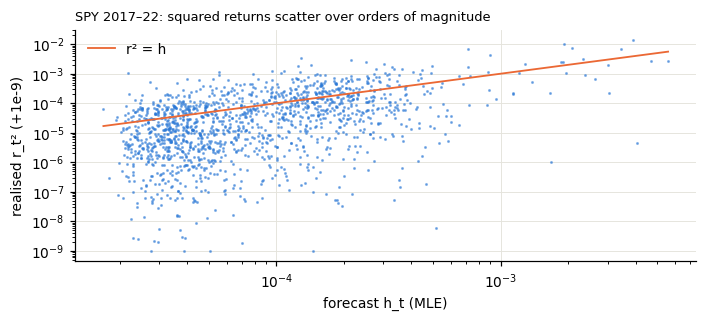

mean(r^2/h) = 1.085 (1 if unbiased);  corr(r^2, h) = 0.574;  share of days with r^2 < h/10: 30.7%


In [32]:
f_ext = STORE.daily('SPY', 500, 'ext'); y2 = f_ext.return_log.to_numpy() ** 2; hh = f_ext.variance_mle.to_numpy()
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.loglog(hh, y2 + 1e-9, '.', ms=2, color=C[0], alpha=.5); ax.plot([hh.min(), hh.max()], [hh.min(), hh.max()], color=C[1], lw=1.2, label='r² = h')
ax.set_xlabel('forecast h_t (MLE)'); ax.set_ylabel('realised r_t² (+1e-9)'); ax.legend(); ax.set_title('SPY 2017–22: squared returns scatter over orders of magnitude', loc='left', fontsize=8.5)
plt.tight_layout(); plt.show()
print(f'mean(r^2/h) = {np.mean(y2/hh):.3f} (1 if unbiased);  corr(r^2, h) = {np.corrcoef(y2, hh)[0,1]:.3f};  '
      f'share of days with r^2 < h/10: {np.mean(y2 < hh/10):.1%}')

**Numerical check of the QLIKE argument (🟢).** Simulated returns with known variance and heavy-tailed, unit-variance
$t_5$ innovations: the average QLIKE of a forecast $c\cdot h_t$ is smallest at $c=1$, although the returns are not Gaussian.

PASS  QLIKE minimised by the true variance with t5 returns; excess loss follows x - 1 - log x  [argmin 1.00 x truth]


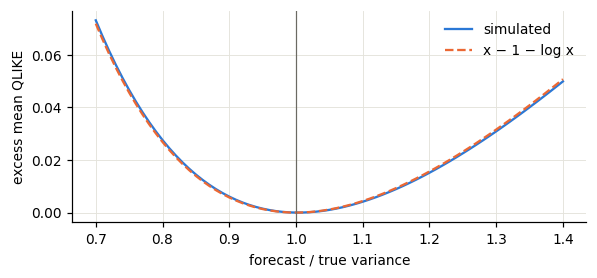

In [33]:
rng_q = np.random.default_rng(7); h_true = 1e-4 * np.exp(rng_q.normal(0, .5, 400_000))
r_sim = np.sqrt(h_true) * rng_q.standard_t(5, h_true.size) / np.sqrt(5 / 3)
scale = np.linspace(.7, 1.4, 71); q_avg = np.array([ev.qlike(r_sim ** 2, c_ * h_true).mean() for c_ in scale])
x_ = 1 / scale; theory = x_ - 1 - np.log(x_)                                        # expected excess loss with x = h/forecast
c_best = scale[int(np.argmin(q_avg))]
check('QLIKE minimised by the true variance with t5 returns; excess loss follows x - 1 - log x', abs(c_best - 1) <= .03 and np.max(np.abs((q_avg - q_avg.min()) - theory)) < .01,
      f'argmin {c_best:.2f} x truth', RAW)
fig, ax = plt.subplots(figsize=(5.5, 2.6)); ax.plot(scale, q_avg - q_avg.min(), color=C[0], label='simulated')
ax.plot(scale, theory, color=C[1], ls='--', label='x − 1 − log x'); ax.axvline(1, color=MUTED, lw=.8)
ax.set_xlabel('forecast / true variance'); ax.set_ylabel('excess mean QLIKE'); ax.legend(); plt.tight_layout(); plt.show()

### 9.2 QLIKE recomputed from the daily data

We recompute the mean QLIKE of every variance forecast for all 16 jobs directly from `return_log` and the
`variance_*` columns, and compare with the per-configuration table of the reusable pipeline code
(`tables.forecast_tables`). 🔵 *saved forecasts*

In [34]:
VAR_M = ['mle', 'bayes_meanplug', 'bayes_integrated', 'bayes_q90', 'laplace_integrated', 't', 'ewma']
qrows, ftab = [], {}
for seg in SEGS:
    ftab[seg] = tables.forecast_tables(seg)                     # (per-configuration table, pooled DM table)
    for a in ASSETS:
        for w in WINDOWS:
            f = STORE.daily(a, w, seg); y2 = f.return_log.to_numpy() ** 2
            qrows.append(dict(period=SEGL[seg], asset=a, window=w, **{m: ev.qlike(y2, f[f'variance_{m}'].to_numpy()).mean() for m in VAR_M}))
Q = pd.DataFrame(qrows)
ref = pd.concat([ftab[s][0] for s in SEGS])[[f'qlike_{m}' for m in VAR_M]].to_numpy()
check('hand-computed mean QLIKE == pipeline table (16 jobs x 7 forecasts)', np.allclose(Q[VAR_M].to_numpy(), ref, rtol=0, atol=1e-12))
display(Q.set_index(['period', 'asset', 'window']).round(4))

PASS  hand-computed mean QLIKE == pipeline table (16 jobs x 7 forecasts)


mle  bayes_meanplug  bayes_integrated  bayes_q90  laplace_integrated       t    ewma
period  asset window                                                                                         
2017–22 SPY   500    -8.3687         -8.3713           -8.3702    -8.3748             -8.3672 -8.3787 -8.3057
              1000   -8.3732         -8.3762           -8.3738    -8.3780             -8.3719 -8.3779 -8.3057
        QQQ   500    -7.7729         -7.7741           -7.7730    -7.7786             -7.7717 -7.7794 -7.7328
              1000   -7.7814         -7.7828           -7.7815    -7.7883             -7.7805 -7.7857 -7.7328
        TLT   500    -8.5279         -8.5484           -8.5503    -8.5626             -8.5405 -8.5337 -8.5718
              1000   -8.5359         -8.5512           -8.5510    -8.5666             -8.5363 -8.5456 -8.5718
        GLD   500    -8.5978         -8.5907           -8.5951    -8.5954             -8.5995 -8.5994 -8.6007
              1000   -8.5860         -8.5917           -8.5924    -8.5876             -8.5881 -8.6029 -8.6007
2023–26 SPY   500    -8.5179         -8.5250           -8.5234    -8.5230             -8.5184 -8.5208 -8.4917
              1000   -8.5212         -8.5239           -8.5245    -8.5173             -8.5217 -8.5227 -8.4917
        QQQ   500    -7.8316         -7.8379           -7.8372    -7.8359             -7.8316 -7.8296 -7.8164
              1000   -7.8346         -7.8396           -7.8376    -7.8329             -7.8344 -7.8332 -7.8164
        TLT   500    -8.5274         -8.5134           -8.5260    -8.4931             -8.5313 -8.5293 -8.5378
              1000   -8.5428         -8.5365           -8.5388    -8.5235             -8.5407 -8.5439 -8.5378
        GLD   500    -7.9246         -7.9321           -7.9280    -7.9394             -7.9243 -7.9213 -7.9288
              1000   -7.9208         -7.9202           -7.9219    -7.9396             -7.9192 -7.9202 -7.9288

### 9.3 Comparing forecasts: Diebold–Mariano tests with Newey–West standard errors

**The loss-difference framework.** For methods $A$ and $B$, let $d_t=L^A_t-L^B_t$. The null of equal predictive
accuracy is $H_0:E[d_t]=0$. The Diebold–Mariano statistic is
$$z=\frac{\bar d}{\widehat{\operatorname{se}}(\bar d)},\qquad \bar d=\frac1n\sum_t d_t,$$
and is approximately $N(0,1)$ under $H_0$. This requires stationarity and finite variance of $d_t$, but no assumption
that either model is correct.

**Dependence.** Loss differences are serially correlated, because both forecasts share the same volatility regime.
The naive $\operatorname{se}=s_d/\sqrt n$ is then wrong: too small with positive autocorrelation, too large with
negative autocorrelation. The Newey–West (HAC) long-run variance with
Bartlett weights is
$$\hat\sigma^2_{LR}=\hat\gamma_0+2\sum_{k=1}^{L}\Big(1-\frac{k}{L+1}\Big)\hat\gamma_k,\qquad \hat\gamma_k=\frac1n\sum_{t=k+1}^n(d_t-\bar d)(d_{t-k}-\bar d),\qquad \widehat{\operatorname{se}}(\bar d)=\sqrt{\hat\sigma^2_{LR}/n},$$
with $L=\lfloor4(n/100)^{2/9}\rfloor$: 7 lags for $n=1{,}510$ and 6 for $n=964$. The Bartlett weights guarantee a
non-negative variance.

**Pooling.** To gain power, the four ETFs' daily differences are averaged *before* testing:
$\bar d_t=\tfrac14\sum_{a}d_{a,t}$. The HAC standard error of the pooled series automatically accounts for
cross-asset correlation on the same day.

🔵 *saved forecasts* — the statistic computed step by step for one contrast, then by `evaluation.hac_mean`.

In [35]:
f = STORE.daily('SPY', 500, 'ext'); y2 = f.return_log.to_numpy() ** 2
d = ev.qlike(y2, f.variance_bayes_integrated.to_numpy()) - ev.qlike(y2, f.variance_mle.to_numpy())
n = len(d); Lg = int(np.floor(4 * (n / 100) ** (2 / 9))); z_ = d - d.mean()
gam = [z_ @ z_ / n] + [z_[k:] @ z_[:-k] / n for k in range(1, Lg + 1)]
lrv = gam[0] + 2 * sum((1 - k / (Lg + 1)) * gam[k] for k in range(1, Lg + 1))
se_nw, se_iid = np.sqrt(lrv / n), d.std() / np.sqrt(n)
m_, se_, zz, pp_ = ev.hac_mean(d)
check('step-by-step Newey-West DM statistic == evaluation.hac_mean', np.isclose(se_nw, se_) and Lg == ev.nw_lags(n))
print(f'SPY, W=500, 2017-22, QLIKE integrated - MLE: mean {d.mean():+.5f}, NW lags {Lg}, se_NW {se_nw:.5f} vs naive se {se_iid:.5f} '
      f'(ratio {se_nw/se_iid:.2f}); z = {zz:.2f}, p = {pp_:.3f}')

PASS  step-by-step Newey-West DM statistic == evaluation.hac_mean
SPY, W=500, 2017-22, QLIKE integrated - MLE: mean -0.00147, NW lags 7, se_NW 0.00104 vs naive se 0.00111 (ratio 0.94); z = -1.42, p = 0.157


In this example the HAC standard error is about 6% *smaller* than the naive one: the daily QLIKE differences are
slightly negatively autocorrelated at short lags. The correction can go either way, which is why it is always
applied.

### 9.4 Pooled variance-forecast contrasts (report Table 2 and Figure 2) — H1

🔵 *saved forecasts* — recomputed for both periods and both windows, and checked against the research tables.

In [36]:
pooled = {s: ftab[s][1] for s in SEGS}
for s in SEGS:
    refp = pd.read_csv(cfg.SAVED_PRIMARY / f'forecast_pooled_{s}.csv')
    check(f'pooled DM table {SEGL[s]} == research table', np.allclose(pooled[s][['pooled_mean', 'z', 'p']], refp[['pooled_mean', 'z', 'p']], rtol=0, atol=1e-12))
CONTRASTS = [('qlike_meanplug_minus_mle', 'QLIKE: posterior-mean plug-in − MLE (shrinkage)'), ('qlike_integrated_minus_meanplug', 'QLIKE: integrated − mean plug-in (integration)'),
             ('qlike_integrated_minus_mle', 'QLIKE: integrated − MLE'), ('qlike_ewma_minus_mle', 'QLIKE: EWMA − MLE'), ('qlike_t_minus_mle', 'QLIKE: Student-t − MLE'),
             ('ls_mixture_minus_meanplug', 'Log score: mixture − mean plug-in (integration)'), ('ls_mixture_minus_mle', 'Log score: mixture − MLE'),
             ('ls_laplace_minus_mle', 'Log score: Laplace mixture − MLE'), ('ls_t_minus_mle', 'Log score: Student-t − MLE'), ('ls_t_minus_mixture', 'Log score: Student-t − mixture')]
def table2(pooled):
    cols = {}
    for s in SEGS:
        P = pooled[s].set_index(['contrast', 'window'])
        for w in WINDOWS:
            cols[(SEGL[s], f'W={w}')] = [f"{P.loc[(k, w), 'pooled_mean']*1e3:+.2f} (p={P.loc[(k, w), 'p']:.3f})" for k, _ in CONTRASTS]
    return pd.DataFrame(cols, index=[lab for _, lab in CONTRASTS])
T2 = table2(pooled)
display(T2.iloc[:5].style.set_caption('Mean daily difference × 10⁻³ (Newey–West p). QLIKE: negative favours the first method.'))
bayes_q = pd.concat([pooled[s][pooled[s].contrast.isin(['qlike_meanplug_minus_mle', 'qlike_integrated_minus_meanplug', 'qlike_integrated_minus_mle'])] for s in SEGS])
check('H1: no Bayesian QLIKE contrast significant at 5% (8 period-window cells x 3 contrasts)', (bayes_q.p > .05).all(), f'min p = {bayes_q.p.min():.3f}')

PASS  pooled DM table 2017–22 == research table
PASS  pooled DM table 2023–26 == research table


PASS  H1: no Bayesian QLIKE contrast significant at 5% (8 period-window cells x 3 contrasts)  [min p = 0.076]


**H1: not supported by the evidence.**
- *Magnitudes.* Shrinkage (`meanplug − mle`) and integration (`integrated − meanplug`) change QLIKE by a few
  thousandths of a unit, against QLIKE levels of about −8 (§9.2) and a day-to-day spread of QLIKE differences that
  is far larger. The integration step on its own changes QLIKE by about $10^{-3}$ (between −1.6 and +0.8 × 10⁻³).
- *Significance.* None of the 12 Bayesian contrasts is significant at 5%; the smallest $p$ is 0.076.
- *Signs.* The point estimates are mostly negative, i.e. slightly favouring the Bayesian forecasts, but they are
  not statistically distinguishable from zero.
- *Other models.* EWMA has higher average QLIKE than GARCH, but not significantly ($p\ge0.23$). Student-$t$ variance
  forecasts have lower QLIKE in 2017–22, significantly only for $W=1000$ ($p=0.016$), and the same QLIKE in 2023–26.

**Failure to reject is not equality.** A non-significant DM test means that the data cannot distinguish the methods
at this sample size; it does not prove them equal. The informative quantity is the confidence interval:

In [37]:
ci = pd.concat([pooled[s].assign(period=SEGL[s]) for s in SEGS])
ci = ci[ci.contrast.isin(['qlike_integrated_minus_mle', 'qlike_meanplug_minus_mle'])].assign(se=lambda x: x.pooled_mean / x.z)
ci = ci.assign(lo=lambda x: (x.pooled_mean - 1.96 * x.se) * 1e3, hi=lambda x: (x.pooled_mean + 1.96 * x.se) * 1e3, est=lambda x: x.pooled_mean * 1e3)
display(ci[['period', 'window', 'contrast', 'est', 'lo', 'hi', 'p']].round(3).reset_index(drop=True))

,period,window,contrast,est,lo,hi,p
0,2017–22,500,qlike_integrated_minus_mle,-5.339,-11.792,1.114,0.105
1,2017–22,500,qlike_meanplug_minus_mle,-4.303,-12.114,3.508,0.280
2,2017–22,1000,qlike_integrated_minus_mle,-5.582,-11.739,0.575,0.076
3,2017–22,1000,qlike_meanplug_minus_mle,-6.387,-14.003,1.228,0.100
4,2023–26,500,qlike_integrated_minus_mle,-3.307,-8.432,1.818,0.206
5,2023–26,500,qlike_meanplug_minus_mle,-1.751,-9.348,5.847,0.652
6,2023–26,1000,qlike_integrated_minus_mle,-0.848,-3.222,1.526,0.484
7,2023–26,1000,qlike_meanplug_minus_mle,-0.207,-3.906,3.491,0.912


The 95% intervals for the QLIKE contrasts have half-widths of about 2–8 × 10⁻³. Improvements of up to about
0.01 cannot be excluded, but neither can small deteriorations. To translate into variance terms: if a forecast is
uniformly biased by a factor $1+\varepsilon$, its expected QLIKE rises by
$\log(1+\varepsilon)+(1+\varepsilon)^{-1}-1\approx\varepsilon^2/2$. A QLIKE difference of $5\times10^{-3}$ thus
corresponds to a uniform variance error of about 10% (about 5% in volatility, and in portfolio weight). The
upper end of the intervals is not negligible; the point estimates, about $10^{-3}$–$6\times10^{-3}$, are small.

**Conclusion for H1.** Posterior integration produces small numerical QLIKE improvements (about $-5\times10^{-3}$ in
2017–22, $p=0.10$ and $0.08$) that are not statistically reliable at 5% in the primary evaluation, and most of the small
effect comes from prior shrinkage rather than integration. **H1 is not supported.** The intervals are compatible with
no effect and with a small gain, so this is not proof that the forecasts are equivalent.

*Transition.* A variance is one number. Two models can have similar variance forecasts while assigning very different
probabilities to extreme returns, so QLIKE alone cannot judge a predictive distribution. That is H2.

<a id="s10"></a>
## 10. H2 — Predictive return distributions

**Question.** Does accounting for parameter uncertainty improve the prediction of the *whole* distribution of daily
returns? Three predictive densities are compared:

| Model | Predictive density for day $t$ | What it represents |
|---|---|---|
| **A. Gaussian GARCH, MLE** | $N\big(r;0,h_t(\hat\theta)\big)$ | one Gaussian, parameters treated as exact |
| **B. Bayesian Gaussian GARCH** | $\int N\big(r;0,h_t(\theta)\big)\,p(\theta\mid D_{t-1})\,d\theta\approx\frac1M\sum_m N\big(r;0,h_t^{(m)}\big)$ | parameter uncertainty, by Monte Carlo over $M=300$ posterior draws |
| **C. Student-$t$ GARCH, MLE** | standardised $t_{\hat\nu}$ scaled to variance $h^t_t$ | heavy-tailed innovations inside the model |

> **Experiment card — H2, predictive distributions.**
>
> | Step | This section |
> |---|---|
> | **Motivation** | QLIKE sees only the variance; the tails of the predictive distribution matter for risk. |
> | **Mathematical formulation** | Log score $\log p(r_t\mid D_{t-1})$, strictly proper; mixture density averaged before the log; pooled DM tests (§10.1). |
> | **Numerical method** | Mixture scores recomputed from the 300 saved posterior variance draws per day (§10.1); Jensen check. |
> | **Implementation** | `forecast.mixture_logpdf`, `student_t.t_logpdf`, `evaluation.hac_mean`. |
> | **Results** | Report Tables 3–4 and Figure 3, the Student-$t$/Bayes and Laplace/Bayes ratios (§10.2–10.3). |
> | **Interpretation** | Bayesian gain real but small; Student-$t$ gain 5–6× larger in 2017–22: **Finding 1** (§10.3). |
> | **Limitations** | 2023–26 is not independent; significance is not practical importance; Bayesian Student-$t$ was not tested. |

### 10.1 Density forecasts: the logarithmic score

**Definition.** For a predictive density $p(\cdot\mid D_{t-1})$ and the realised return,
$$S_t=\log p(r_t\mid D_{t-1})\qquad\text{(higher is better).}$$
- *Strictly proper.* If the truth is $g$, then $E_g[\log p(r)]$ is uniquely maximised at $p=g$, because the
  difference is the Kullback–Leibler divergence $\mathrm{KL}(g\Vert p)\ge0$ (Gneiting & Raftery, 2007). A forecaster
  cannot gain by misreporting.
- *What it rewards.* Probability mass where the returns actually fall, including the tails. A density that is too
  thin-tailed is punished heavily on extreme days, through the $-r^2/2h$ term.
- *Units.* Nats per day. A mean difference of 0.005 means the better density assigns, on average,
  $e^{0.005}-1\approx0.5\%$ more density to the realised returns.

**The Bayesian score is the mixture score.** For the Bayesian forecast, $S_t$ must be computed from the *mixture*
$\frac1M\sum_mN(r_t;0,h^{(m)}_t)$. Using a Gaussian with the integrated variance would discard exactly the tail
effect being tested. The saved artifacts contain the 300 variance draws for every forecast day. Below, the mixture
log score is **recomputed from those draws** for all 16 jobs (24,000 × 300 densities per model). It is compared with
the saved `logscore_bayes_mixture` column, and the pooled DM contrasts are rebuilt from the recomputed scores.
🔵 *saved forecasts*

**Relation to QLIKE.** For a single Gaussian predictive density, $-S_t=\tfrac12(\log2\pi+\text{QLIKE}_t)$, so the log
score ranks Gaussian plug-in forecasts exactly as QLIKE does. For a mixture (B) or a Student-$t$ density (C) the two
metrics differ: the log score also rewards the **shape** of the distribution, in particular its tail mass.

**Average densities, then take the log.** $\log\frac1M\sum_m p_m(r)\ge\frac1M\sum_m\log p_m(r)$ (Jensen): the mixture
is never penalised as heavily as its average component when a return lands in the tails. The average of the component log densities is *not*
the score of any predictive density: its exponential, the geometric mean of the components, integrates to less than
one unless they coincide. The implementation therefore averages densities via log-sum-exp (checked below).

In [38]:
ls_rows, ls_new = [], {}
for seg in SEGS:
    for a in ASSETS:
        for w in WINDOWS:
            f = STORE.daily(a, w, seg); z = np.load(cfg.SAVED_FORECASTS / f'{STORE.name(a, w, seg)}_draws.npz')
            y = f.return_log.to_numpy(); v = z['v'].astype(float)          # (300, n): stored as float32
            mix = fc.mixture_logpdf(y, v); gau_int = fc.gaussian_logpdf(y, f.variance_bayes_integrated.to_numpy())
            ls_new[(seg, a, w)] = pd.DataFrame({'date': f.date, 'mle': fc.gaussian_logpdf(y, f.variance_mle.to_numpy()),
                                                'meanplug': fc.gaussian_logpdf(y, f.variance_bayes_meanplug.to_numpy()), 'mixture': mix})
            ls_rows.append(dict(period=SEGL[seg], asset=a, window=w, max_abs_diff_vs_saved=np.max(np.abs(mix - f.logscore_bayes_mixture.to_numpy())),
                                mean_mixture=mix.mean(), mean_gaussian_with_integrated_variance=gau_int.mean(), mean_mle=f.logscore_mle.mean()))
LS = pd.DataFrame(ls_rows)
check('mixture log score recomputed from saved posterior draws == saved column (float32 draws: |diff| < 1e-5)', LS.max_abs_diff_vs_saved.max() < 1e-5,
      f'max |diff| {LS.max_abs_diff_vs_saved.max():.1e}')
rebuilt = []
for seg in SEGS:
    for w in WINDOWS:
        for k, (x_, y_) in {'ls_mixture_minus_mle': ('mixture', 'mle'), 'ls_mixture_minus_meanplug': ('mixture', 'meanplug')}.items():
            dd = pd.concat([ls_new[(seg, a, w)].set_index('date').eval(f'{x_} - {y_}') for a in ASSETS], axis=1).mean(axis=1).to_numpy()
            m_, _, z_, p_v = ev.hac_mean(dd); P = pooled[seg].set_index(['contrast', 'window']).loc[(k, w)]
            rebuilt.append(dict(period=SEGL[seg], window=w, contrast=k, mean_from_draws=m_, p_from_draws=p_v, mean_table=P.pooled_mean, p_table=P.p))
RB = pd.DataFrame(rebuilt); display(RB.round(6))
check('pooled log-score contrasts rebuilt from the draws match the table (|diff in mean| < 1e-7)', np.allclose(RB.mean_from_draws, RB.mean_table, atol=1e-7, rtol=0))
print('Using a Gaussian with the integrated variance instead of the mixture would understate the Bayesian score by '
      f'{(LS.mean_mixture - LS.mean_gaussian_with_integrated_variance).mean():.5f} nats/day on average.')

PASS  mixture log score recomputed from saved posterior draws == saved column (float32 draws: |diff| < 1e-5)  [max |diff| 1.1e-07]


,period,window,contrast,mean_from_draws,p_from_draws,mean_table,p_table
0,2017–22,500,ls_mixture_minus_mle,0.00518,0.01166,0.00518,0.01166
1,2017–22,500,ls_mixture_minus_meanplug,0.00303,0.00000,0.00303,0.00000
2,2017–22,1000,ls_mixture_minus_mle,0.00468,0.02417,0.00468,0.02417
3,2017–22,1000,ls_mixture_minus_meanplug,0.00149,0.00371,0.00149,0.00371
4,2023–26,500,ls_mixture_minus_mle,0.00519,0.01545,0.00519,0.01545
5,2023–26,500,ls_mixture_minus_meanplug,0.00431,0.00623,0.00431,0.00623
6,2023–26,1000,ls_mixture_minus_mle,0.00226,0.02370,0.00226,0.02370
7,2023–26,1000,ls_mixture_minus_meanplug,0.00215,0.00063,0.00215,0.00063


PASS  pooled log-score contrasts rebuilt from the draws match the table (|diff in mean| < 1e-7)
Using a Gaussian with the integrated variance instead of the mixture would understate the Bayesian score by 0.00244 nats/day on average.


In [39]:
f_j = STORE.daily('SPY', 500, 'ext'); v_j = np.load(cfg.SAVED_FORECASTS / f"{STORE.name('SPY', 500, 'ext')}_draws.npz")['v'].astype(float)
y_j = f_j.return_log.to_numpy(); comp = -.5 * (np.log(2 * np.pi * v_j) + y_j[None, :] ** 2 / v_j)
log_mean, mean_log = np.log(np.exp(comp).mean(0)), comp.mean(0)
check('mixture_logpdf == log of the AVERAGE density (log-sum-exp)', np.allclose(fc.mixture_logpdf(y_j, v_j), log_mean, atol=1e-10), level=FC)
check('Jensen: log-mean density >= mean log density on every day', (log_mean >= mean_log - 1e-12).all(), f'mean gap {np.mean(log_mean - mean_log):.2e} nats/day', FC)
check('single Gaussian: -log score == (log 2pi + QLIKE)/2', np.allclose(-fc.gaussian_logpdf(y_j, f_j.variance_mle.to_numpy()),
      .5 * (np.log(2 * np.pi) + ev.qlike(y_j ** 2, f_j.variance_mle.to_numpy()))), level=FC)

PASS  mixture_logpdf == log of the AVERAGE density (log-sum-exp)
PASS  Jensen: log-mean density >= mean log density on every day  [mean gap 5.87e-03 nats/day]
PASS  single Gaussian: -log score == (log 2pi + QLIKE)/2


### 10.2 Pooled density-forecast contrasts (report Tables 3–4 and Figure 3) — H2

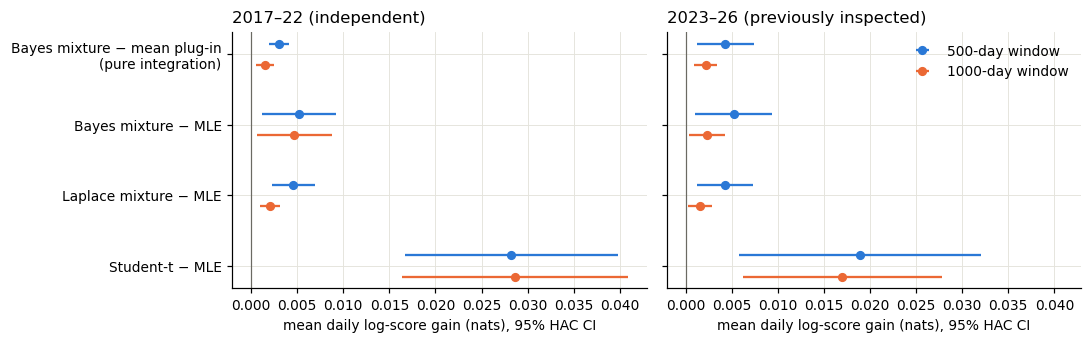

PASS  H2: mixture beats MLE and mean plug-in in every pooled cell, p <= 0.024, gain 0.0015-0.005 nats/day (report §5)  [range 0.0015-0.0052, max p 0.024]
PASS  Student-t gains 0.017-0.029 nats/day and beats the mixture in all 4 cells (report §5)  [range 0.0170-0.0286]


bayes_gain  t_gain  laplace_gain  t_over_bayes  laplace_share
period  window                                                               
2017–22 500         0.0052  0.0282        0.0046        5.4434         0.8861
        1000        0.0047  0.0286        0.0020        6.1147         0.4324
2023–26 500         0.0052  0.0189        0.0043        3.6393         0.8218
        1000        0.0023  0.0170        0.0016        7.5220         0.6864

PASS  Student-t gain is about 5-6x the Bayesian gain in 2017-22  [5.44, 6.11]
PASS  Student-t / Bayesian gain ratio spans 3.6-7.5 across all four cells  [3.64-7.52]
PASS  Laplace captures 43-89% of the Bayesian log-score gain; below half in exactly one cell  [0.432-0.886]


In [40]:
display(T2.iloc[5:].style.set_caption('Mean daily log-score difference × 10⁻³ (Newey–West p). Positive favours the first method.'))
lab1 = {'ls_mixture_minus_meanplug': 'Bayes mixture − mean plug-in\n(pure integration)', 'ls_mixture_minus_mle': 'Bayes mixture − MLE',
        'ls_laplace_minus_mle': 'Laplace mixture − MLE', 'ls_t_minus_mle': 'Student-t − MLE'}
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2), sharex=True)
for a_, s in zip(ax, SEGS):
    P = pooled[s]
    for j, w in enumerate(WINDOWS):
        sub = P[(P.window == w)].set_index('contrast').loc[list(lab1)]; se = sub.pooled_mean / sub.z
        a_.errorbar(sub.pooled_mean, np.arange(4) + (j - .5) * .3, xerr=1.96 * se, fmt='o', ms=5, color=C[j], capsize=0, label=f'{w}-day window')
    a_.axvline(0, color=MUTED, lw=.8); a_.set_yticks(range(4)); a_.set_yticklabels(list(lab1.values()) if s == 'ext' else []); a_.invert_yaxis()
    a_.set_title(SEGL[s] + (' (independent)' if s == 'ext' else ' (previously inspected)'), loc='left'); a_.set_xlabel('mean daily log-score gain (nats), 95% HAC CI')
ax[1].legend(); plt.tight_layout(); plt.show()
mix_c = pd.concat([pooled[s][pooled[s].contrast.isin(['ls_mixture_minus_mle', 'ls_mixture_minus_meanplug'])] for s in SEGS])
t_c = pd.concat([pooled[s][pooled[s].contrast == 'ls_t_minus_mle'] for s in SEGS]); tm_c = pd.concat([pooled[s][pooled[s].contrast == 'ls_t_minus_mixture'] for s in SEGS])
check('H2: mixture beats MLE and mean plug-in in every pooled cell, p <= 0.024, gain 0.0015-0.005 nats/day (report §5)',
      (mix_c.pooled_mean > 0).all() and mix_c.p.max() <= .0245 and mix_c.pooled_mean.min() >= .0014 and mix_c.pooled_mean.max() <= .0055,
      f'range {mix_c.pooled_mean.min():.4f}-{mix_c.pooled_mean.max():.4f}, max p {mix_c.p.max():.3f}')
check('Student-t gains 0.017-0.029 nats/day and beats the mixture in all 4 cells (report §5)',
      t_c.pooled_mean.between(.0165, .0295).all() and (tm_c.p < .05).all() and (tm_c.pooled_mean > 0).all(),
      f'range {t_c.pooled_mean.min():.4f}-{t_c.pooled_mean.max():.4f}')

# the ratios quoted in the summaries, computed from the pooled contrasts themselves
PC = {s: pooled[s].set_index(['contrast', 'window']).pooled_mean for s in SEGS}
RAT = pd.DataFrame([dict(period=SEGL[s], window=w, bayes_gain=PC[s][('ls_mixture_minus_mle', w)], t_gain=PC[s][('ls_t_minus_mle', w)],
                         laplace_gain=PC[s][('ls_laplace_minus_mle', w)]) for s in SEGS for w in WINDOWS])
RAT = RAT.assign(t_over_bayes=RAT.t_gain / RAT.bayes_gain, laplace_share=RAT.laplace_gain / RAT.bayes_gain)
display(RAT.round(4).set_index(['period', 'window']))
r_ext = RAT[RAT.period == SEGL['ext']].t_over_bayes
check('Student-t gain is about 5-6x the Bayesian gain in 2017-22', r_ext.between(5.0, 6.5).all(), f'{r_ext.min():.2f}, {r_ext.max():.2f}')
check('Student-t / Bayesian gain ratio spans 3.6-7.5 across all four cells', (round(RAT.t_over_bayes.min(), 1), round(RAT.t_over_bayes.max(), 1)) == (3.6, 7.5),
      f'{RAT.t_over_bayes.min():.2f}-{RAT.t_over_bayes.max():.2f}')
check('Laplace captures 43-89% of the Bayesian log-score gain; below half in exactly one cell',
      (round(100 * RAT.laplace_share.min()), round(100 * RAT.laplace_share.max())) == (43, 89) and int((RAT.laplace_share < .5).sum()) == 1,
      f'{RAT.laplace_share.min():.3f}-{RAT.laplace_share.max():.3f}')

**H2: supported, but the effect is small.**
- The Bayesian predictive mixture beats both the MLE plug-in and the posterior-mean plug-in density in every pooled
  test (both periods, both windows), by 0.0015–0.005 nats per day.
- The *pure integration* contrast (mixture − mean plug-in) is positive and significant everywhere. The gain comes
  from integration, not from shrinkage.
- **Classical uncertainty does much of the work.** The Laplace mixture obtains 43–89% of the same gain: more than
  half in three of the four cells, but only 43% in 2017–22 with $W=1000$. Much of the benefit comes from
  acknowledging estimation uncertainty at all, not specifically from Bayesian inference.
- **Fat tails dominate.** Student-$t$ innovations improve the log score by 0.017–0.029 nats/day, about five to six times
  the Bayesian gain in 2017–22 (ratios 5.4 and 6.1; 3.6 and 7.5 in 2023–26), and beat the Bayesian mixture significantly in all four cells.

**Statistical significance versus practical importance.** With 1,510 days × 4 assets, even a 0.003 nats/day
difference is estimated precisely, because the integration contrast has very low variance (both forecasts share
almost everything). Practically:
- 0.003 nats/day is a 0.3% higher average density at the realised return.
- Over a year it accumulates to a likelihood ratio of $e^{0.003\times252}\approx2$. That is noticeable for a
  statistician, but it changes neither the variance (H1) nor any portfolio weight (H3).
- The Student-$t$ gain of about 0.02 nats/day accumulates to a likelihood ratio of about 150 a year.

### 10.3 Student-$t$ GARCH versus Bayesian integration — the central H2 finding

Both B and C widen the predictive distribution relative to the Gaussian MLE, by different mechanisms:

| | Mechanism | Extra tail mass depends on |
|---|---|---|
| **Bayesian Gaussian GARCH** | mixing Gaussians whose variances differ across posterior draws | the posterior dispersion of $h_t^{(m)}$ |
| **Student-$t$ GARCH (MLE)** | heavy-tailed innovations inside the conditional model | the fitted degrees of freedom $\hat\nu$ |

The cell below puts the two gains side by side for every period and window, tests Student-$t$ directly against the
Bayesian mixture, summarises the fitted $\hat\nu$ over all 320 refits, and verifies the scale-mixture identity
$\kappa_{\text{excess}}=3\,\mathrm{CV}^2$ on the saved draws. 🔵 *saved forecasts*

In [41]:
display(RAT.set_index(['period', 'window']).round(4).style.set_caption('Pooled log-score gains over Gaussian MLE (nats/day) and their ratios'))
tm_tab = pd.concat([pooled[s][pooled[s].contrast == 'ls_t_minus_mixture'].assign(period=SEGL[s]) for s in SEGS])[['period', 'window', 'pooled_mean', 'p']]
display(tm_tab.set_index(['period', 'window']).style.format({'pooled_mean': '{:.4f}', 'p': '{:.4f}'}).set_caption('Student-t minus Bayesian mixture, direct test'))
check('Student-t beats the Bayesian mixture directly in every cell (p <= 0.011)', (tm_tab.pooled_mean > 0).all() and tm_tab.p.max() <= .011, f'max p {tm_tab.p.max():.4f}', FC)
nu_all = pd.concat([STORE.daily(a, w, s).drop_duplicates('refit_date').assign(asset=a)[['asset', 't_nu']] for s in SEGS for a in ASSETS for w in WINDOWS])
display(nu_all.groupby('asset').t_nu.describe()[['count', 'min', '50%', 'max']].round(1).style.set_caption('Fitted Student-t degrees of freedom over the 320 refits'))
check('Student-t median nu about 7 over the 320 refits; 7 refits at the upper bound (essentially Gaussian)',
      len(nu_all) == 320 and round(nu_all.t_nu.median()) == 7 and int((nu_all.t_nu > 200).sum()) == 7, f'median {nu_all.t_nu.median():.1f}', FC)
k_emp = np.array([fc.mixture_excess_kurtosis(v_j[:, i]) for i in range(v_j.shape[1])])
cv_d = v_j.std(0) / v_j.mean(0)
check('scale-mixture identity: excess kurtosis == 3 CV^2 for every day (SPY 500d 2017-22)', np.allclose(k_emp, 3 * cv_d ** 2), f'median {np.median(k_emp):.3f}', FC)

PASS  Student-t beats the Bayesian mixture directly in every cell (p <= 0.011)  [max p 0.0108]


,count,min,50%,max
asset,,,,
GLD,80.000000,4.400000,5.900000,13.800000
QQQ,80.000000,3.200000,6.800000,202.000000
SPY,80.000000,3.100000,6.100000,123.200000
TLT,80.000000,9.000000,17.700000,202.000000


PASS  Student-t median nu about 7 over the 320 refits; 7 refits at the upper bound (essentially Gaussian)  [median 7.2]
PASS  scale-mixture identity: excess kurtosis == 3 CV^2 for every day (SPY 500d 2017-22)  [median 0.023]


**Why does Student-$t$ GARCH perform so much better?**
1. Gaussian GARCH already models time-varying variance, which makes *unconditional* returns heavy-tailed even with
   Gaussian innovations; the question is whether the *conditional* tails are right.
2. Bayesian integration adds one more Gaussian scale mixture. If $r=\sqrt H z$ with $z\sim N(0,1)$ independent of $H$,
   then $E r^2=E H$ and $E r^4=3E H^2$, so
   $$\kappa_{\text{excess}}=3\,\frac{\operatorname{Var}(H)}{E[H]^2}=3\,\mathrm{CV}^2$$
   (zero mean and $H$ independent of $z$ — exactly the structure of the predictive mixture; verified above).
3. How much tail this adds depends on the posterior dispersion of the forecast variance.
4. In these experiments that dispersion is limited: posterior CV of 7–12%; averaged over days, $3\,\mathrm{CV}^2$ is only 0.015–0.046 (§11.7, report Figure 5).
5. Returns standardised by the forecasts show 0.4–2.9, so parameter uncertainty explains only a few per cent of the tail
   heaviness.
6. Student-$t$ innovations put heavy tails directly into the conditional model; with $\hat\nu\approx7$ the conditional
   excess kurtosis $6/(\nu-4)$ is about 2, the size observed.
7. The residual diagnostics of §11 confirm that the Gaussian innovation assumption is inadequate: too many $|z|>3$ days
   and too many lower-tail 1% exceedances, which the Bayesian mixture barely changes and Student-$t$ largely fixes
   (but not the negative skew of equity returns).

> **Finding 1.** In these experiments, improving the innovation distribution produced a substantially larger
> predictive-density improvement than Bayesian integration of parameter uncertainty under the Gaussian GARCH
> specification: innovation-distribution misspecification is more consequential than parameter uncertainty within the
> tested model.

This does **not** show that parameter uncertainty is unimportant in general, that all heavy tails come from the
innovation distribution, or that a Bayesian Student-$t$ GARCH would fail to improve on its MLE version (it was not
tested). **H2 is supported, with a small Bayesian effect.**

### 10.4 Robustness: refits that fail diagnostics, and boundary refits

🔵 *saved forecasts* — the per-configuration tests recomputed after **excluding** all days forecast by the 4 refits
that missed the strict convergence rule, compared with the research's converged-only table. ⚪ *artifact* — the
research decomposition of boundary versus non-boundary refits.

In [42]:
for s in SEGS:
    conv = tables.forecast_tables(s, exclude_failed=True)[0]; refc = pd.read_csv(cfg.SAVED_PRIMARY / f'forecast_{s}_converged_only.csv')
    num = refc.select_dtypes('number').columns
    check(f'converged-only forecast table {SEGL[s]} == research table', np.allclose(conv[num].to_numpy(float), refc[num].to_numpy(float), rtol=0, atol=1e-12))
    full_ = ftab[s][0].set_index(['asset', 'window']); conv = conv.set_index(['asset', 'window'])
    for k in ['ls_mixture_minus_meanplug', 'qlike_integrated_minus_mle']:
        same = ((conv[k + '_p'] < .05) == (full_[k + '_p'] < .05)).all() and (np.sign(conv[k]) == np.sign(full_[k])).all()
        check(f'{SEGL[s]} {k}: signs and 5% decisions unchanged without failed refits', same)
bd = pd.read_csv(cfg.SAVED_PRIMARY / 'boundary_decomposition.csv')
display(bd.groupby(['segment', 'mle_at_bound'])[['qlike_point_shrinkage', 'qlike_integration', 'ls_point_shrinkage', 'ls_integration']].mean().rename(index=SEGL).round(5))

PASS  converged-only forecast table 2017–22 == research table
PASS  2017–22 ls_mixture_minus_meanplug: signs and 5% decisions unchanged without failed refits
PASS  2017–22 qlike_integrated_minus_mle: signs and 5% decisions unchanged without failed refits
PASS  converged-only forecast table 2023–26 == research table
PASS  2023–26 ls_mixture_minus_meanplug: signs and 5% decisions unchanged without failed refits
PASS  2023–26 qlike_integrated_minus_mle: signs and 5% decisions unchanged without failed refits


qlike_point_shrinkage  qlike_integration  ls_point_shrinkage  ls_integration
segment mle_at_bound                                                                              
2017–22 False                      -0.00516           -0.00025             0.00258         0.00246
        True                       -0.01434            0.00140             0.00717         0.00057
2023–26 False                      -0.00003           -0.00099             0.00001         0.00356
        True                       -0.00651           -0.00447             0.00325         0.00242

**Interpretation.** Excluding the marginally non-converged refits changes no sign and no significance decision.
Integration gains in log score are present both on and off the persistence bound. The boundary rows show somewhat
larger shrinkage effects, which is the "regularisation versus truncation" effect of §4.5.

**Q E2.** QLIKE showed no reliable gain, yet the log score did. How can both be true?

<a id="s11"></a>
## 11. H2 continued: model adequacy, heavy tails and stress

> **Experiment card — Model adequacy and stress analysis.** Each experimental section follows this format: motivation, formulation,
> numerical method, implementation, results, interpretation, limitations.
>
> | Step | This section |
> |---|---|
> | **Motivation** | Explain *why* the Bayesian gains are small, why Student-$t$ wins (§10.3), and where every model fails. |
> | **Mathematical formulation** | Standardised residuals $z_d=r_d/\sqrt{h_d}$, probability integral transform $u_d=F_d(r_d)$, Ljung–Box on $z_d^2$, VaR exceedance tests (Kupiec, Christoffersen) (§11.3–11.4). |
> | **Numerical method** | Everything is computed from the saved one-step forecasts and posterior draws; the mixture PIT uses the full mixture CDF. |
> | **Implementation** | `bgarch_experiments.adequacy` (diagnostics, stress and regime tables, figures), `tables.tail_tables`. |
> | **Results** | Return bands, model comparison in crises, diagnostics table, VaR table, stress half-lives, regimes, kurtosis comparison (§11.1–11.7). |
> | **Interpretation** | Clustering is captured; fat tails and negative skew are not. Misspecification dominates parameter uncertainty. |
> | **Limitations** | Nominal $p$-values ignore estimation error and serial dependence; $|r_t|$ is a noisy observation, not the conditional volatility; stress windows are descriptive. |

§9–§10 compared *average* scores. This section asks **which features of the data each model reproduces and which it
misses**, out of sample, per ETF. Everything is computed from the saved forecasts and posterior draws, with nothing
refitted, by `bgarch_experiments.adequacy` built on the reusable `bgarch.diagnostics`. The figures are regenerated
into a scratch folder and compared pixel for pixel with the report's figures. 🔵 *saved forecasts*

**Out-of-sample residuals.** Every $h_d$ comes from parameters fitted on a window ending before $d$ and a filter
using $r_{<d}$. The standardised residual $z_d=r_d/\sqrt{h_d}$ and the probability integral transform
$u_d=F_d(r_d)$ are genuine one-step-ahead forecast errors, not in-sample residuals. That makes these diagnostics
stricter, and more relevant to an investor, than in-sample goodness of fit. The usual null distributions
(Ljung–Box, Kupiec, KS) assume independence and ignore estimation error, so their $p$-values are approximate.

**Observed returns versus latent volatility.** A dot $|r_d|\sqrt{252}$ is a single noisy draw. Even if $\sigma_d$
were known exactly, $|r_d|$ would scatter around $E|r_d|=\sqrt{2/\pi}\,\sigma_d\approx0.8\sigma_d$ with a large
spread. Neither absolute returns nor the 21-day realised volatility *is* the conditional volatility.

In [43]:
FIG_A = OUT / 'adequacy_figures'; FIG_A.mkdir()
def show_regen(fig_fn, *args, width=950, **kw):
    with N.script_style():                       # the report's figure code runs with matplotlib defaults, as from the CLI
        path = fig_fn(*args, out=FIG_A, **kw)
    check(f'regenerated {Path(path).name} is pixel-identical to the report figure', N.png_identical(path, cfg.FIGURES / Path(path).name))
    display(Image(filename=str(path), width=width))

### 11.1 Realised returns against predicted ±σ bands

Under the Gaussian model, $r_d\mid\mathcal F_{d-1}\sim N(0,h_d)$. About 68.3% of returns should fall inside
$\pm\sqrt{h_d}$, 95.4% inside $\pm2\sqrt{h_d}$, and only $2\Phi(-3)=0.27\%$ should have $|z_d|>3$; those days are
marked in orange. The lower panel compares the predicted volatility with the descriptive 21-day realised-volatility
proxy. That proxy is backward-looking and includes $r_d$, so it lags turning points.

PASS  regenerated adequacy_returns_SPY.png is pixel-identical to the report figure


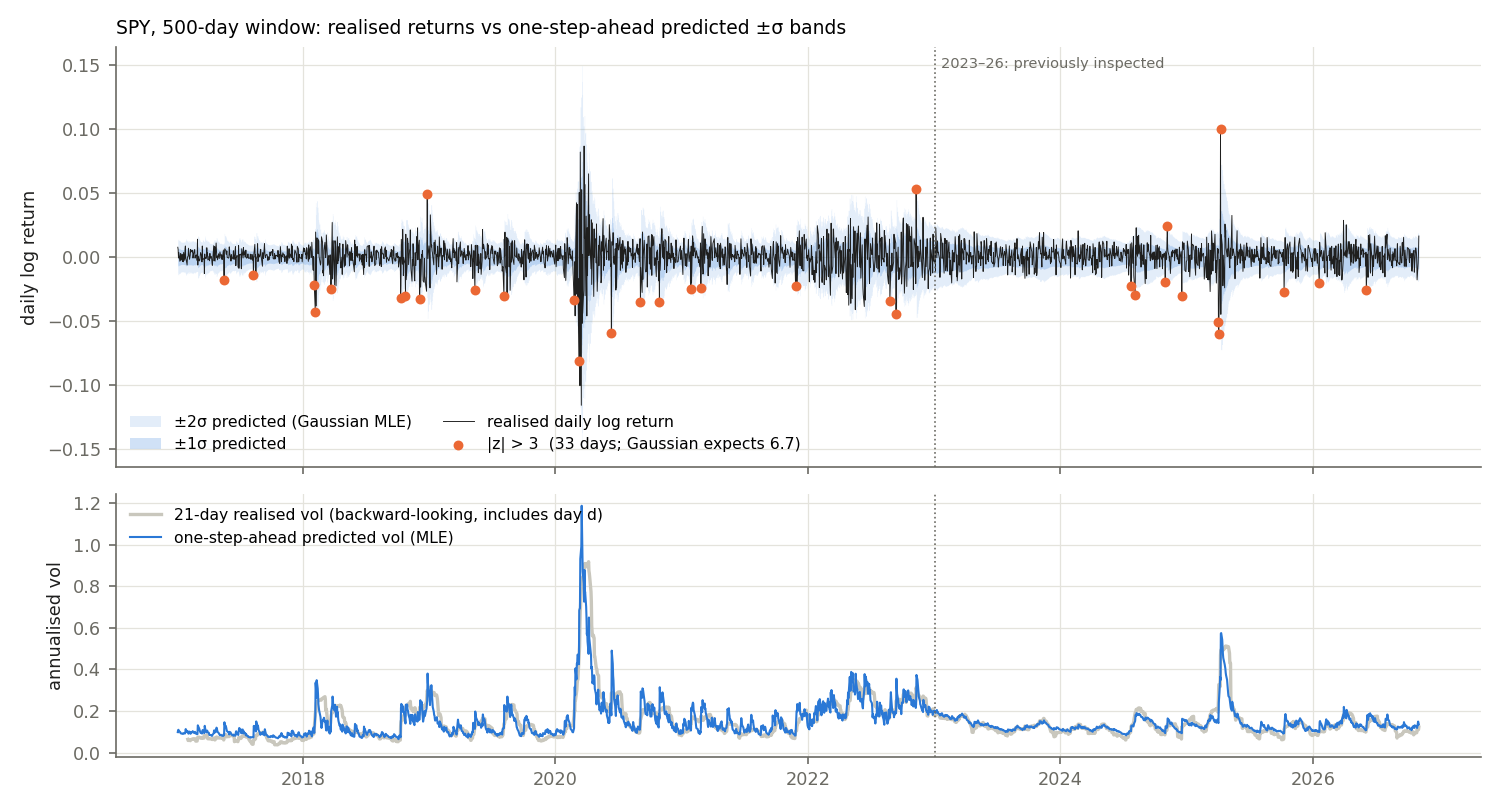

PASS  regenerated adequacy_returns_QQQ.png is pixel-identical to the report figure


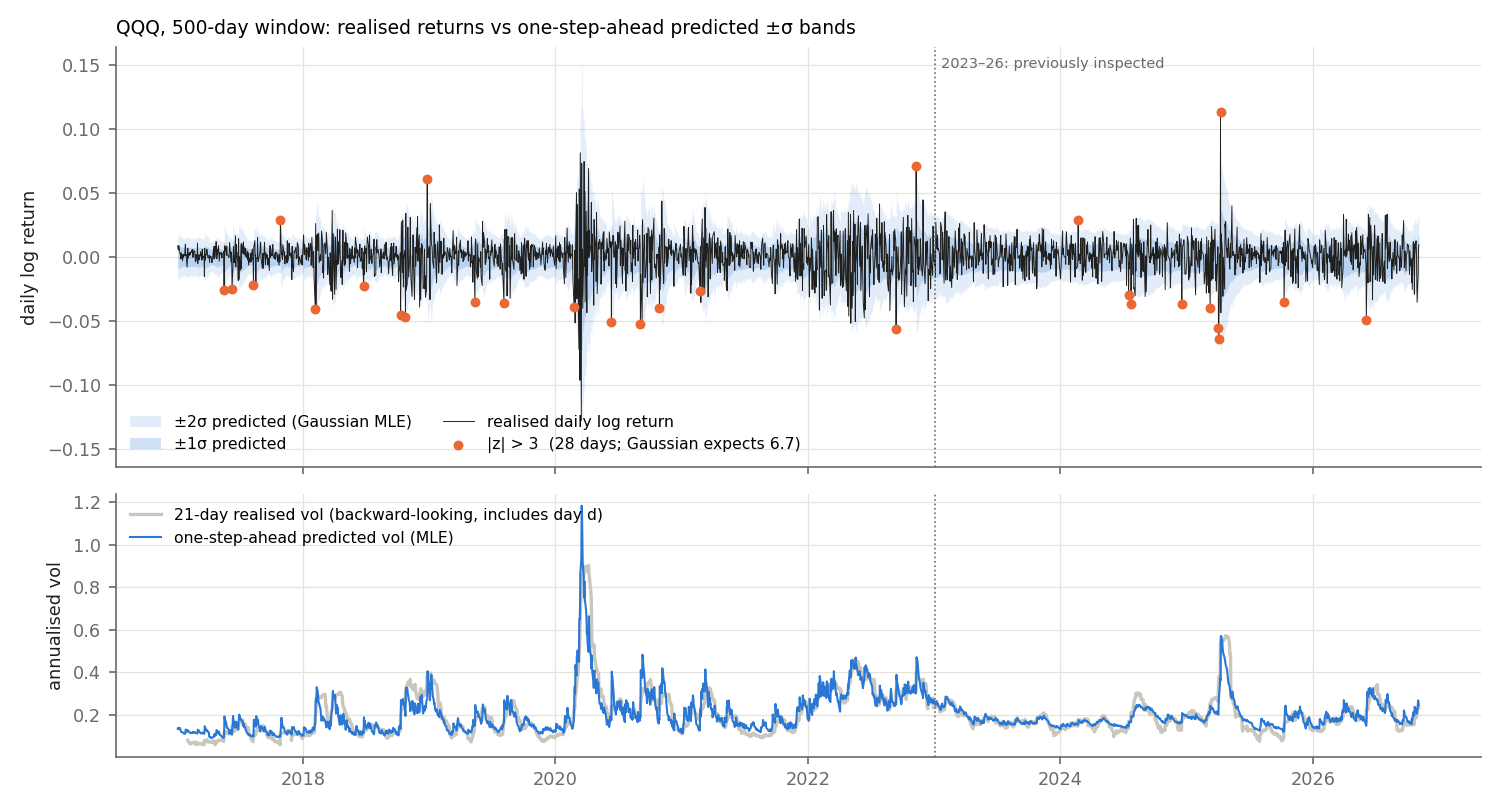

PASS  regenerated adequacy_returns_TLT.png is pixel-identical to the report figure


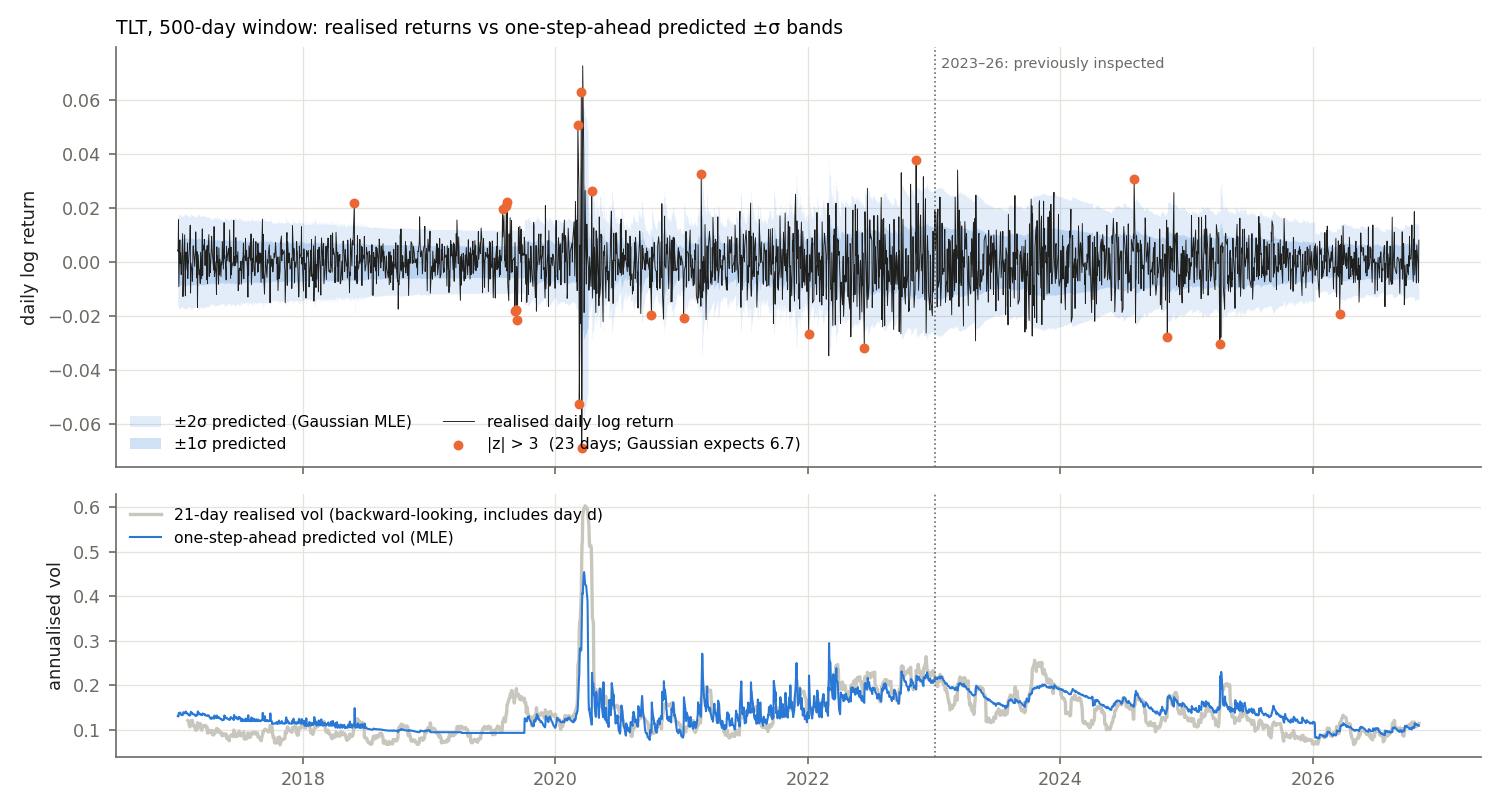

PASS  regenerated adequacy_returns_GLD.png is pixel-identical to the report figure


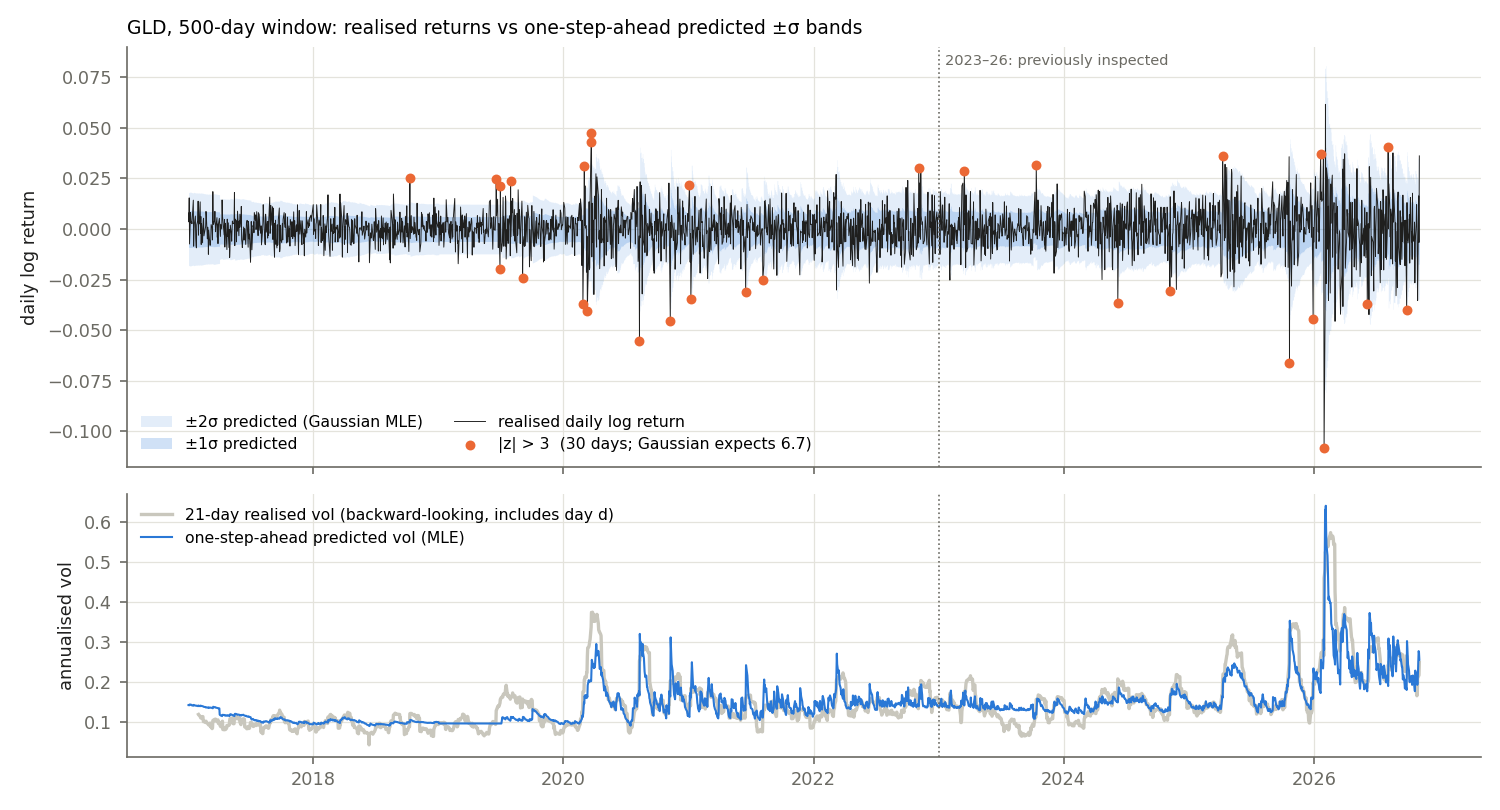

,days,inside_1sd,inside_2sd,abs_z_gt_3,expected_if_gaussian
asset,,,,,
SPY,2474,0.710,0.949,33,6.679
QQQ,2474,0.708,0.941,28,6.679
TLT,2474,0.711,0.949,23,6.679
GLD,2474,0.716,0.932,30,6.679


PASS  |z|>3 on 23-33 of 2,474 days per ETF vs 6.7 expected (report App. A)  [23-33]


In [44]:
band_rows = []
for a in ASSETS:
    show_regen(A.fig_returns_bands, a)
    f_, _ = A.load_panel(a, 500); z = A.std_resid(f_, 'mle')
    band_rows.append(dict(asset=a, days=len(z), inside_1sd=np.mean(np.abs(z) < 1), inside_2sd=np.mean(np.abs(z) < 2),
                          abs_z_gt_3=int((np.abs(z) > 3).sum()), expected_if_gaussian=2 * norm.sf(3) * len(z)))
BAND = pd.DataFrame(band_rows).set_index('asset'); display(BAND.round(3))
check('|z|>3 on 23-33 of 2,474 days per ETF vs 6.7 expected (report App. A)', BAND.abs_z_gt_3.between(23, 33).all() and (BAND.days == 2474).all(),
      f'{BAND.abs_z_gt_3.min()}-{BAND.abs_z_gt_3.max()}')

**Interpretation.** Over 2017–26, 69–73% of returns fall inside ±1σ (Gaussian: 68.3%) and only 93–95% inside ±2σ
(Gaussian: 95.4%). The out-of-sample residuals are more peaked in the centre and heavier in the tails than the
forecast distribution. The number of $|z|>3$ days is several times the Gaussian expectation for every ETF. The
predicted volatility follows the realised-volatility proxy closely and *leads* it at turning points, as it should.
**The second moment is tracked well; the extremes are not.**

### 11.2 All forecasts side by side

Each figure uses small multiples:
- three model groups (point estimates; parameter-uncertainty variants; other models), each drawn against the MLE
  forecast (grey dashed) and the realised-volatility proxy (light grey);
- a right-hand column showing each forecast **divided by the MLE forecast**, which makes differences of 1–5% visible.

PASS  regenerated adequacy_models_SPY_2017_2022.png is pixel-identical to the report figure


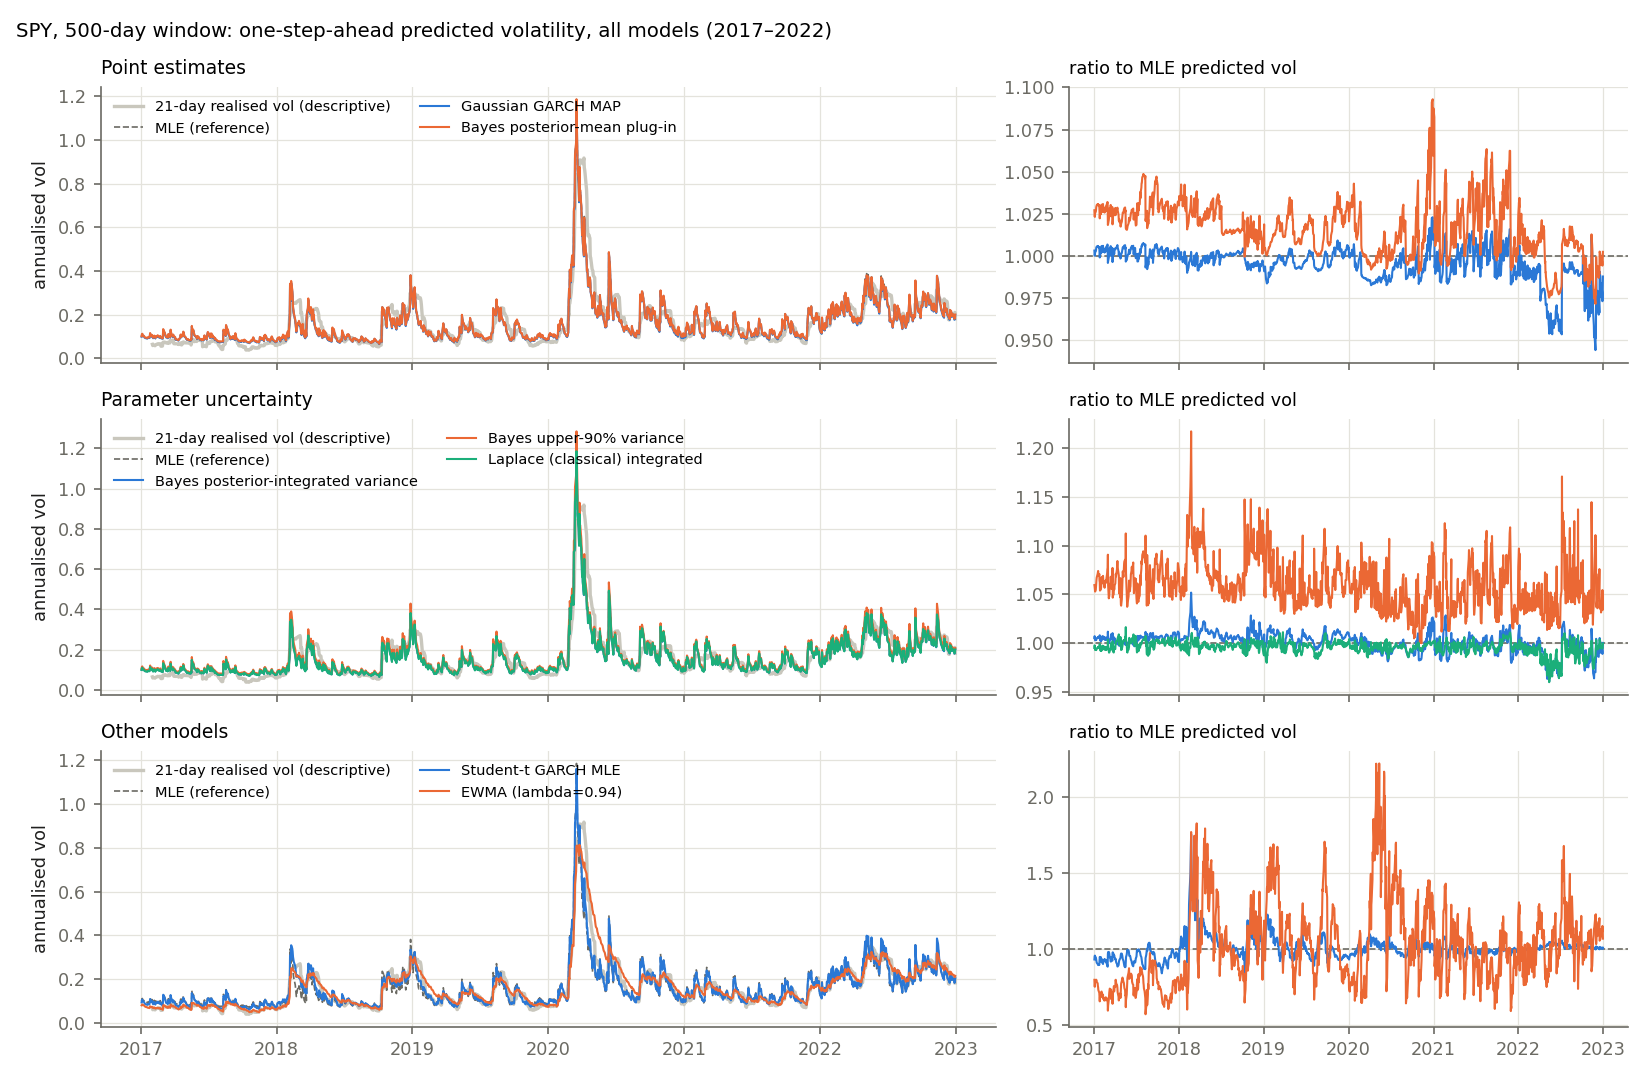

PASS  regenerated adequacy_models_QQQ_2017_2022.png is pixel-identical to the report figure


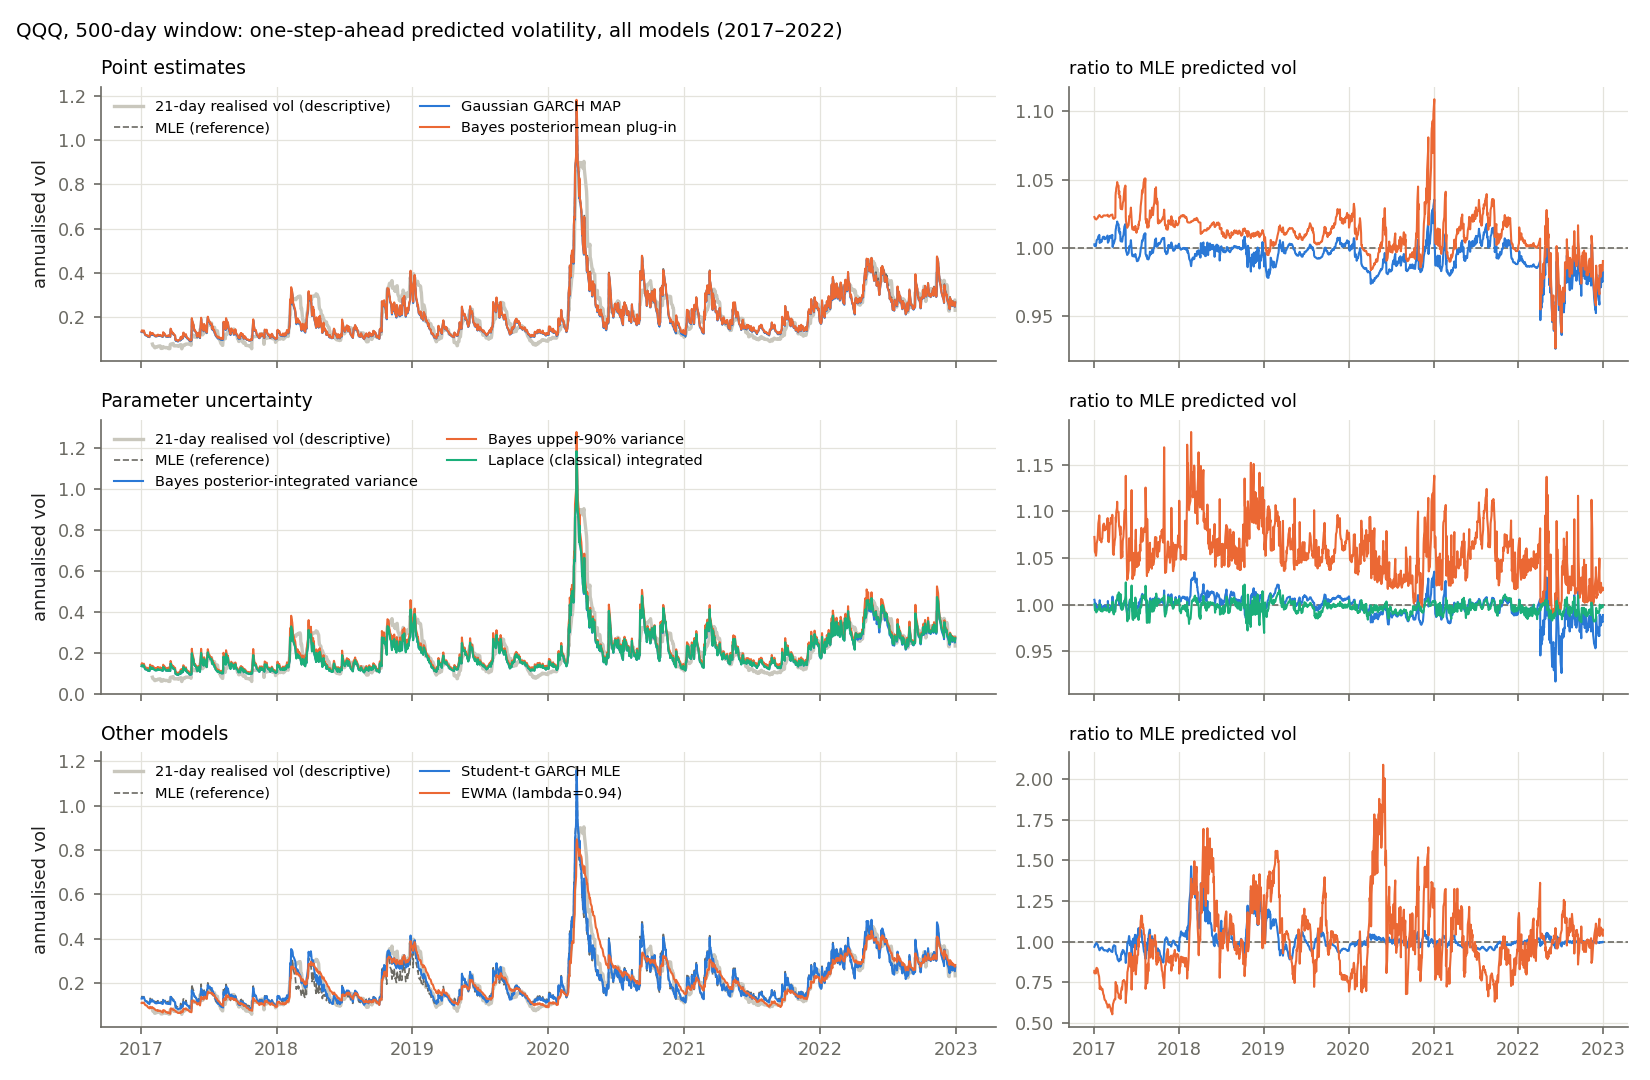

PASS  regenerated adequacy_models_TLT_2017_2022.png is pixel-identical to the report figure


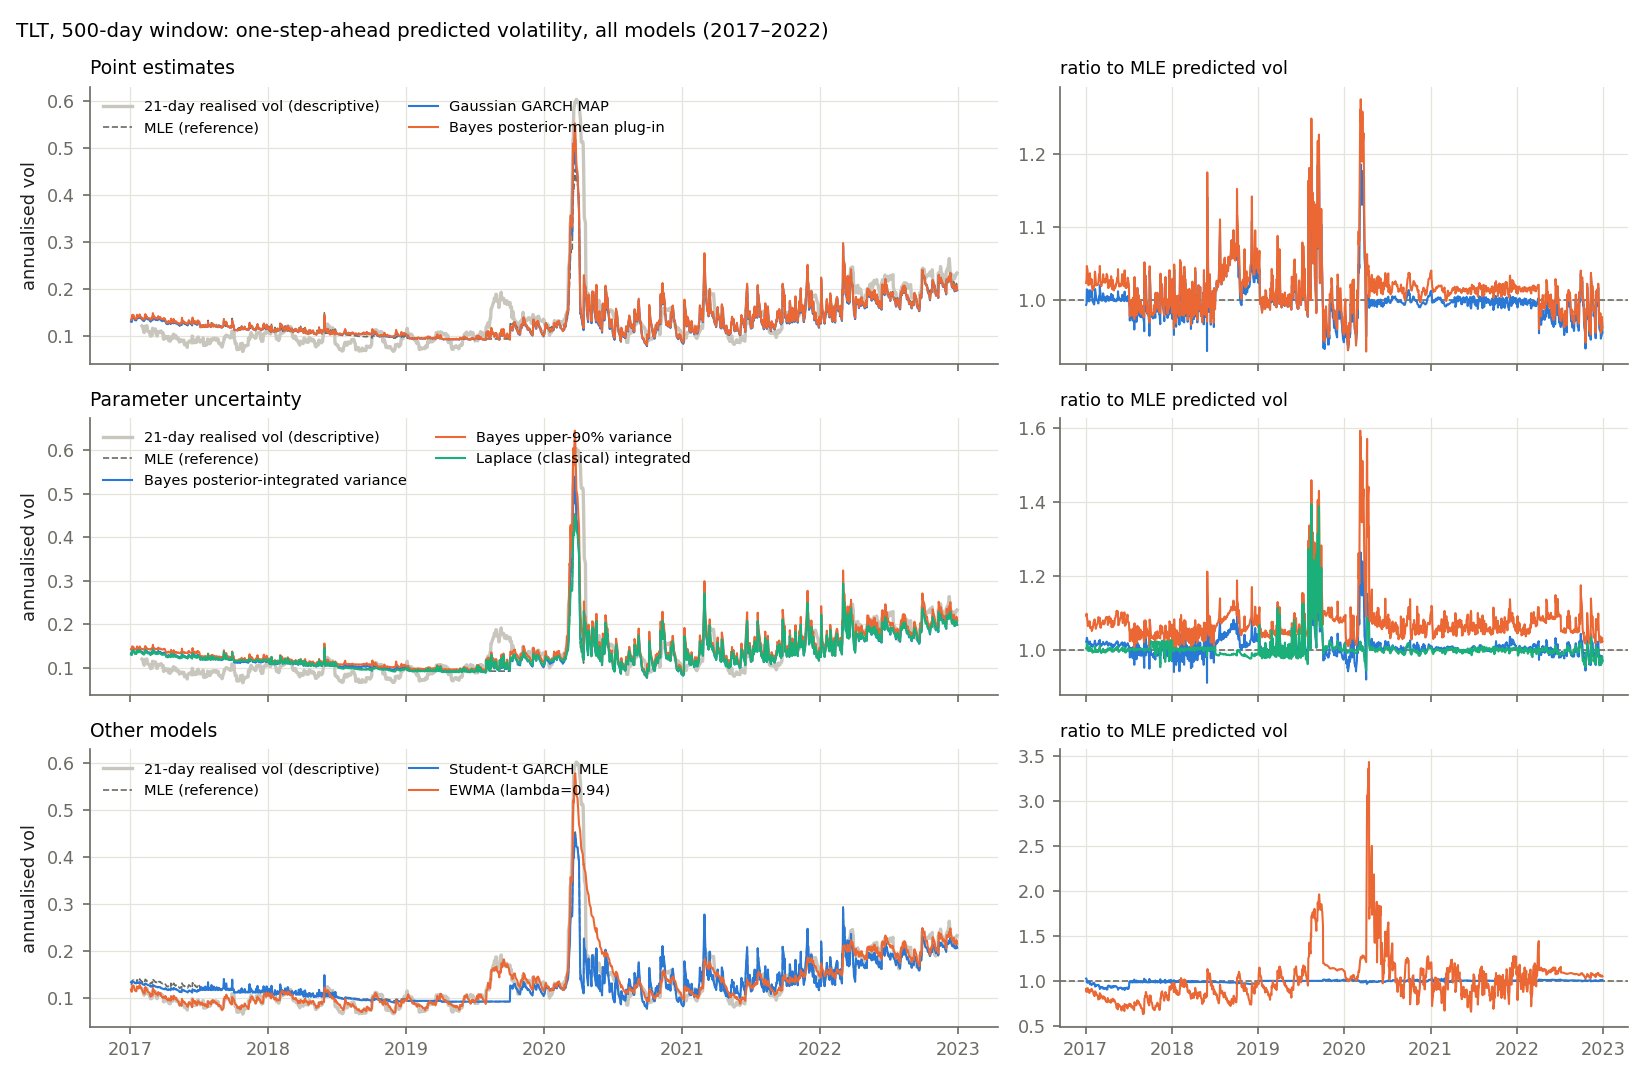

PASS  regenerated adequacy_models_GLD_2017_2022.png is pixel-identical to the report figure


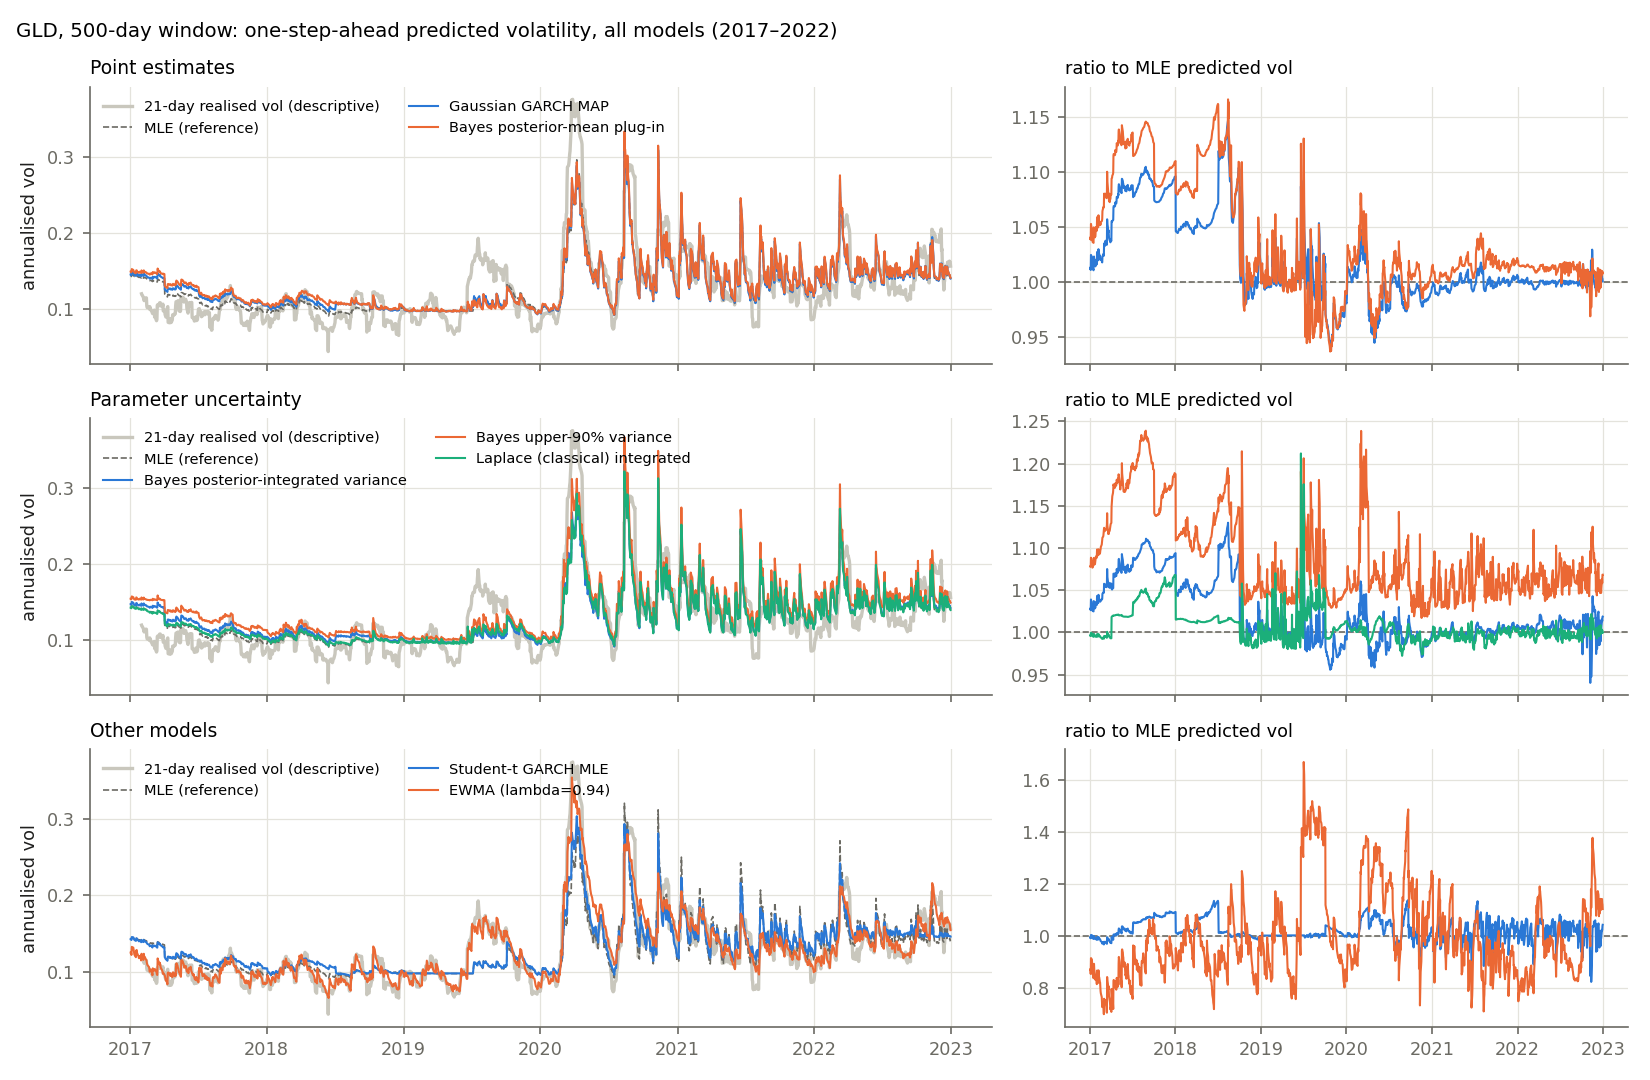

PASS  regenerated adequacy_models_SPY_2023_2026.png is pixel-identical to the report figure


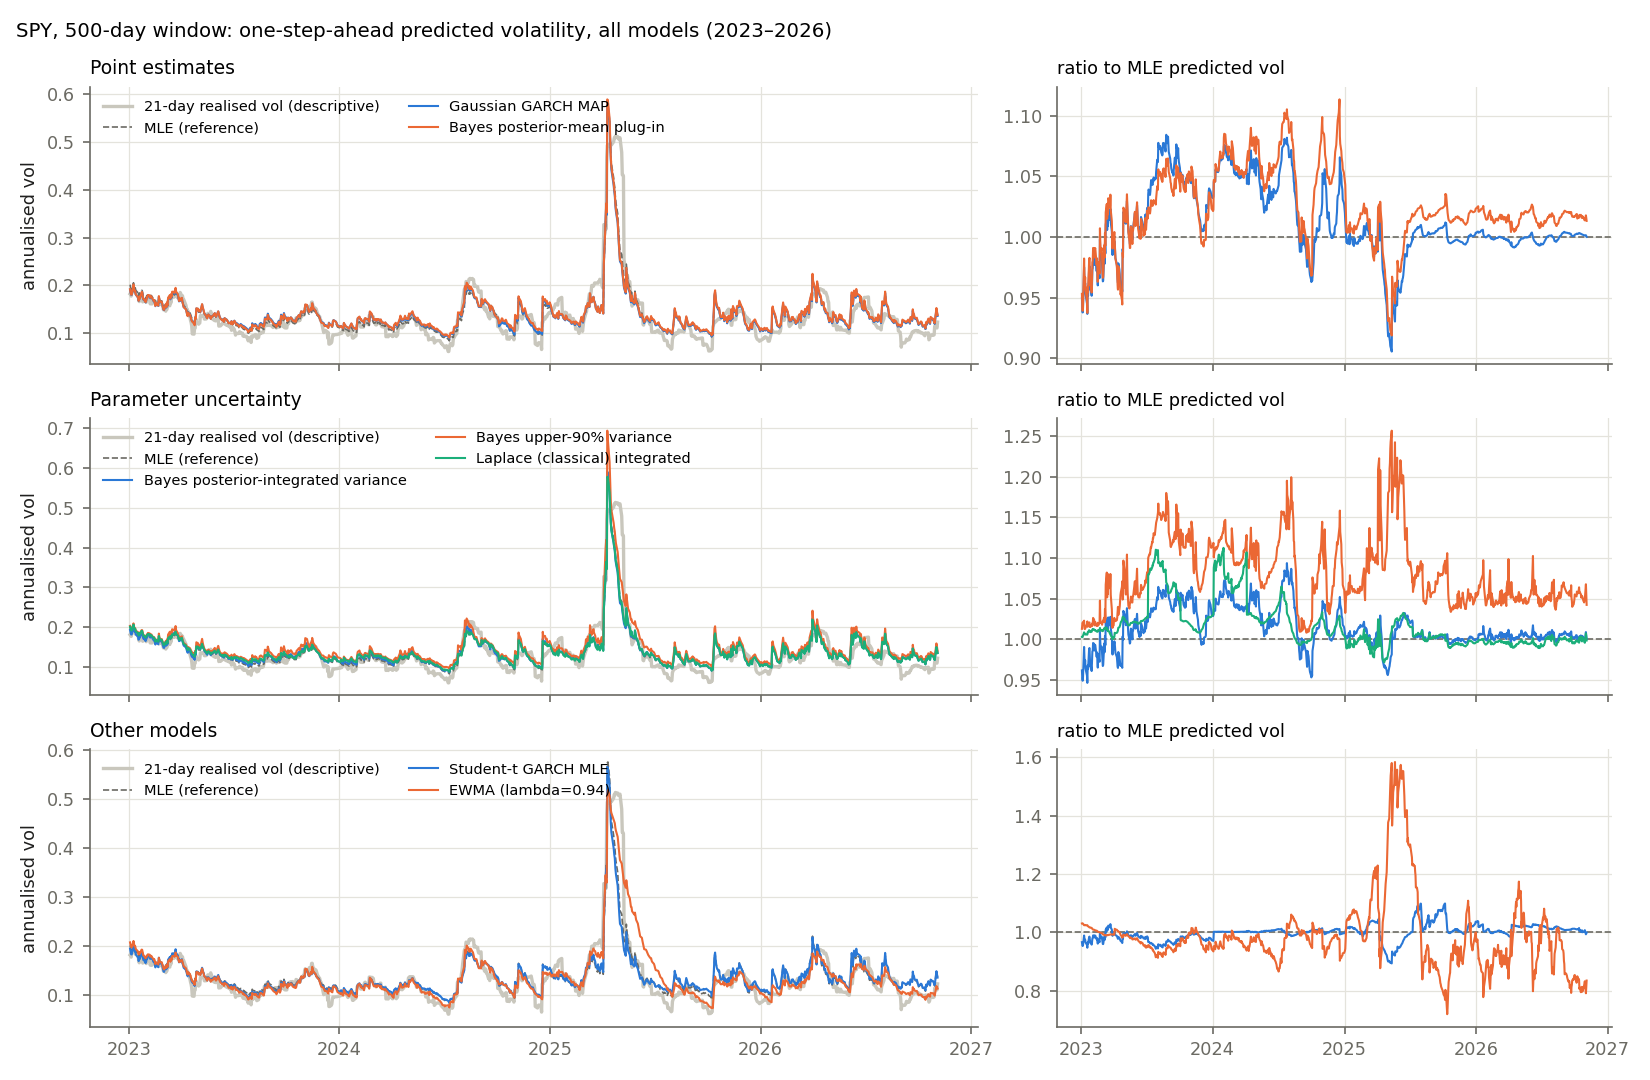

In [45]:
for a in ASSETS:
    show_regen(A.fig_model_comparison, a)
show_regen(A.fig_model_comparison, 'SPY', '2023-01-01', '2026-12-31', tag='2023_2026')

**What the comparison shows (2017–22).** Ranges below are the central 96% of each forecast's ratio to the MLE forecast.
- MAP, posterior-mean plug-in, posterior-integrated and Laplace-integrated stay within about ±5% of MLE for SPY and
  QQQ, and within about ±10–14% for TLT and GLD, whose posteriors are wider. The parameter treatment changes the
  *level* slightly but hardly changes the *shape* of the forecast path.
- The upper-90% variance sits 2–12% above MLE in volatility for equities, and up to about 30% for TLT and GLD. It is
  widest just after shocks; this is the "haircut" of §12–§13.
- EWMA differs most: too low in calm periods, slower to rise and much slower to decay (0.65–1.8 × MLE).
- Student-$t$ GARCH ranges from about −11% to +27% of MLE.

### 11.3 Diagnostic tests on standardised residuals and the PIT

For each model and ETF (500-day window, 2017–22, $n=1{,}510$):
1. **Variance calibration**: $\overline{z^2}\approx1$.
2. **Remaining linear dependence**: Ljung–Box $Q(m)$ on $z_d$, approximately $\chi^2_m$.
3. **Remaining volatility clustering**: Ljung–Box on $z_d^2$ (McLeod–Li). If GARCH captured the clustering, the
   autocorrelation of $z^2$ should be near zero even though that of $r^2$ is large.
4. **Calibration of the whole distribution (PIT).** If $F_d$ is the true predictive CDF, $u_d=F_d(r_d)\sim U(0,1)$
   and $\Phi^{-1}(u_d)\sim N(0,1)$ (Berkowitz, 2001); KS tests $u_d$ against uniform. For the Bayesian mixture,
   $u_d=M^{-1}\sum_m\Phi(r_d/\sqrt{h^{(m)}_d})$ uses the full mixture CDF. For Student-$t$,
   $u_d=F_{t_\nu}(r_d/s_d)$ with $s_d=\sqrt{h_d(\nu-2)/\nu}$.
5. **Quantile exceedances** $P(u_d<\alpha)$ (lower tail, which is the VaR violation rate) and $P(u_d>1-\alpha)$
   (upper tail).

PASS  regenerated adequacy_diagnostics_SPY.png is pixel-identical to the report figure


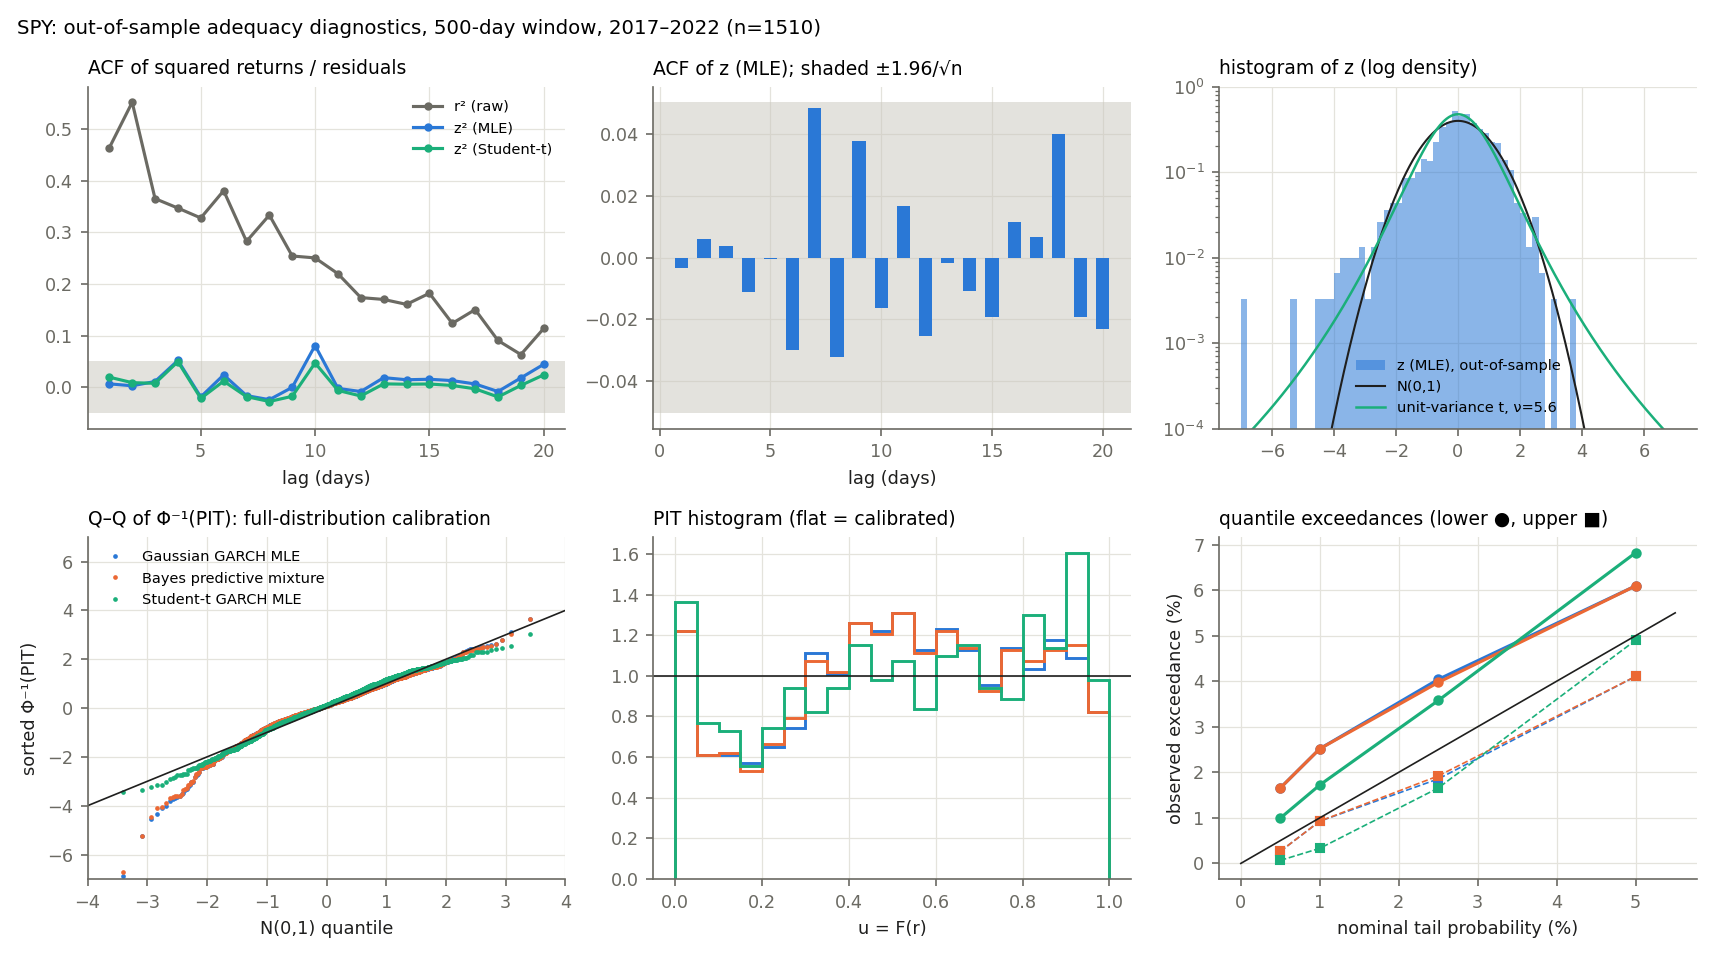

PASS  regenerated adequacy_diagnostics_QQQ.png is pixel-identical to the report figure


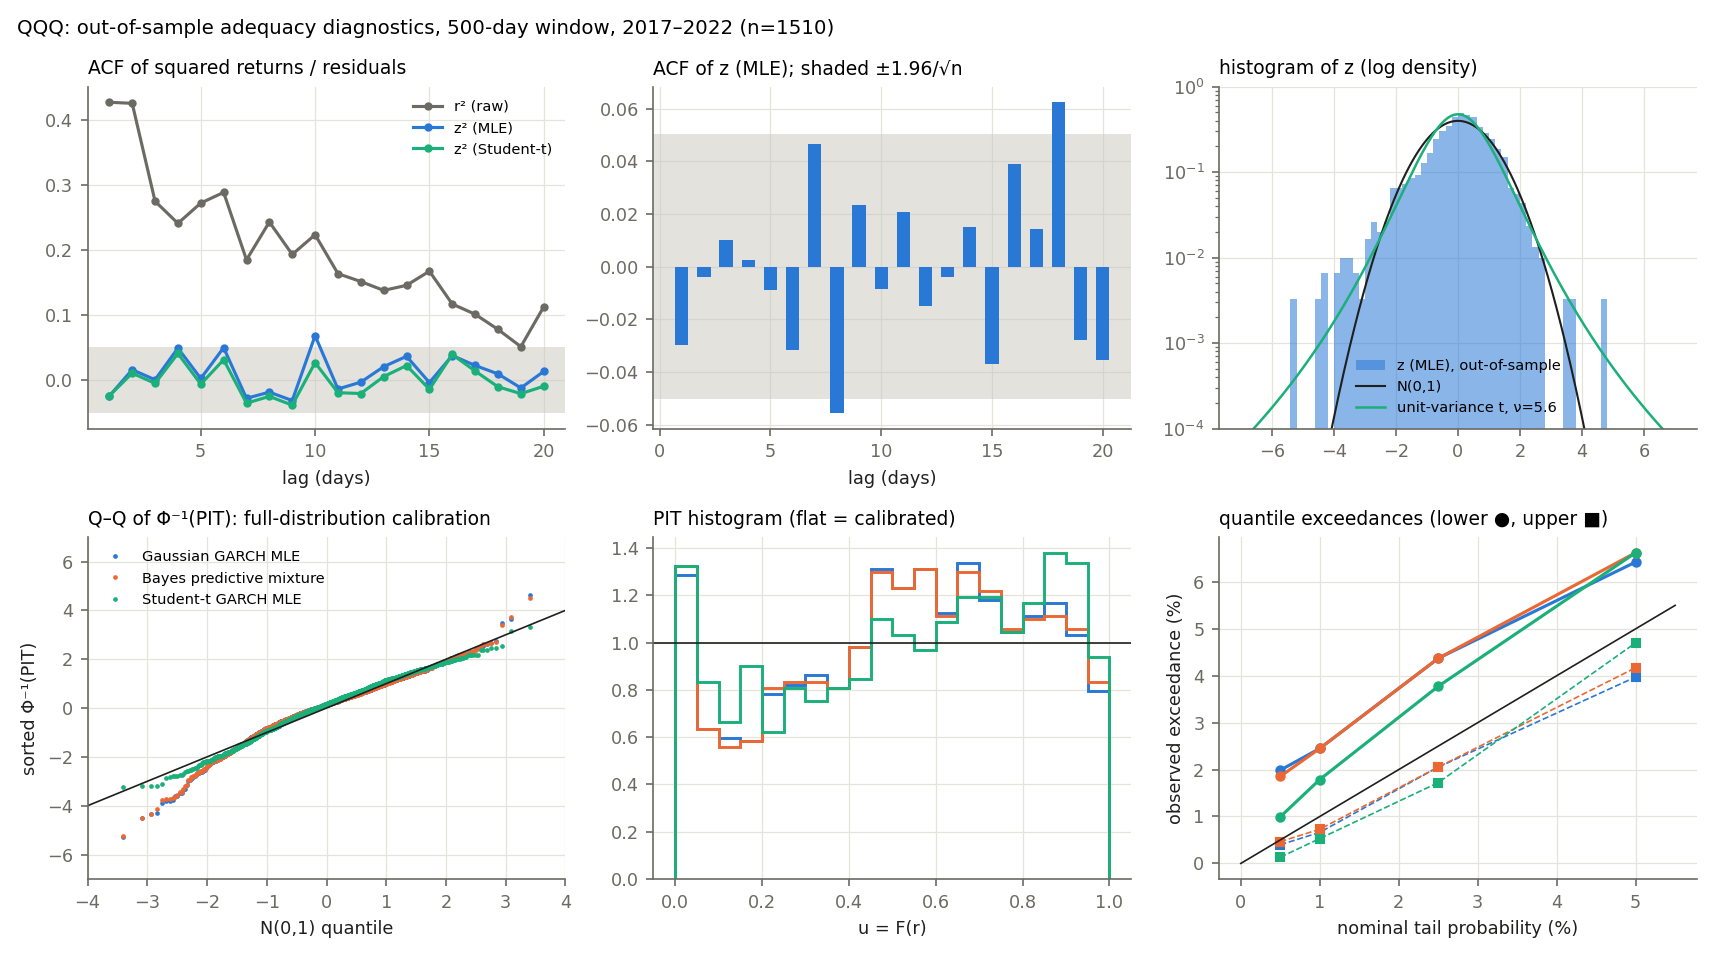

PASS  regenerated adequacy_diagnostics_TLT.png is pixel-identical to the report figure


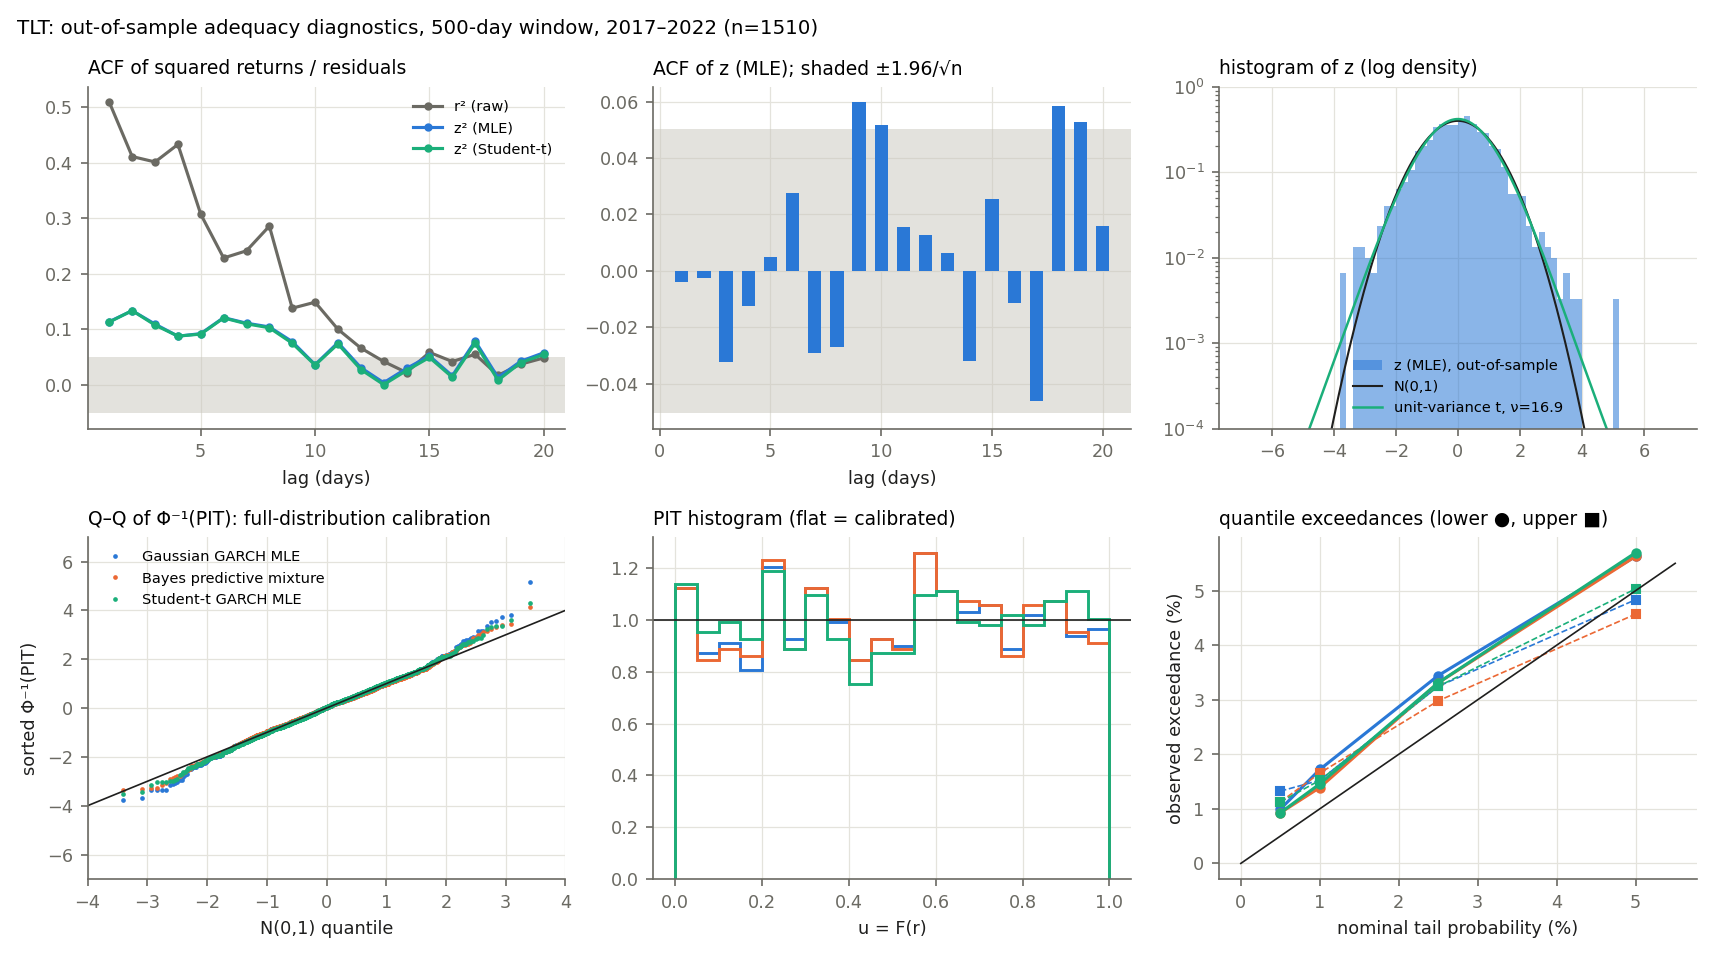

PASS  regenerated adequacy_diagnostics_GLD.png is pixel-identical to the report figure


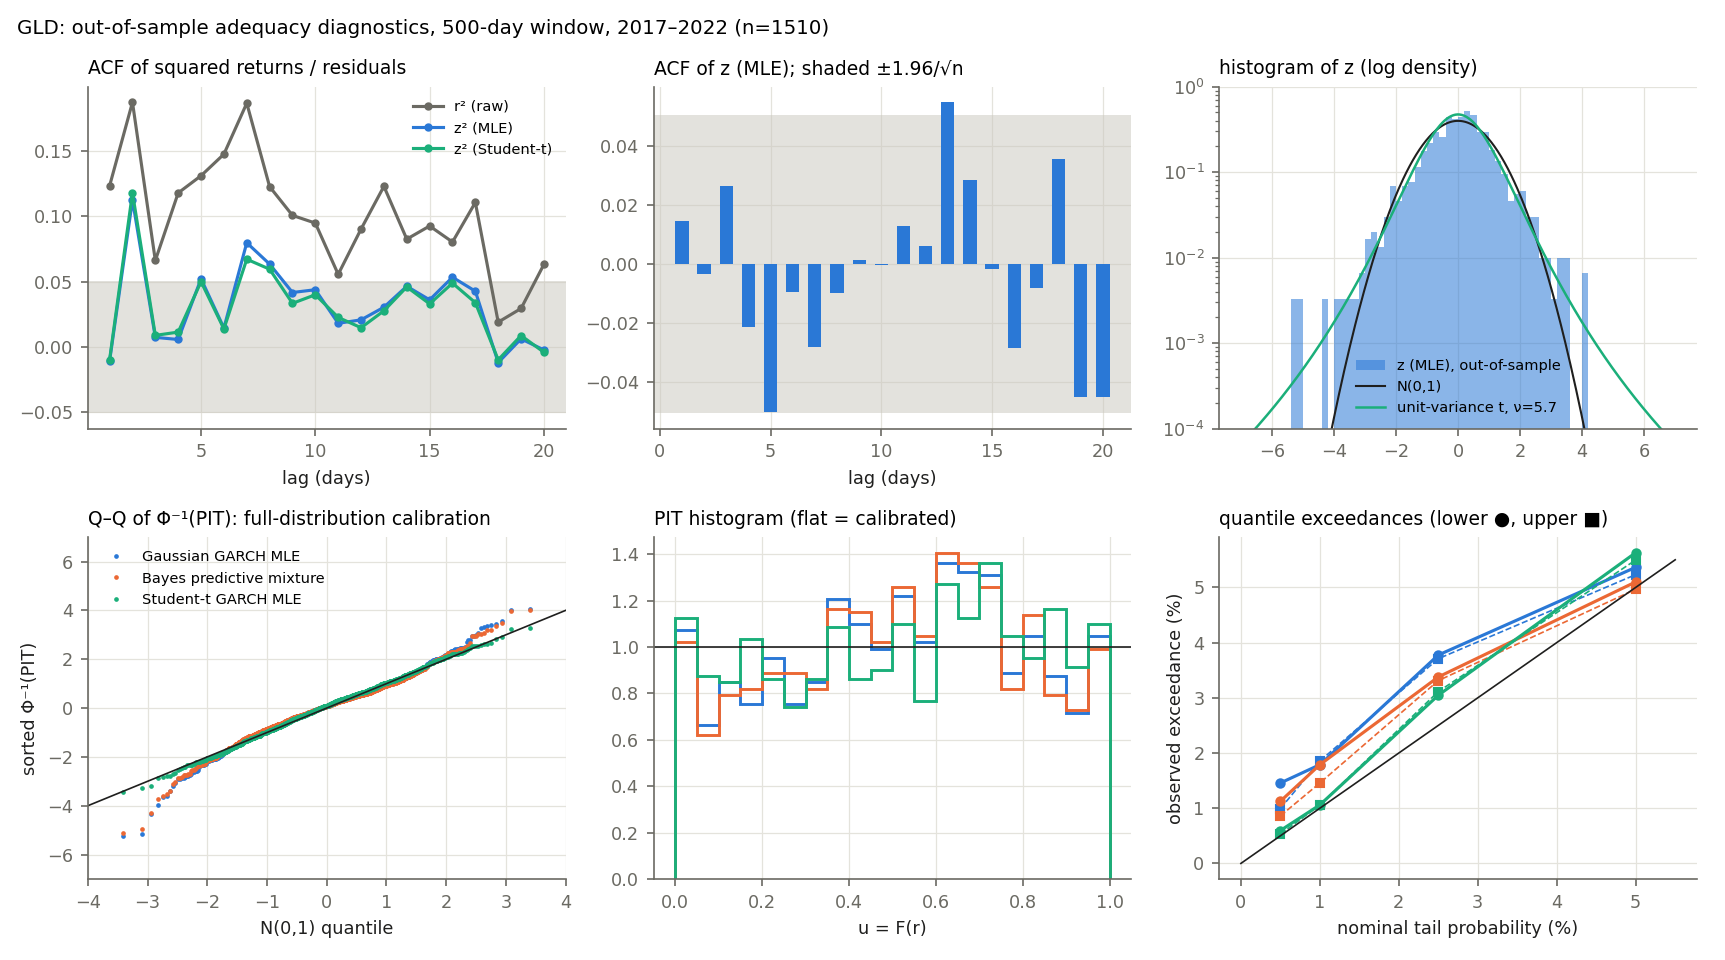

PASS  diagnostics table == saved artifacts/results/adequacy/diagnostics_w500_ext.csv


mean_z2  skew_z  exkurt_z  exkurt_normal_scores  acf1_z2  lb10_z_p  lb10_z2_p  lower01  upper01  lower05  upper05  ks_pit_p
asset model                                                                                                                                              
SPY   raw returns (no model)      NaN     NaN       NaN                   NaN    0.464     0.000      0.000      NaN      NaN      NaN      NaN       NaN
      mle                       1.085  -0.854     2.914                 2.914    0.006     0.493      0.076    0.025    0.009    0.061    0.041     0.000
      ewma                      1.162  -1.046     4.467                 3.522    0.092     0.069      0.000    0.028    0.008    0.055    0.048     0.000
      t                         1.069  -0.884     3.125                 0.015    0.019     0.480      0.365    0.017    0.003    0.068    0.049     0.000
      bayes_mixture             1.082  -0.854     2.915                 2.704    0.006     0.467      0.092    0.025    0.009    0.061    0.041     0.000
QQQ   raw returns (no model)      NaN     NaN       NaN                   NaN    0.427     0.000      0.000      NaN      NaN      NaN      NaN       NaN
      mle                       1.091  -0.671     1.954                 1.954   -0.024     0.276      0.040    0.025    0.007    0.064    0.040     0.000
      ewma                      1.144  -0.709     3.063                 3.063    0.032     0.063      0.008    0.025    0.010    0.059    0.047     0.000
      t                         1.065  -0.666     2.302                 0.027   -0.024     0.367      0.330    0.018    0.005    0.066    0.047     0.000
      bayes_mixture             1.095  -0.665     1.933                 1.809   -0.026     0.267      0.039    0.025    0.007    0.066    0.042     0.000
TLT   raw returns (no model)      NaN     NaN       NaN                   NaN    0.509     0.000      0.000      NaN      NaN      NaN      NaN       NaN
      mle                       1.106   0.045     0.969                 0.969    0.114     0.133      0.000    0.017    0.015    0.056    0.048     0.567
      ewma                      1.087   0.056     0.584                 0.584    0.055     0.298      0.337    0.014    0.017    0.055    0.048     0.622
      t                         1.116   0.047     0.943                 0.352    0.113     0.139      0.000    0.015    0.015    0.057    0.050     0.303
      bayes_mixture             1.066   0.030     0.686                 0.537    0.056     0.200      0.000    0.014    0.017    0.056    0.046     0.579
GLD   raw returns (no model)      NaN     NaN       NaN                   NaN    0.123     0.172      0.000      NaN      NaN      NaN      NaN       NaN
      mle                       1.076  -0.256     1.900                 1.900   -0.011     0.692      0.000    0.018    0.019    0.054    0.052     0.000
      ewma                      1.108  -0.274     1.933                 1.933   -0.031     0.809      0.612    0.020    0.023    0.054    0.055     0.000
      t                         1.035  -0.256     2.006                 0.077   -0.010     0.702      0.000    0.011    0.011    0.056    0.055     0.002
      bayes_mixture             1.038  -0.263     1.983                 1.831   -0.011     0.660      0.000    0.018    0.015    0.051    0.050     0.000

In [46]:
for a in ASSETS:
    show_regen(A.fig_diagnostics, a, width=980)
diag_ext = A.diagnostics_table(500, 'ext')
check('diagnostics table == saved artifacts/results/adequacy/diagnostics_w500_ext.csv',
      np.allclose(diag_ext.select_dtypes('number').to_numpy(float), pd.read_csv(cfg.RESULTS / 'adequacy/diagnostics_w500_ext.csv').select_dtypes('number').to_numpy(float), equal_nan=True))
cols = ['mean_z2', 'skew_z', 'exkurt_z', 'exkurt_normal_scores', 'acf1_z2', 'lb10_z_p', 'lb10_z2_p', 'lower01', 'upper01', 'lower05', 'upper05', 'ks_pit_p']
display(diag_ext[diag_ext.model.isin(['raw returns (no model)', 'mle', 'bayes_mixture', 't', 'ewma'])].set_index(['asset', 'model'])[cols].round(3))

**Reading the diagnostics** (report Appendix A table).
- **Clustering is largely captured for SPY and QQQ.** Raw $r^2$ has lag-1 autocorrelation of about 0.45. After
  standardising by the GARCH forecast it is about 0. $Q_{10}(z^2)$ is borderline for the Gaussian models and not
  significant for Student-$t$.
- **TLT and GLD are only partly captured.** TLT keeps an autocorrelation of about 0.1 in $z^2$ up to lag 8
  ($p<0.001$): bond volatility shifted between regimes in 2020–22 faster than a quarterly-refitted GARCH(1,1) adapts.
- **No linear predictability** in $z$, as expected for liquid ETFs.
- **Variance level.** $\overline{z^2}\approx1.04$–$1.12$: variance is under-predicted by roughly 5–10% on average,
  driven by the shock days.
- **Gaussian tails are too thin.**
  - The excess kurtosis of $z$ is 1.9–2.9 for SPY, QQQ and GLD.
  - Lower-tail 1% exceedances reach 2.5% for SPY and QQQ.
  - The Bayesian mixture's full-CDF normal scores reduce excess kurtosis only from 2.9 to 2.7 for SPY.
- **Student-$t$ fixes symmetric fat tails but not asymmetry.**
  - Its normal scores have excess kurtosis near 0, and GLD's tails become well calibrated.
  - Equity residuals are negatively skewed ($-0.67$ to $-0.85$). Every symmetric model has too many lower-tail and
    too few upper-tail exceedances (SPY Student-$t$: 1.7% and 0.3%).
  - The PIT is rejected for every equity model.

**What these diagnostics establish and what they cannot.** They show *which moments and which tails* are
misspecified, out of sample. They cannot identify the true model, and their $p$-values are approximate. Passing a
test does not establish correctness, only a failure to detect misspecification with 1,510 days.

In [47]:
dsel = diag_ext.set_index(['asset', 'model'])
raw_acf = dsel.xs('raw returns (no model)', level='model').acf1_z2
check('ACF1 of r^2 is 0.43-0.51 for SPY, QQQ, TLT (report App. A)', raw_acf[['SPY', 'QQQ', 'TLT']].between(.425, .515).all(), raw_acf.round(3).to_dict().__str__())
check('Gaussian MLE: excess kurtosis of z 1.9-2.9 for SPY, QQQ, GLD', dsel.xs('mle', level='model').exkurt_z[['SPY', 'QQQ', 'GLD']].between(1.85, 2.95).all())
check('SPY: mixture normal-score excess kurtosis 2.9 -> 2.7', round(dsel.loc[('SPY', 'mle'), 'exkurt_normal_scores'], 1) == 2.9 and round(dsel.loc[('SPY', 'bayes_mixture'), 'exkurt_normal_scores'], 1) == 2.7)
check('SPY Student-t: lower/upper 1% exceedance 1.7% / 0.3%', round(dsel.loc[('SPY', 't'), 'lower01'] * 100, 1) == 1.7 and round(dsel.loc[('SPY', 't'), 'upper01'] * 100, 1) == 0.3)
check('equity residual skewness -0.67 to -0.85', dsel.xs('mle', level='model').skew_z[['SPY', 'QQQ']].between(-.855, -.665).all())

PASS  ACF1 of r^2 is 0.43-0.51 for SPY, QQQ, TLT (report App. A)  [{'SPY': 0.464, 'QQQ': 0.427, 'TLT': 0.509, 'GLD': 0.123}]
PASS  Gaussian MLE: excess kurtosis of z 1.9-2.9 for SPY, QQQ, GLD
PASS  SPY: mixture normal-score excess kurtosis 2.9 -> 2.7
PASS  SPY Student-t: lower/upper 1% exceedance 1.7% / 0.3%
PASS  equity residual skewness -0.67 to -0.85


### 11.4 Value-at-Risk back-test (report Table 5)

A one-day VaR at level $\alpha$ is violated when the loss exceeds it, $-r_d>\text{VaR}_{\alpha,d}$. Under correct
coverage, violations are iid Bernoulli($\alpha$).
- **Kupiec (1995)** tests the violation *rate* with the likelihood ratio
  $\text{LR}=-2\big[x\log\alpha+(n-x)\log(1-\alpha)-x\log\hat\pi-(n-x)\log(1-\hat\pi)\big]\sim\chi^2_1$, with
  $\hat\pi=x/n$.
- **Christoffersen (1998)** tests *independence*: whether a violation today predicts one tomorrow.

The table reports the mean violation rate over the 8 configurations and the number of Kupiec rejections at 5%.
🔵 *saved forecasts*

In [48]:
tail = {s: tables.tail_tables(s) for s in SEGS}
for s in SEGS:
    reft = pd.read_csv(cfg.SAVED_PRIMARY / f'tail_{s}.csv'); num = reft.select_dtypes('number').columns
    check(f'VaR back-test table {SEGL[s]} == research table', np.allclose(tail[s][num].to_numpy(float), reft[num].to_numpy(float), rtol=0, atol=1e-12, equal_nan=True))
VARM = [('mle', 'Gaussian, MLE'), ('bayes_meanplug', 'Gaussian, posterior-mean plug-in'), ('bayes_mixture', 'Bayesian predictive mixture'),
        ('laplace_mixture', 'Laplace mixture'), ('t', 'Student-t GARCH'), ('ewma', 'EWMA (Gaussian)')]
T6 = pd.DataFrame({(SEGL[s], f'{int(al*100)}%'): [f"{100*tail[s][(tail[s].method == m) & (tail[s].alpha == al)].rate.mean():.2f}% "
                                                    f"({int((tail[s][(tail[s].method == m) & (tail[s].alpha == al)].kupiec_p < .05).sum())}/8)" for m, _ in VARM]
                   for s in SEGS for al in (.01, .05)}, index=[lab for _, lab in VARM])
display(T6.style.set_caption('Mean VaR violation rate (Kupiec rejections at 5%, of 8 configurations)'))
r01 = {m: tail['ext'][(tail['ext'].method == m) & (tail['ext'].alpha == .01)].rate.mean() for m in ['mle', 'bayes_mixture', 't']}
check('2017-22, 1% VaR: Gaussian about 2% with or without integration, Student-t about 1.5% (report §5.1)',
      abs(r01['mle'] - .02) < .0025 and abs(r01['bayes_mixture'] - .02) < .0025 and abs(r01['t'] - .015) < .0015, {k: round(v, 4) for k, v in r01.items()}.__str__())

PASS  VaR back-test table 2017–22 == research table
PASS  VaR back-test table 2023–26 == research table


PASS  2017-22, 1% VaR: Gaussian about 2% with or without integration, Student-t about 1.5% (report §5.1)  [{'mle': 0.0215, 'bayes_mixture': 0.0206, 't': 0.0151}]


**Interpretation.** At the 1% level, Gaussian VaR is violated on about 2% of days in 2017–22, twice the nominal
rate, with or without posterior integration. Student-$t$ reduces this to about 1.5%. At 5%, all models are much
closer to nominal (4.8–6.3%): the problem is concentrated in the far tail. Parameter uncertainty does not fix tail risk, while the innovation
distribution partly does.

### 11.5 Stress periods

The three windows were chosen from where the realised shocks occurred, before any diagnostics were computed:
- the **COVID crash** (Feb–May 2020);
- the **2022 rate-hike sell-off** (Apr–Jul 2022);
- the **Mar–Jun 2025 equity shock** (previously inspected period).

The table quantifies:
- **reaction**: `jump_ratio`, the forecast after the largest shock divided by the forecast before it;
- **persistence**: `halflife_after_peak`, in trading days;
- **under-prediction**: `mean_z2` inside the window (≈1 if calibrated) and the number of $|z|>3$ days.

PASS  regenerated adequacy_stress_covid_2020.png is pixel-identical to the report figure


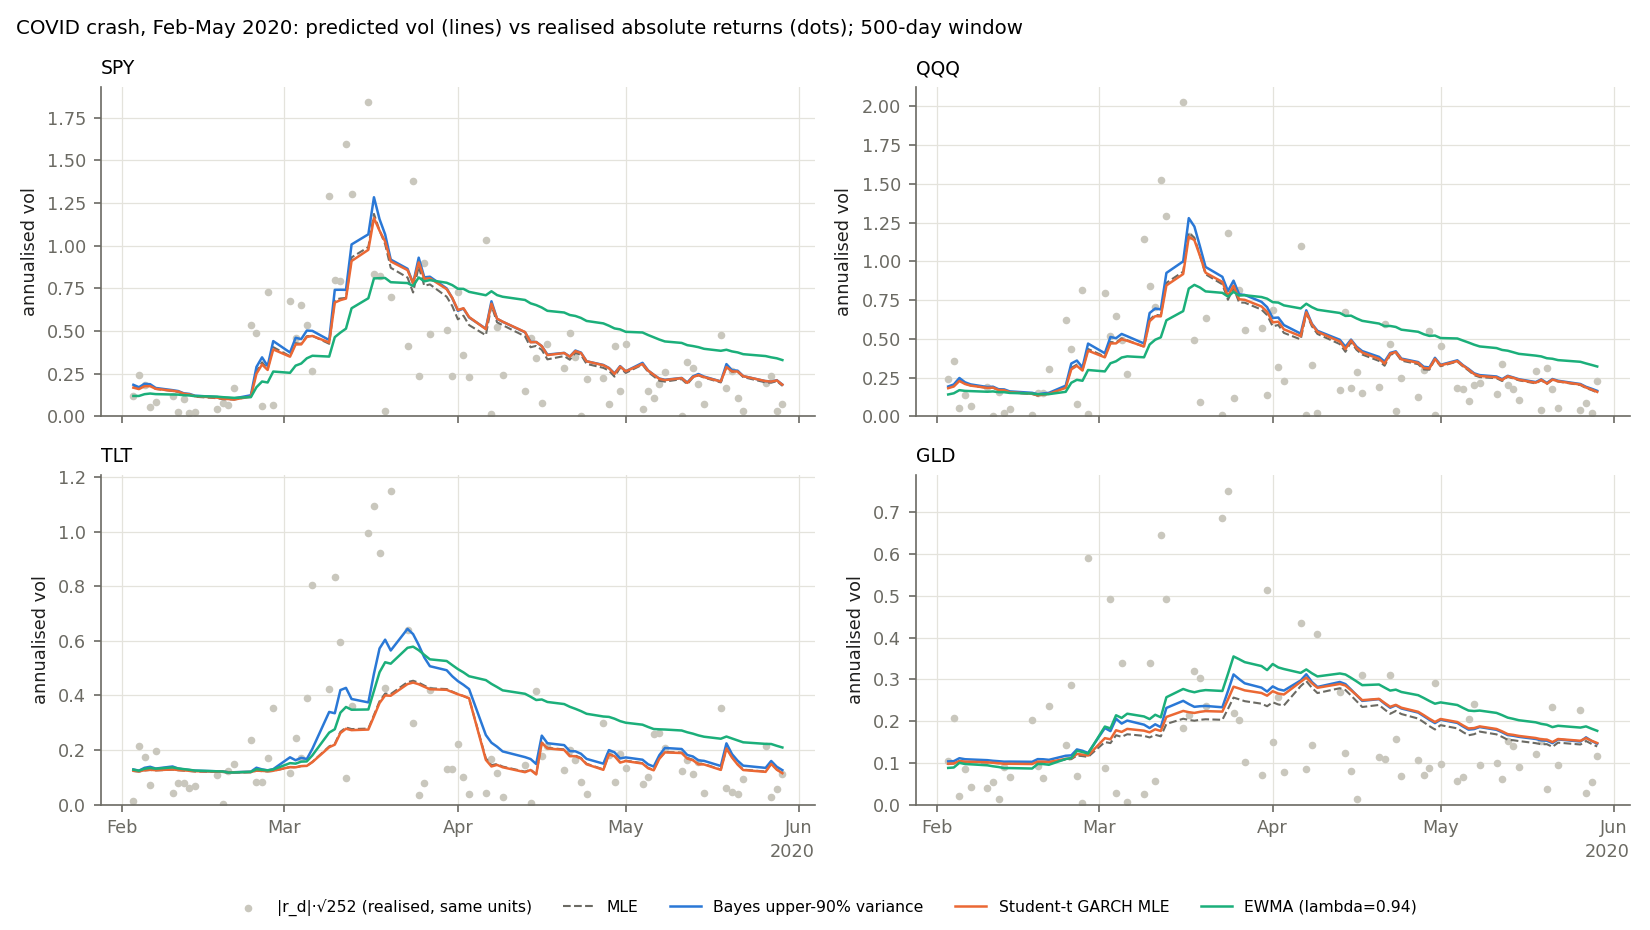

PASS  regenerated adequacy_stress_stress_2022.png is pixel-identical to the report figure


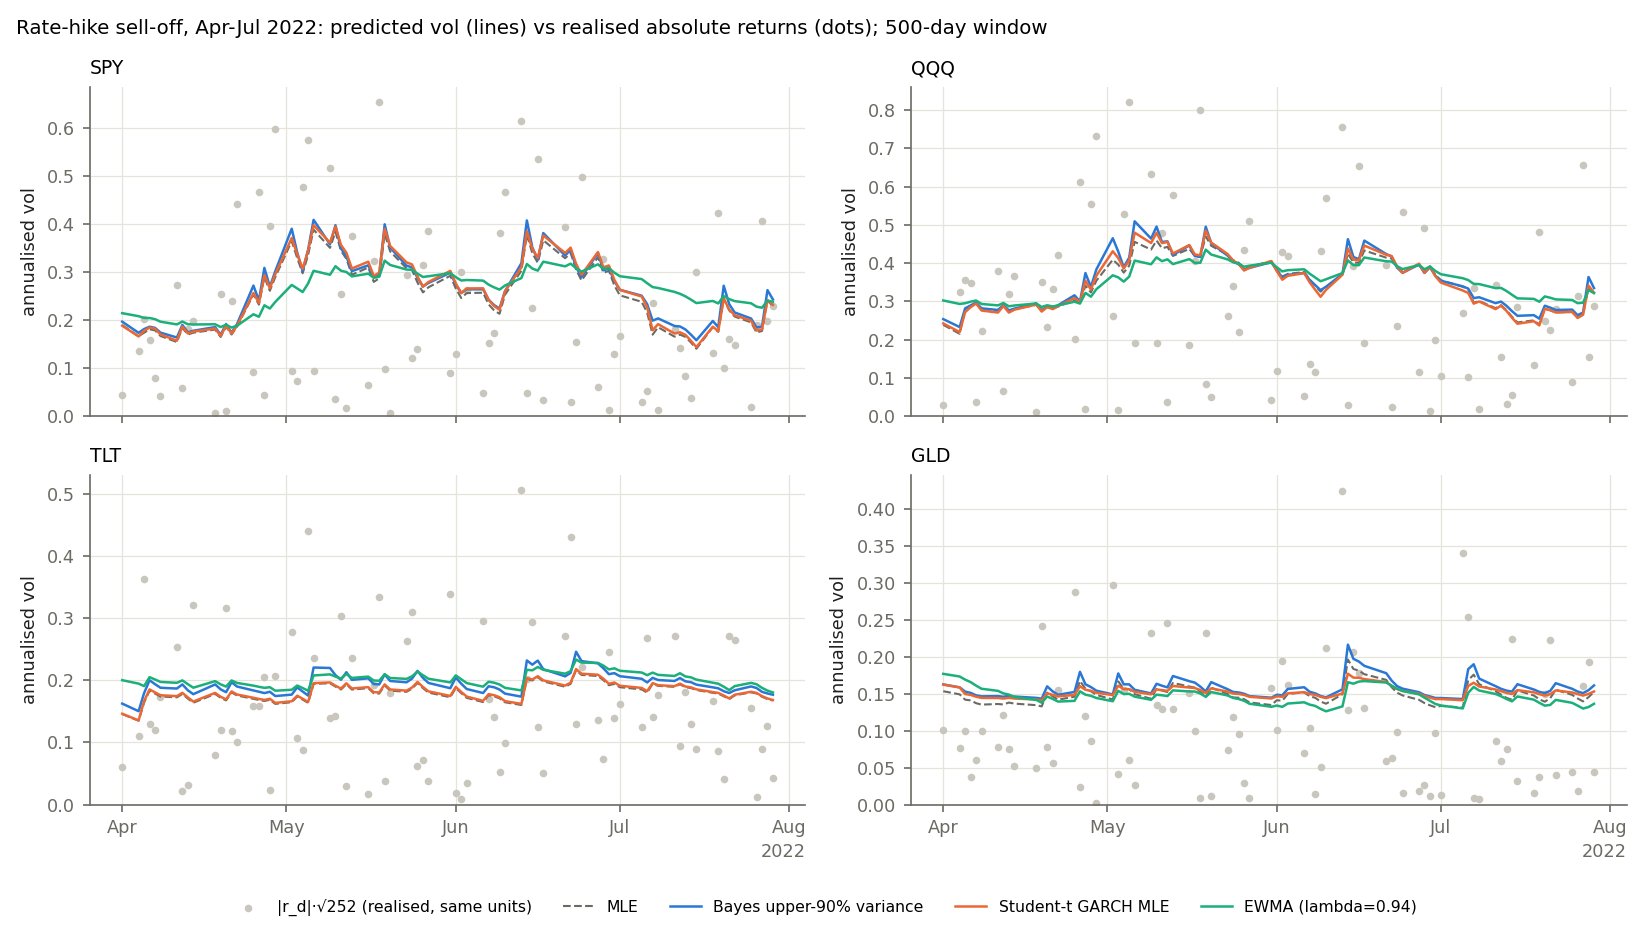

PASS  regenerated adequacy_stress_shock_2025.png is pixel-identical to the report figure


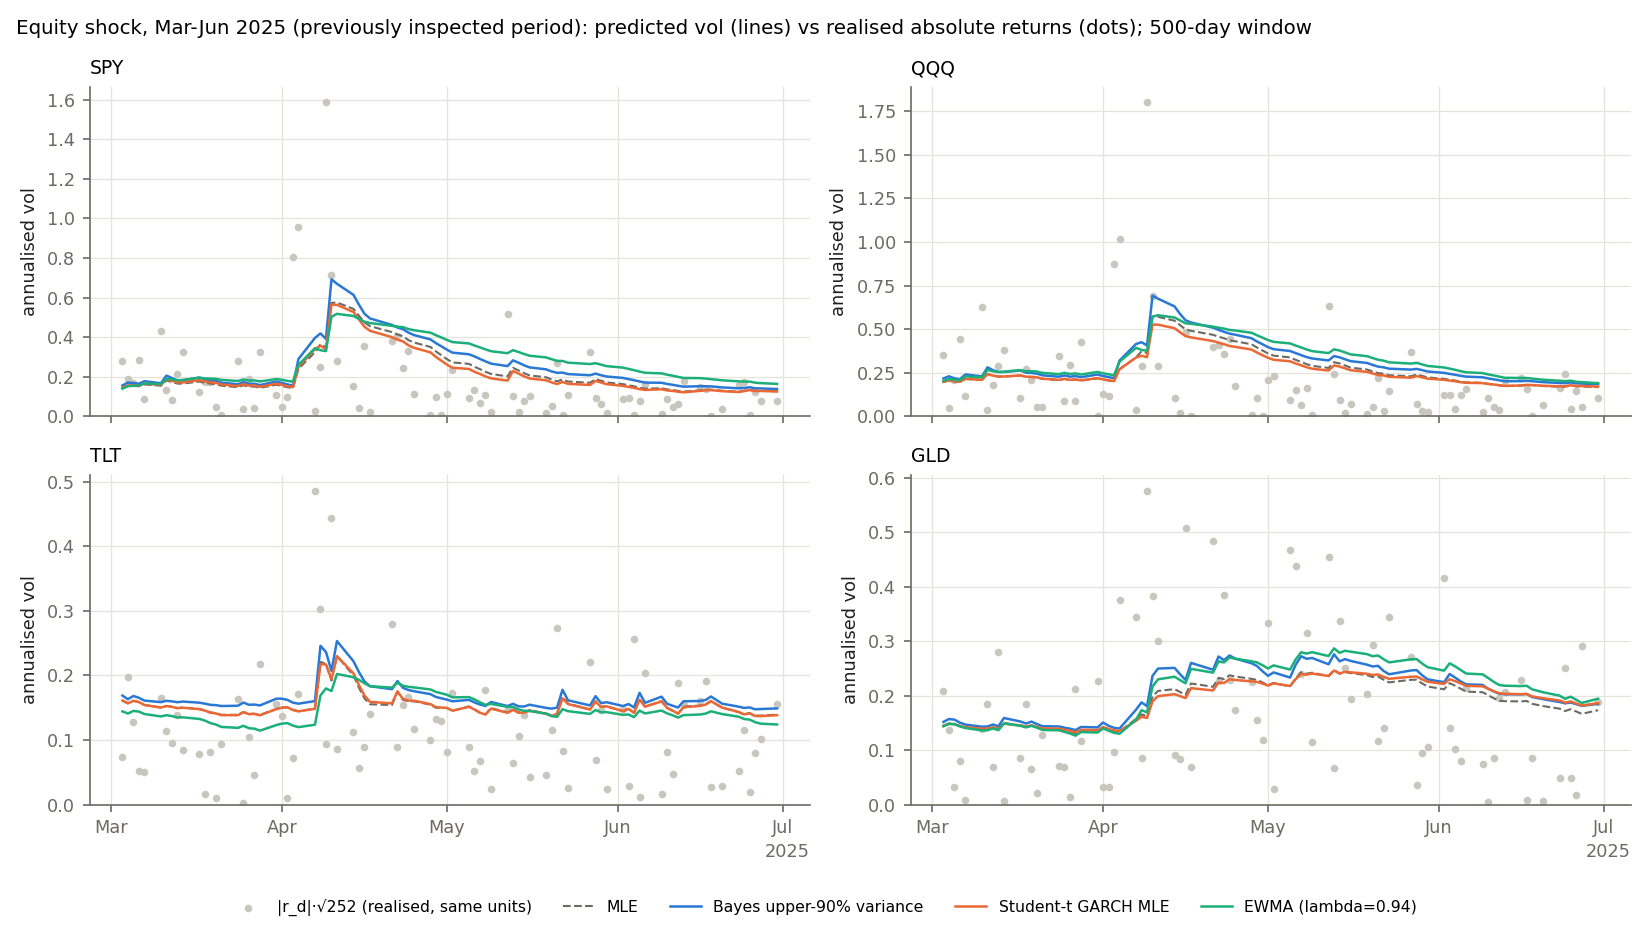

PASS  stress table == saved artifacts/results/adequacy/stress_w500.csv


jump_ratio                                        halflife_after_peak                                        mean_z2                                   \
model                    mle bayes_integrated bayes_q90     t  ewma                 mle bayes_integrated bayes_q90     t  ewma     mle bayes_integrated bayes_q90     t   
period      asset                                                                                                                                                         
covid_2020  GLD         1.12             1.13      1.15  1.12  1.13                15.0             14.0      15.0  16.0  32.0    2.02             1.97      1.63  1.80   
            QQQ         1.27             1.27      1.28  1.26  1.21                10.0             10.0      10.0  11.0  33.0    1.32             1.33      1.18  1.31   
            SPY         1.20             1.20      1.20  1.19  1.17                10.0             10.0      10.0  11.0  29.0    1.47             1.47      1.31  1.44   
            TLT         1.11             1.13      1.14  1.11  1.11                 9.0             10.0      10.0   9.0  20.0    2.32             1.93      1.50  2.36   
shock_2025  GLD         1.22             1.25      1.31  1.19  1.28                20.0             19.0      19.0  26.0  25.0    1.39             1.42      1.17  1.39   
            QQQ         1.57             1.62      1.70  1.55  1.52                13.0             11.0      11.0  13.0  18.0    1.47             1.46      1.18  1.54   
            SPY         1.64             1.69      1.77  1.67  1.53                10.0             10.0       9.0  10.0  19.0    1.70             1.69      1.33  1.70   
            TLT         1.49             1.41      1.53  1.47  1.37                 2.0              2.0       2.0   2.0  12.0    0.88             0.86      0.76  0.88   
stress_2022 GLD         1.31             1.30      1.39  1.18  1.25                 4.0              4.0       3.0   4.0   0.0    0.87             0.86      0.78  0.83   
            QQQ         1.16             1.19      1.23  1.18  1.12                13.0              9.0      17.0   9.0  13.0    1.12             1.19      1.07  1.12   
            SPY         1.32             1.33      1.36  1.30  1.12                 7.0              5.0       5.0   7.0  13.0    1.22             1.26      1.12  1.16   
            TLT         1.26             1.32      1.34  1.26  1.18                 8.0              7.0       7.0  16.0   6.0    1.25             1.27      1.06  1.22   

                        n_abs_z_gt3                                       
model              ewma         mle bayes_integrated bayes_q90    t ewma  
period      asset                                                         
covid_2020  GLD    1.47         5.0              5.0       2.0  4.0  2.0  
            QQQ    1.52         1.0              1.0       1.0  1.0  3.0  
            SPY    1.66         2.0              2.0       1.0  1.0  4.0  
            TLT    1.36         5.0              4.0       1.0  5.0  2.0  
shock_2025  GLD    1.21         1.0              1.0       1.0  1.0  1.0  
            QQQ    1.17         4.0              3.0       3.0  4.0  3.0  
            SPY    1.31         3.0              3.0       3.0  3.0  3.0  
            TLT    1.03         1.0              1.0       1.0  1.0  1.0  
stress_2022 GLD    0.95         0.0              0.0       0.0  0.0  1.0  
            QQQ    1.07         0.0              0.0       0.0  0.0  0.0  
            SPY    1.10         0.0              0.0       0.0  0.0  0.0  
            TLT    0.99         1.0              1.0       0.0  1.0  0.0

PASS  2020: GARCH half-lives 9-16 days; EWMA 2-3x longer (report App. A)  [GARCH 9-16, EWMA 20-33]


In [49]:
for p in A.PERIODS:
    show_regen(A.fig_stress, p)
stress = A.stress_table()
check('stress table == saved artifacts/results/adequacy/stress_w500.csv',
      np.allclose(stress.select_dtypes('number').to_numpy(float), pd.read_csv(cfg.RESULTS / 'adequacy/stress_w500.csv').select_dtypes('number').to_numpy(float), equal_nan=True))
show_m = ['mle', 'bayes_integrated', 'bayes_q90', 't', 'ewma']
display(stress[stress.model.isin(show_m)].pivot_table(index=['period', 'asset'], columns='model', values=['jump_ratio', 'halflife_after_peak', 'mean_z2', 'n_abs_z_gt3'])
        [[(v, m) for v in ['jump_ratio', 'halflife_after_peak', 'mean_z2', 'n_abs_z_gt3'] for m in show_m]].round(2))
cov_g = stress[(stress.period == 'covid_2020') & stress.model.isin(['mle', 'map', 'bayes_meanplug', 'bayes_integrated', 'bayes_q90', 'laplace_integrated', 't'])]
cov_e = stress[(stress.period == 'covid_2020') & (stress.model == 'ewma')]
check('2020: GARCH half-lives 9-16 days; EWMA 2-3x longer (report App. A)', cov_g.halflife_after_peak.between(9, 16).all() and
      (cov_e.halflife_after_peak.to_numpy() / cov_g[cov_g.model == 'mle'].halflife_after_peak.to_numpy()).min() >= 1.8,
      f'GARCH {cov_g.halflife_after_peak.min():.0f}-{cov_g.halflife_after_peak.max():.0f}, EWMA {cov_e.halflife_after_peak.min():.0f}-{cov_e.halflife_after_peak.max():.0f}')

**Interpretation — the March 2020 crash.**
- **Reaction speed.** All GARCH variants react on the *next* day. After SPY's −11.6% return on 2020-03-16, they
  raise next-day volatility by about 20% and peak one day later. EWMA started lower before the crash, because its
  $\lambda=0.94$ averages over a calmer past. It rises less and peaks about a week later, at a lower level. No model
  that conditions only on past returns can anticipate the *first* shock of a crisis.
- **Persistence.** GARCH forecasts fall halfway back in 9–16 trading days after the 2020 peak. EWMA takes 2–3 times
  longer, so it stays elevated long after realised volatility has normalised.
- **Under-prediction.**
  - In 2020, `mean_z2` is 1.2–2.4 for every GARCH model, worst for TLT and GLD, whose volatility jumped from a
    calm level.
  - In 2022, a sustained high-volatility regime, all models track well.
  - In 2025, the largest standardised error came from a *positive* shock: SPY rose 10% on 2025-04-09.
- **Bayesian variants.** Integration and the upper quantile do not change *when* the model fails. The upper-90
  forecast trims `mean_z2` slightly because it is uniformly more conservative.

### 11.6 Per-ETF performance and difficult regimes

QLIKE (lower is better)


period             2017–22                         2023–26                        
asset                  GLD     QQQ     SPY     TLT     GLD     QQQ     SPY     TLT
model                                                                             
mle                -8.5978 -7.7729 -8.3687 -8.5279 -7.9246 -7.8316 -8.5179 -8.5274
map                -8.5959 -7.7707 -8.3667 -8.5427 -7.9274 -7.8377 -8.5234 -8.5231
bayes_meanplug     -8.5907 -7.7741 -8.3713 -8.5484 -7.9321 -7.8379 -8.5250 -8.5134
bayes_integrated   -8.5951 -7.7730 -8.3702 -8.5503 -7.9280 -7.8372 -8.5234 -8.5260
bayes_q90          -8.5954 -7.7786 -8.3748 -8.5626 -7.9394 -7.8359 -8.5230 -8.4931
laplace_integrated -8.5995 -7.7717 -8.3672 -8.5405 -7.9243 -7.8316 -8.5184 -8.5313
ewma               -8.6007 -7.7328 -8.3057 -8.5718 -7.9288 -7.8164 -8.4917 -8.5378
t                  -8.5994 -7.7794 -8.3787 -8.5337 -7.9213 -7.8296 -8.5208 -8.5293
bayes_mixture      -8.5951 -7.7730 -8.3702 -8.5503 -7.9280 -7.8372 -8.5234 -8.5260

mean log score (higher is better; n/a for upper-90 variance)


period             2017–22                         2023–26                        
asset                  GLD     QQQ     SPY     TLT     GLD     QQQ     SPY     TLT
model                                                                             
mle                 3.3800  2.9675  3.2654  3.3450  3.0434  2.9968  3.3400  3.3448
map                 3.3790  2.9664  3.2644  3.3524  3.0448  2.9999  3.3428  3.3426
bayes_meanplug      3.3764  2.9681  3.2667  3.3552  3.0471  3.0000  3.3436  3.3378
bayes_integrated    3.3786  2.9676  3.2661  3.3562  3.0451  2.9997  3.3428  3.3441
bayes_q90              NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN
laplace_integrated  3.3840  2.9695  3.2677  3.3550  3.0472  3.0014  3.3464  3.3471
ewma                3.3814  2.9474  3.2339  3.3670  3.0455  2.9892  3.3269  3.3499
t                   3.4100  3.0006  3.3042  3.3559  3.0674  3.0178  3.3671  3.3481
bayes_mixture       3.3813  2.9699  3.2687  3.3587  3.0486  3.0039  3.3488  3.3445

1% VaR violation rate (nominal 0.01)


period             2017–22                         2023–26                        
asset                  GLD     QQQ     SPY     TLT     GLD     QQQ     SPY     TLT
model                                                                             
mle                 0.0179  0.0245  0.0252  0.0172  0.0187  0.0187  0.0156  0.0124
map                 0.0185  0.0245  0.0272  0.0159  0.0187  0.0187  0.0145  0.0083
bayes_meanplug      0.0166  0.0238  0.0232  0.0146  0.0187  0.0187  0.0145  0.0073
bayes_integrated    0.0179  0.0245  0.0258  0.0139  0.0187  0.0187  0.0145  0.0093
bayes_q90           0.0146  0.0205  0.0192  0.0099  0.0145  0.0124  0.0114  0.0062
laplace_integrated  0.0179  0.0245  0.0265  0.0146  0.0197  0.0176  0.0135  0.0104
ewma                0.0199  0.0252  0.0278  0.0139  0.0176  0.0197  0.0176  0.0166
t                   0.0106  0.0179  0.0172  0.0146  0.0176  0.0156  0.0124  0.0124
bayes_mixture       0.0179  0.0245  0.0252  0.0139  0.0187  0.0187  0.0145  0.0093

Ex-ante regime = tercile of the MLE predicted volatility (known before r_d), 2017–26:


n  mean_z2_mle  lower01_mle  lower01_t  lower01_mixture  ls_t_minus_mle
asset regime                                                                              
SPY   calm       825       1.0622       0.0303     0.0230           0.0279          0.0633
      normal     824       1.0163       0.0158     0.0097           0.0158          0.0278
      turbulent  825       1.1112       0.0182     0.0133           0.0194          0.0116
QQQ   calm       825       1.0900       0.0267     0.0194           0.0267          0.0565
      normal     824       1.0927       0.0291     0.0255           0.0291          0.0279
      turbulent  825       1.0477       0.0109     0.0061           0.0109          0.0006
TLT   calm       825       1.1400       0.0206     0.0194           0.0158          0.0084
      normal     824       0.8850       0.0109     0.0085           0.0097          0.0081
      turbulent  825       1.0240       0.0145     0.0133           0.0109          0.0074
GLD   calm       825       1.1517       0.0182     0.0109           0.0182          0.0256
      normal     824       0.9794       0.0121     0.0073           0.0121          0.0027
      turbulent  825       1.1947       0.0242     0.0218           0.0242          0.0549

By calendar year (2017–26, 500-day window): mean z^2 and 1% lower-tail exceedance of the Gaussian MLE forecast


mean z^2                      1% exceedance                     
asset       GLD    QQQ    SPY    TLT           GLD    QQQ    SPY    TLT
regime                                                                 
2017      0.751  0.783  0.569  0.610         0.000  0.016  0.012  0.000
2018      0.958  1.553  1.504  0.785         0.016  0.044  0.036  0.004
2019      1.276  0.887  0.967  1.462         0.020  0.016  0.028  0.032
2020      1.486  1.235  1.277  1.455         0.036  0.036  0.032  0.028
2021      0.967  0.921  0.946  1.032         0.028  0.020  0.024  0.016
2022      1.018  1.167  1.246  1.289         0.008  0.016  0.020  0.024
2023      0.925  0.947  0.896  1.013         0.008  0.008  0.000  0.020
2024      1.053  1.074  1.097  0.781         0.016  0.020  0.024  0.004
2025      1.269  1.105  1.169  0.690         0.012  0.028  0.024  0.004
2026      1.432  1.101  0.941  1.045         0.042  0.019  0.014  0.024

PASS  regenerated adequacy_exceedance_summary.png is pixel-identical to the report figure


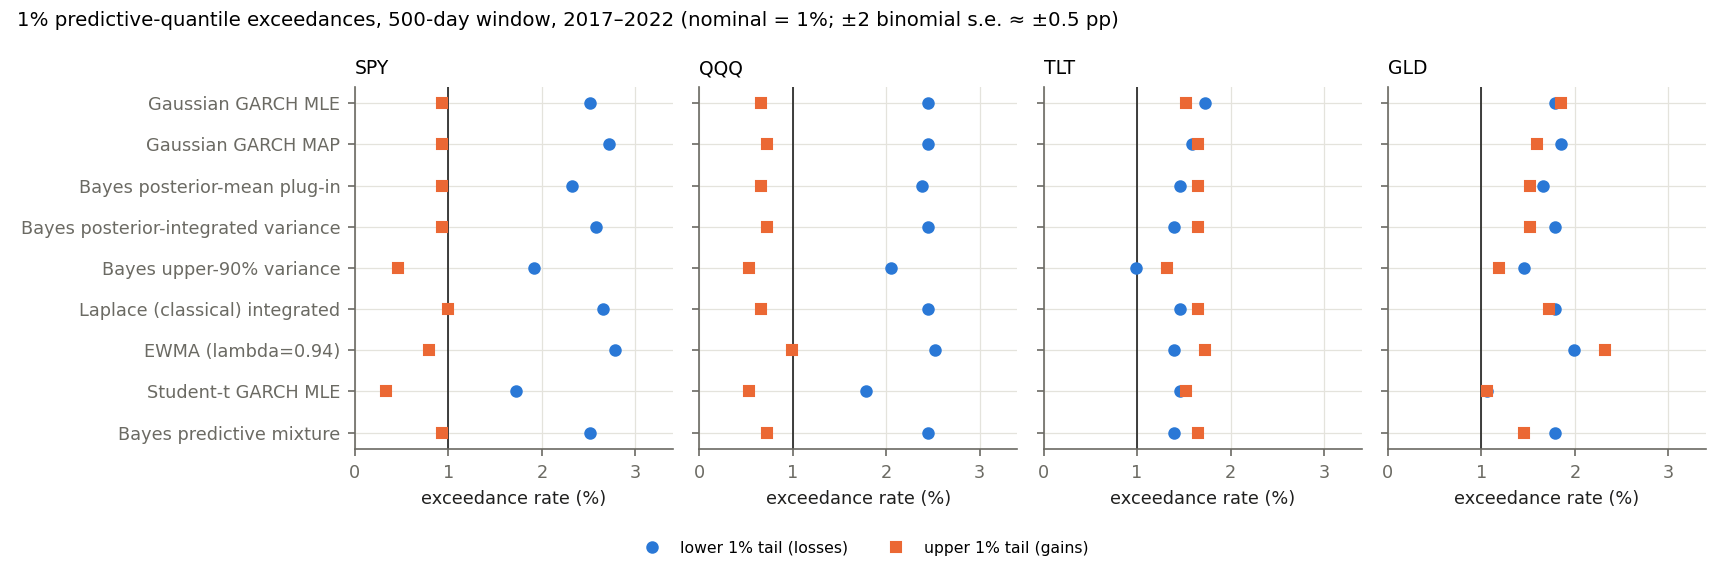

In [50]:
perf = pd.concat([A.performance_table(500, s).assign(period=SEGL[s]) for s in A.SEGS])
order = list(A.GAUSS) + ['t', 'bayes_mixture']
for metric, lab in [('qlike', 'QLIKE (lower is better)'), ('log_score', 'mean log score (higher is better; n/a for upper-90 variance)'),
                    ('var01_violation', '1% VaR violation rate (nominal 0.01)')]:
    print(lab); display(perf.pivot_table(index='model', columns=['period', 'asset'], values=metric, dropna=False).loc[order].round(4))
reg = A.regime_table()
print('Ex-ante regime = tercile of the MLE predicted volatility (known before r_d), 2017–26:')
display(reg[reg.split == 'predicted_vol_tercile'].set_index(['asset', 'regime'])[['n', 'mean_z2_mle', 'lower01_mle', 'lower01_t', 'lower01_mixture', 'ls_t_minus_mle']].round(4))
yr = reg[reg.split == 'year']
print('By calendar year (2017–26, 500-day window): mean z^2 and 1% lower-tail exceedance of the Gaussian MLE forecast')
display(pd.concat({'mean z^2': yr.pivot(index='regime', columns='asset', values='mean_z2_mle'),
                   '1% exceedance': yr.pivot(index='regime', columns='asset', values='lower01_mle')}, axis=1).round(3))
show_regen(A.fig_exceedance_summary, width=980)

**Which ETFs and regimes are hardest?**
- **SPY and QQQ** have the worst lower-tail calibration and the most negative skew, and they gain most from
  Student-$t$.
- **GLD** has fat tails on *both* sides; Student-$t$ fixes it almost completely.
- **TLT** has the thinnest tails but the most remaining clustering. In 2023–26 its variance is over-predicted,
  because the 2022 regime persisted in the estimates after bond volatility fell.
- **Regimes.** Counter-intuitively, 1% breaches for SPY and QQQ are *rarest* when **predicted** volatility is
  **high**. Shocks arriving out of calm markets (February 2018, late February 2020)
  are exactly where a model that extrapolates recent calm is most wrong. For SPY the calm tercile has 3.0% breaches
  against 1.6–1.8% elsewhere; for QQQ the calm and normal terciles have 2.7–2.9%, against 1.1% when predicted
  volatility is high.
- **Years.** By calendar year, 2018 and 2020 are the worst for equities, with the highest $\overline{z^2}$ and the
  most breaches. For TLT and GLD the worst years are 2019–20, and for GLD also the partial year 2026.

### 11.7 Parameter uncertainty versus the observed tails (report Figure 5)

Combining §6.2 and §11.3: the posterior predictive mixture can add only $3\,\mathrm{CV}^2$ of excess kurtosis. We
recompute, for every configuration, the mean posterior CV of the next-day variance (from the saved posterior sd and
mean) and the implied excess kurtosis. We compare these with the observed excess kurtosis of the standardised
returns. 🔵 *saved forecasts*

In [51]:
info = {s: tables.info_tables(s) for s in SEGS}
for s in SEGS:
    refi = pd.read_csv(cfg.SAVED_PRIMARY / f'info_{s}.csv'); num = refi.select_dtypes('number').columns
    check(f'information table {SEGL[s]} == research table', np.allclose(info[s][num].to_numpy(float), refi[num].to_numpy(float), rtol=0, atol=1e-12))
I = pd.concat([info[s].assign(period=SEGL[s]) for s in SEGS])
display(I.pivot_table(index=['asset', 'window'], columns='period', values=['mean_param_cv_variance', 'implied_mixture_excess_kurtosis', 'empirical_excess_kurtosis_std_returns']).round(3))
I5 = I[I.window == 500]
check('500-day window: posterior CV of next-day variance 7-12% (report §5.1)', I5.mean_param_cv_variance.between(.065, .125).all(),
      f'{I5.mean_param_cv_variance.min():.3f}-{I5.mean_param_cv_variance.max():.3f}')
check('implied excess kurtosis about 0.015-0.046 vs observed 0.4-2.9 (report §5.1)',
      I5.implied_mixture_excess_kurtosis.between(.0145, .0465).all() and I5.empirical_excess_kurtosis_std_returns.between(.35, 2.95).all())

PASS  information table 2017–22 == research table
PASS  information table 2023–26 == research table


empirical_excess_kurtosis_std_returns         implied_mixture_excess_kurtosis         mean_param_cv_variance        
period                                     2017–22 2023–26                         2017–22 2023–26                2017–22 2023–26
asset window                                                                                                                     
GLD   500                                    1.983   2.093                           0.035   0.041                  0.101   0.108
      1000                                   2.316   2.110                           0.022   0.030                  0.080   0.088
QQQ   500                                    1.933   2.072                           0.031   0.037                  0.096   0.099
      1000                                   1.802   1.886                           0.016   0.018                  0.069   0.071
SPY   500                                    2.915   2.795                           0.029   0.040                  0.094   0.103
      1000                                   2.611   2.419                           0.015   0.020                  0.067   0.074
TLT   500                                    0.686   0.365                           0.037   0.046                  0.101   0.117
      1000                                   0.854   0.408                           0.027   0.025                  0.086   0.083

PASS  500-day window: posterior CV of next-day variance 7-12% (report §5.1)  [0.094-0.117]
PASS  implied excess kurtosis about 0.015-0.046 vs observed 0.4-2.9 (report §5.1)


**Does posterior uncertainty predict *when* forecasts fail?** The "uncertainty premium" $q_{0.9}/\bar h-1$ is
regressed with HAC standard errors on (i) the absolute standardised error $|z^2-1|$ and (ii) a large-shock indicator
$z^2>4$, controlling for the variance level: 2 outcomes × 16 configurations = 32 coefficients.

In [52]:
from scipy.stats import binom
corr_min = I.corr_q90_integrated.min(); n_sig = int((I.abs_err_p < .05).sum() + (I.large_shock_p < .05).sum())
ref_info = pd.concat([pd.read_csv(cfg.SAVED_PRIMARY / f'info_{s}.csv') for s in SEGS])
n_sig_ref = int((ref_info.abs_err_p < .05).sum() + (ref_info.large_shock_p < .05).sum())
display(I[['period', 'asset', 'window', 'premium_mean', 'corr_q90_integrated', 'abs_err_coef_per_sd', 'abs_err_p', 'large_shock_coef_per_sd', 'large_shock_p']].round(4).reset_index(drop=True))
check('premium vs variance level: corr > 0.99 in all 16 configurations (report App. B)', corr_min > .99, f'min corr {corr_min:.4f}', FC)
check('significant premium coefficients recomputed == saved research tables (4 of 32; report corrected, see note)', n_sig == n_sig_ref == 4, f'{n_sig} of 32', FC)
print(f'P(at least {n_sig} of 32 independent 5%-tests reject under the null) = {binom.sf(n_sig - 1, 32, .05):.3f}')

,period,asset,window,premium_mean,corr_q90_integrated,abs_err_coef_per_sd,abs_err_p,large_shock_coef_per_sd,large_shock_p
0,2017–22,SPY,500,0.1204,0.9997,0.0569,0.2736,0.0127,0.0520
1,2017–22,SPY,1000,0.0874,0.9998,0.0304,0.5124,0.0048,0.4323
2,2017–22,QQQ,500,0.1234,0.9993,0.0520,0.2978,0.0149,0.0482
3,2017–22,QQQ,1000,0.0899,0.9995,0.0685,0.2000,0.0087,0.2115
4,2017–22,TLT,500,0.1313,0.9949,0.2435,0.0095,0.0332,0.0035
5,2017–22,TLT,1000,0.1111,0.9921,0.2215,0.1071,0.0283,0.0873
6,2017–22,GLD,500,0.1325,0.9949,0.0511,0.3396,0.0142,0.0981
7,2017–22,GLD,1000,0.1046,0.9976,-0.0599,0.1351,-0.0077,0.2303
8,2023–26,SPY,500,0.1357,0.9964,0.1838,0.0347,0.0153,0.0629
9,2023–26,SPY,1000,0.0979,0.9975,0.0769,0.1515,0.0135,0.0685


PASS  premium vs variance level: corr > 0.99 in all 16 configurations (report App. B)  [min corr 0.9921]
PASS  significant premium coefficients recomputed == saved research tables (4 of 32; report corrected, see note)  [4 of 32]
P(at least 4 of 32 independent 5%-tests reject under the null) = 0.074


**Interpretation: why misspecification matters for the Bayesian question.**
- Parameter uncertainty can explain only a few per cent of the observed conditional fat tails. This is why the
  Student-$t$ model dominates the log-score comparison and why tail-risk forecasts barely change with integration.
- The uncertainty premium $q_{0.9}/\bar h$ is essentially a deterministic function of the variance level
  (correlation above 0.99). Only **4 of the 32** coefficients are significant at 5%, three of them in 2017–22
  (two for TLT, $W=500$), with mixed signs. This is close to what chance produces ($32\times0.05=1.6$ expected;
  $P(\ge4)\approx0.07$ for independent tests, and these are correlated). Posterior uncertainty carries **no
  reliable timing information** about forecast failures, which anticipates the portfolio result of §13.

> **Corrected discrepancy.** The original report (§6) and the research summary stated "3 of 32". The recomputed
> tables, which are identical to the saved research tables, give **4 of 32**. The conclusion (chance-level, no timing
> information) is unaffected. The course report was corrected on 2026-11-06, and `agent_research/final_report.md`
> carries an erratum; see `docs/notebook_coverage.md`.
- The dominant errors are innovation shape, asymmetry and jumps. A Bayesian treatment of a misspecified Gaussian
  model integrates over the wrong family. Its modest gains should be read as "correctly widening a model that is
  too confident", not as evidence that the remaining error is parameter uncertainty.

**Q H1.** Why can the lag-1 autocorrelation of $z^2$ be near zero even though $z$ is strongly non-Gaussian? Which
assumption is each diagnostic actually testing?

**Q H2.** For a symmetric predictive distribution, why does negative skewness in $z$ produce *too many* lower-tail
and *too few* upper-tail exceedances at the same time?

**Q H3.** Explain why the 21-day realised volatility should not be used as the target in a QLIKE comparison of
one-step forecasts.

<a id="s12"></a>
## 12. H3 — Portfolio construction and simulation

**Question.** Do improvements in volatility forecasting and uncertainty quantification translate into better investment decisions? Volatility targeting turns a variance forecast directly into a risk position, so it is the natural test. The strategies differ only in the variance they use: MLE $\hat h$, posterior-integrated $\bar h$, posterior 90th percentile $q_{0.9}$ (a deliberately cautious, uncertainty-aware estimate; the 90th percentile is an experimental choice, not an optimum), and the exposure-matched MLE control of §13.4.

> **Experiment card — Portfolio construction and evaluation (H3, §12–§13).** Each experimental section follows this format: motivation, formulation,
> numerical method, implementation, results, interpretation, limitations.
>
> | Step | This section |
> |---|---|
> | **Motivation** | Test H3: does posterior uncertainty improve volatility-targeted allocations once exposure is controlled? |
> | **Mathematical formulation** | Weights $w_t=\min(1,0.10/\sqrt{252h_t})$; wealth recursion with weight drift, 5 bp costs and DFF cash; Sharpe ratio, maximum drawdown, mean exposure; exposure-matched control $w^{\text{ctrl}}_t=\min(1,k_t\,0.10/\sqrt{252h^{\text{MLE}}_t})$ (§12, §13.1–13.4). |
> | **Numerical method** | Daily simulation from saved forecasts, adjusted prices and DFF; paired circular block bootstrap with 20-day blocks and 2,000 replications (§13.7). |
> | **Implementation** | `portfolio.vol_weight`, `portfolio.portfolio` (checked against an explicit ledger), `strategies.strategy_weights`, `evaluation.paired_bootstrap`. |
> | **Results** | Report Tables 6–10 and Figures 6–9, bootstrap intervals and cost sensitivity (§13.6–13.8). |
> | **Interpretation** | Upper-90 has smaller drawdowns only because it holds less risk; against the exposure-matched control there is no reliable gain. |
> | **Limitations** | Sharpe differences below about 0.05 cannot be resolved; MCMC noise is about 0.01 Sharpe; close-to-close execution; a single 10% target. |

### 12.1 The rule

A volatility-targeting investor holds a fraction $w_t$ of wealth in one risky ETF and $1-w_t$ in cash. The fraction
is chosen so that the *forecast* portfolio volatility equals a target. The daily portfolio excess return is about
$w_t\,r_{t+1}$, so its conditional sd is $w_t\sqrt{h_t}$ and its annualised volatility is $w_t\sqrt{252h_t}$.
Setting this to a 10% target and forbidding leverage gives
$$w_t=\min\Big(1,\ \frac{0.10}{\sqrt{252\,h_t}}\Big)\in[0,1].$$

| Element | Choice and reason |
|---|---|
| target | 10% a year, below the 15–25% volatility of equities, so the rule is active most of the time |
| no leverage, no shorting | $w_t\le1$: when forecast volatility is below 10%, the investor is fully invested and cannot borrow |
| risky versus cash | the remainder earns the cash rate; cutting risk means holding cash |
| role of the forecast | the forecast enters only through $\sqrt{h_t}$. A forecast 10% too high cuts the weight by about 9%. Only the *variance* matters, not the density shape: Student-$t$ and Gaussian forecasts with equal $h_t$ give equal weights |
| why it can help | volatility is persistent but expected returns do not rise proportionally with it, so cutting exposure after volatility spikes has historically improved risk-adjusted returns (Moreira & Muir, 2017) |

**Reactive, not protective.** The weight responds only after volatility has risen, because $h_t$ uses $r_{<t}$.
The first day of a crash is suffered at the pre-crash weight. Volatility targeting reduces exposure to the
*persistence* of turbulence; it is no guarantee against a sudden fall (§11.5).

**The rules compared.** Each rule plugs a different variance into the same formula.
- `mle`: $h_t(\hat\theta)$.
- `bayes_integrated`: $\bar h_t$.
- `bayes_upper90`: $q_{0.9}\{h_t(\theta^{(m)})\}$, conservative by construction.
- `laplace_upper90`: the Laplace analogue of the upper-90 rule.
- `ewma` and `t_garch`: the alternative models' variances.
- `static_target`: one constant weight, set from the sample sd of all returns *before* the period starts.
- `buy_hold`: $w=1$.
- The **exposure-matched controls** of §13.4.

### 12.2 Accounting

**Timing (one close of execution delay).** The forecast row for day $d$ is computed after close $d-1$. The trade is
executed at **close $d$** and earns the close $d\to d+1$ return. Trading at the close that generated the signal is
avoided.

**Ledger** (`portfolio.simulate_portfolio`, the validated `src.portfolio` code unchanged). Wealth starts at 1,
entirely in cash. For each holding period $t$ (close $d\to d+1$):
1. **Drift.** The pre-trade weight is last period's weight after it moved with returns:
   $\tilde w_t=w_{t-1}\dfrac{1+R^{a}_{t-1}}{1+R^{p}_{t-1}}$, with $\tilde w_1=0$.
2. **Rebalance and cost.** Turnover is $\tau_t=\lvert w_t-\tilde w_t\rvert$. The cost fraction
   $c_t=\tau_t\times5\,\text{bp}$ (5 basis points = 0.05%) is charged on wealth before the period.
3. **Return.** $R^{p}_t=w_tR^{a}_t+(1-w_t)R^{\text{cash}}_t$ in simple returns, and the net return is
   $(1-c_t)(1+R^p_t)-1$.
4. **NAV.** $\text{NAV}_t=\text{NAV}_{t-1}\,(1+\text{net}_t)$.

**Cash.** The period from session $d$ to $d+1$ earns DFF from the **last observation strictly before date $d$**,
accrued $\text{rate}\times\text{calendar days}/360$ (the money-market ACT/360 convention, so weekends accrue).

🟢 *raw data* (prices, DFF) + 🔵 *saved forecasts* — the ledger written out by hand for SPY, 500-day window,
2017–22, MLE rule, compared with the validated simulator and the research table.

### 12.3 Portfolio simulation flowchart

The rule above gives the *target* weight. The flowchart shows how that target is implemented, how the portfolio
evolves and how the simulation repeats over trading days. It is drawn from the code: `portfolio.portfolio` →
`simulate_portfolio` (imported unchanged from the original project) → `cash_returns_for_periods`.

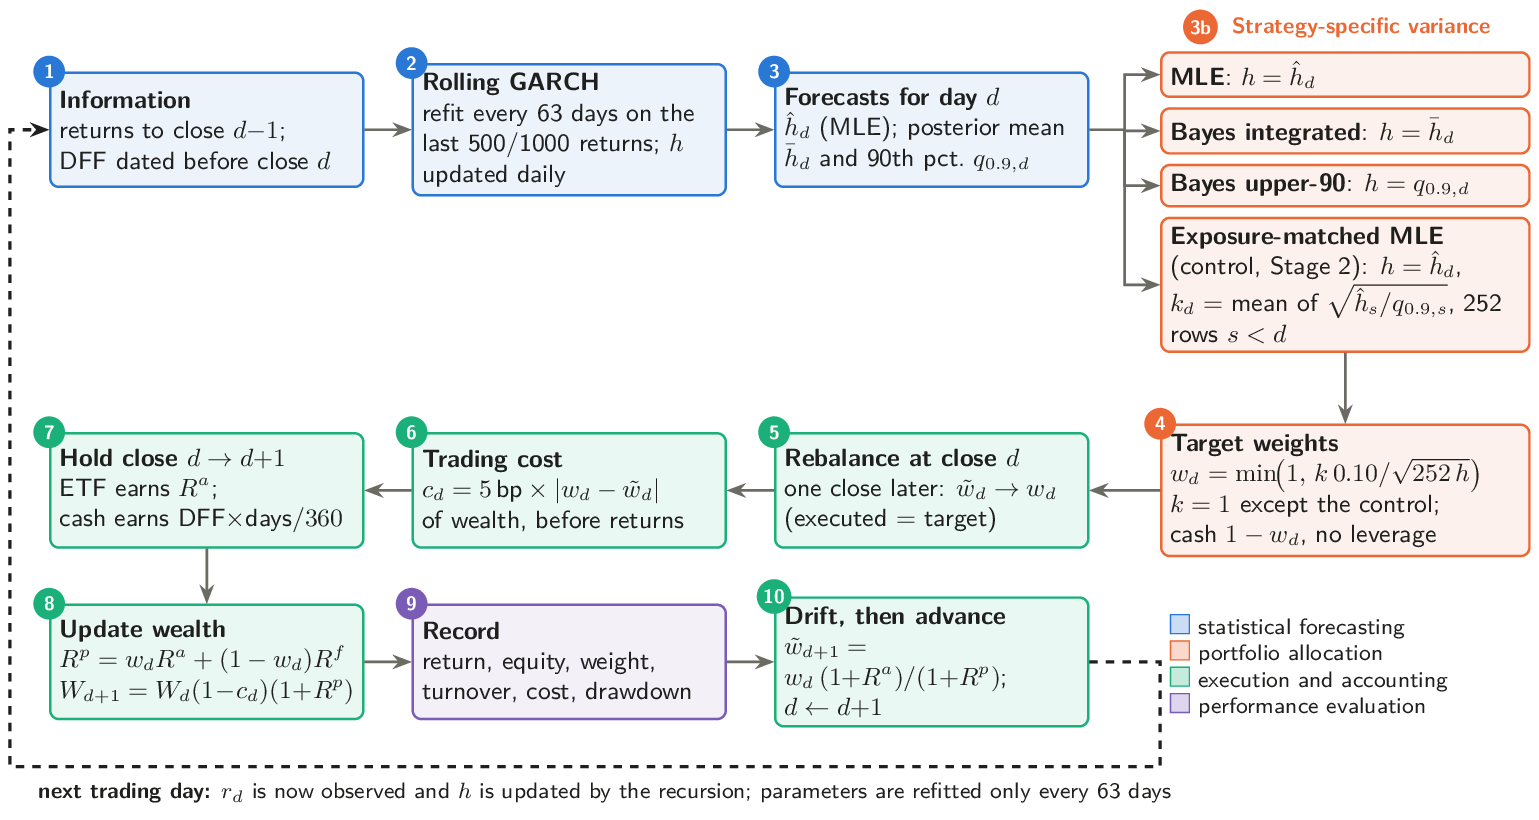

| Step | Implementation detail (verified below) |
|---|---|
| 1–3 forecasting | forecast row $d$ uses returns to close $d-1$; parameters change only at the 63-day refits |
| 3b–4 allocation | $w_d=\min(1,k\,0.10/\sqrt{252h})$, with $h=\hat h_d$, $\bar h_d$ or $q_{0.9,d}$; $k=k_d$ only for the control |
| 5 rebalance | executed at **close $d$**, one close after the information; executed weight $=$ target (full daily rebalance) |
| 6 costs | $c_d=0.0005\,\lvert w_d-\tilde w_d\rvert$ of wealth, charged before returns; separate from market returns |
| 7 holding period | ETF earns $R^a_{d+1}=e^{r_{d+1}}-1$; cash earns the DFF rate dated before close $d$, × calendar days / 360 |
| 8 wealth | $W_{d+1}=W_d(1-c_d)\big(1+w_dR^a_{d+1}+(1-w_d)R^f_{d+1}\big)$, starting from $W_0=1$ in cash |
| 9 record | return, NAV, weight, turnover, cost, drawdown |
| 10 drift | post-return weight $\tilde w_{d+1}=w_d(1+R^a_{d+1})/(1+R^p_{d+1})$ is the next pre-trade weight |

**Target, executed and post-return weights.** The *target* comes from the rule; the *executed* weight equals it, because
costs reduce wealth, not the weight; the *post-return* weight is the target after a day of drift. Turnover measures only
the deliberate trade from the drifted weight back to the new target. The next cell writes this ledger out by hand and
checks it against the simulator; the cell after it shows a worked calculation for individual days.

In [53]:
rates = data.load_rates()
d2 = pd.DatetimeIndex(['2023-03-17', '2023-03-20'])
used = rates[rates.index < d2[0]].iloc[-1]
check('cash: DFF strictly before the decision date, ACT/360 (Fri -> Mon = 3 days)', np.isclose(pf.cash_returns_for_periods(d2, rates)[0], used / 100 * 3 / 360),
      f'rate {used:.2f}% -> accrual {used/100*3/360:.6f}', RAW)

f = STORE.daily('SPY', 500, 'ext')                                   # 2017-01-03 .. 2022-12-30
w_mle = pf.vol_weight(f.variance_mle.to_numpy())                     # weight from forecast row d
asset_R = np.expm1(f.return_log.to_numpy()[1:])                      # ... earns the return of row d+1
cash_R = pf.cash_returns_for_periods(f.date, rates)
wt = w_mle[:-1]
wealth, prev, ledger = 1.0, 0.0, []
for t in range(len(asset_R)):                                        # explicit ledger
    turn = abs(wt[t] - prev); cost = turn * 5 / 1e4
    gross = wt[t] * asset_R[t] + (1 - wt[t]) * cash_R[t]
    net = (1 - cost) * (1 + gross) - 1; wealth *= 1 + net
    ledger.append(dict(period_end=f.date.iloc[t + 1].date(), pre_trade_weight=prev, weight=wt[t], turnover=turn, cost=cost,
                       etf_return=asset_R[t], cash_return=cash_R[t], net_return=net, NAV=wealth))
    prev = wt[t] * (1 + asset_R[t]) / (1 + gross)                    # drifted weight carried to the next period
ledger = pd.DataFrame(ledger)
s_sim, c_sim = pf.portfolio(f, w_mle)
saved_alloc = pd.read_csv(cfg.SAVED_PRIMARY / 'alloc_summary_ext.csv').query("asset=='SPY' and window==500").set_index('strategy')
check('explicit ledger == validated simulator (every day)', np.allclose(ledger.net_return, c_sim.portfolio_return, atol=1e-15, rtol=0))
check('Sharpe == research table (SPY, 500, 2017-22, MLE)', np.isclose(s_sim['sharpe_excess_cash'], saved_alloc.loc['mle', 'sharpe_excess_cash'], atol=1e-12))
display(ledger.iloc[[0, 1, 2, 800, 801]].round(6))
print(f'final NAV {wealth:.4f}; mean exposure {wt.mean():.3f}; mean daily turnover {ledger.turnover.mean():.4f}; '
      f'cumulative cost {ledger.cost.sum():.2%} of wealth over 6 years')

PASS  cash: DFF strictly before the decision date, ACT/360 (Fri -> Mon = 3 days)  [rate 4.58% -> accrual 0.000382]
PASS  explicit ledger == validated simulator (every day)
PASS  Sharpe == research table (SPY, 500, 2017-22, MLE)


,period_end,pre_trade_weight,weight,turnover,cost,etf_return,cash_return,net_return,NAV
0,2017-01-04,0.00000,1.00000,1.00000,5.00000e-04,0.00595,0.00002,0.00545,1.00545
1,2017-01-05,1.00000,0.91790,0.08210,4.10000e-05,-0.00080,0.00002,-0.00077,1.00467
2,2017-01-06,0.91784,0.90670,0.01114,6.00000e-06,0.00358,0.00002,0.00324,1.00793
800,2020-03-11,0.24437,0.14616,0.09820,4.90000e-05,-0.04875,0.00003,-0.00715,1.27762
801,2020-03-12,0.14003,0.14478,0.00475,2.00000e-06,-0.09568,0.00003,-0.01383,1.25995


final NAV 1.5874; mean exposure 0.736; mean daily turnover 0.0469; cumulative cost 3.54% of wealth over 6 years


**Worked calculation.** Five consecutive days of the ledger above (SPY, 500-day window, MLE forecasts) around the
March 2020 crash. Each column follows one trading day through steps 1–10 of the flowchart: the information date, the
forecast and target weight, the cash weight, the drifted pre-trade weight, the trade and its cost, the market returns,
the updated NAV and the post-return weight that becomes the next day's pre-trade weight. 🔵 *saved forecasts* + 🟢 *raw data*

In [54]:
wk = ledger.copy()
wk.insert(0, 'trade_at_close', f.date.iloc[:len(wk)].dt.date.to_numpy())                 # row d is traded at close d ...
wk.insert(0, 'information_to_close', [None] + list(f.date.iloc[:len(wk) - 1].dt.date))  # ... using returns to close d-1
wk['forecast_ann_vol'] = np.sqrt(252 * f.variance_mle.to_numpy()[:len(wk)])
wk['cash_weight'] = 1 - wk.weight
wk['gross_return'] = wk.weight * wk.etf_return + wk.cash_weight * wk.cash_return
wk['post_return_weight'] = wk.weight * (1 + wk.etf_return) / (1 + wk.gross_return)
check('post-return weight of day d == pre-trade weight of day d+1 (drift)', np.allclose(wk.post_return_weight.to_numpy()[:-1], wk.pre_trade_weight.to_numpy()[1:]), level=FC)
check('NAV_d+1 == NAV_d (1 - cost_d)(1 + gross_d)', np.allclose(wk.NAV.to_numpy()[1:], wk.NAV.to_numpy()[:-1] * (1 - wk.cost.to_numpy()[1:]) * (1 + wk.gross_return.to_numpy()[1:])), level=FC)
i0 = int(np.flatnonzero(wk.trade_at_close.astype(str) == '2020-03-06')[0])
cols = ['information_to_close', 'trade_at_close', 'period_end', 'forecast_ann_vol', 'weight', 'cash_weight', 'pre_trade_weight', 'turnover', 'cost',
        'etf_return', 'cash_return', 'gross_return', 'net_return', 'NAV', 'post_return_weight']
display(wk.iloc[i0:i0 + 5][cols].set_index('trade_at_close').T)

PASS  post-return weight of day d == pre-trade weight of day d+1 (drift)
PASS  NAV_d+1 == NAV_d (1 - cost_d)(1 + gross_d)


trade_at_close,2020-03-06,2020-03-09,2020-03-10,2020-03-11,2020-03-12
information_to_close,2020-03-05,2020-03-06,2020-03-09,2020-03-10,2020-03-11
period_end,2020-03-09,2020-03-10,2020-03-11,2020-03-12,2020-03-13
forecast_ann_vol,0.47198,0.42521,0.68417,0.69069,0.69377
weight,0.21187,0.23518,0.14616,0.14478,0.14414
cash_weight,0.78813,0.76482,0.85384,0.85522,0.85586
pre_trade_weight,0.21008,0.1986,0.24437,0.14003,0.13277
turnover,0.00179,0.03658,0.0982,0.00475,0.01137
cost,0.0,0.00002,0.00005,0.0,0.00001
etf_return,-0.07809,0.05175,-0.04875,-0.09568,0.08549
cash_return,0.00009,0.00003,0.00003,0.00003,0.00003


**Execution-lag canary.** If a signal on forecast row $d$ is changed, the first portfolio period affected must be
the one that *ends* at close $d+1$. 🟢

PASS  canary: weight from row d first affects the period ending at close d+1  [row 400 (2018-08-06) -> period ending 2018-08-07]
static_target weight for SPY 2017-22 (sd of all returns before 2017): 0.783


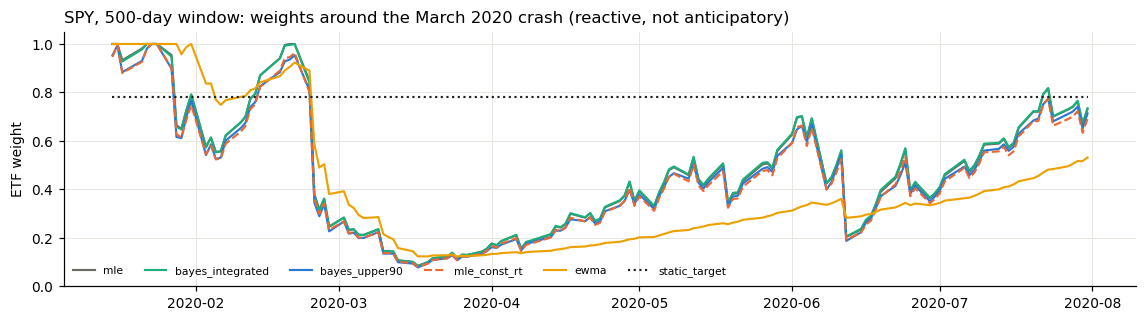

In [55]:
w_pert = w_mle.copy(); d_ = 400; w_pert[d_] = 0.0
_, c_p = pf.portfolio(f, w_pert); first = int(np.flatnonzero(~np.isclose(c_p.portfolio_return, c_sim.portfolio_return, rtol=0, atol=0))[0])
check('canary: weight from row d first affects the period ending at close d+1', first == d_ and c_p.date.iloc[first] == f.date.iloc[d_ + 1],
      f'row {d_} ({f.date.iloc[d_].date()}) -> period ending {c_p.date.iloc[first].date()}', RAW)
Wts = strategies.strategy_weights(f, 'SPY', 'ext')
print(f"static_target weight for SPY 2017-22 (sd of all returns before 2017): {Wts['static_target'][0]:.3f}")
m_ = (f.date >= '2020-01-15') & (f.date <= '2020-07-31')
fig, ax = plt.subplots(figsize=(10.5, 3))
for k, c, ls in [('mle', MUTED, '-'), ('bayes_integrated', C[2], '-'), ('bayes_upper90', C[0], '-'), ('mle_const_rt', C[1], '--'), ('ewma', C[3], '-'), ('static_target', INK, ':')]:
    ax.plot(f.date[m_], Wts[k][m_], color=c, ls=ls, lw=1.4, label=k)
ax.set_ylabel('ETF weight'); ax.set_ylim(0, 1.05); ax.legend(ncol=6, fontsize=7, loc='lower left')
ax.set_title('SPY, 500-day window: weights around the March 2020 crash (reactive, not anticipatory)', loc='left'); plt.tight_layout(); plt.show()

**Interpretation.**
- In January 2020 SPY's forecast volatility was close to 10%, so every GARCH rule was nearly fully invested.
- A brief cut to about 55% followed a late-January sell-off; by mid-February the rules were fully invested again.
- After the first crash days (late February), all GARCH rules cut exposure within days, to about 30%, and to
  about 10% by mid-March.
- EWMA reacted to the same shocks more smoothly. It then recovered far more slowly, staying near 20–50% through
  July while the GARCH rules returned to 60–80%. The upper-90 rule sits slightly below MLE almost everywhere, a near-constant
haircut. The control (orange dashed) reproduces that haircut without any posterior information.

**Limitations.**
- Close-to-close execution at the closing price.
- A flat 5 bp cost, with no market impact or bid–ask dynamics.
- DFF as the cash rate.
- Single-asset strategies combined into an equal-weight sleeve (§13) without modelling cross-asset correlation.

These choices are shared by every rule.

<a id="s13"></a>
## 13. H3 — Portfolio evaluation in two stages

### 13.1 Performance measures

For net daily returns $R^p_t$ and cash returns $R^f_t$, $t=1..n$:

| Measure | Definition |
|---|---|
| annualised return | $\text{NAV}_n^{252/n}-1$ |
| annualised volatility | $\operatorname{sd}(R^p)\sqrt{252}$ |
| **Sharpe ratio** | $\dfrac{\overline{R^p-R^f}}{\operatorname{sd}(R^p-R^f)}\sqrt{252}$: return per unit of risk, in excess of cash |
| **maximum drawdown** | $\min_t\big(\text{NAV}_t/\max_{s\le t}\text{NAV}_s-1\big)$: the worst peak-to-trough loss |
| average exposure | $\bar w=\tfrac1n\sum_tw_t$ |
| turnover / cost | mean $\lvert w_t-\tilde w_t\rvert$; cost = turnover × 5 bp |

### 13.2 Stage 1: Bayesian upper-90 versus standard MLE

The H3 results are presented in two stages. **Stage 1** compares the two rules of interest directly, without the
control. Means over the 8 single-ETF asset/window configurations, 2017–22; per-configuration and sleeve intervals from
the paired circular block bootstrap. ⚪ *saved research tables* (re-simulated from daily data and verified identical in
§13.6).

In [56]:
COLS = ['mean_exposure', 'annualized_return', 'realized_annual_volatility', 'sharpe_excess_cash', 'max_drawdown']
AS = {s: pd.read_csv(cfg.SAVED_PRIMARY / f'alloc_summary_{s}.csv') for s in SEGS}
AP = {s: pd.read_csv(cfg.SAVED_PRIMARY / f'alloc_pairs_{s}.csv') for s in SEGS}
APP = {s: pd.read_csv(cfg.SAVED_PRIMARY / f'alloc_pooled_pairs_{s}.csv').set_index(['a', 'b', 'window']) for s in SEGS}
def stage_table(b, lab_b, seg='ext'):
    g = AS[seg][AS[seg].strategy.isin([b, 'bayes_upper90'])].groupby('strategy')[COLS].mean().loc[[b, 'bayes_upper90']]
    d = g.loc['bayes_upper90'] - g.loc[b]
    x = AP[seg][(AP[seg].a == 'bayes_upper90') & (AP[seg].b == b)]
    excl = lambda lo, hi: int(((x[lo] > 0) | (x[hi] < 0)).sum())
    tab = pd.DataFrame({'ETF exposure (%)': 100 * g.mean_exposure, 'return (%)': 100 * g.annualized_return,
                        'volatility (%)': 100 * g.realized_annual_volatility, 'Sharpe': g.sharpe_excess_cash, 'max drawdown (%)': 100 * g.max_drawdown})
    tab.index = [lab_b, 'Bayesian upper-90']
    tab.loc[f'difference (upper-90 − {lab_b})'] = [100 * d.mean_exposure, 100 * d.annualized_return, 100 * d.realized_annual_volatility, d.sharpe_excess_cash, 100 * d.max_drawdown]
    ci = pd.DataFrame({w: APP[seg].loc[('bayes_upper90', b, w), ['d_sharpe', 'd_sharpe_lo', 'd_sharpe_hi', 'd_maxdd', 'd_maxdd_lo', 'd_maxdd_hi']] for w in WINDOWS}).T
    return tab, excl('d_sharpe_lo', 'd_sharpe_hi'), excl('d_maxdd_lo', 'd_maxdd_hi'), ci
tab1, n_sh1, n_dd1, ci1 = stage_table('mle', 'standard MLE')
display(tab1.round(3).style.set_caption('Stage 1, 2017–22 (report Table 6): means over the 8 single-ETF configurations'))
print(f'configurations whose 95% CI excludes 0: Sharpe {n_sh1} of 8, max drawdown {n_dd1} of 8')
display(ci1.round(4).style.set_caption('Four-ETF sleeve: upper-90 − MLE, paired block-bootstrap 95% CIs (drawdown: + = shallower)'))
check('Stage 1: upper-90 vs MLE exposure 69.6/73.1%, volatility 9.81/10.37%, Sharpe 0.520/0.518, max DD -18.74/-19.55%',
      list(tab1.iloc[:2, 0].round(1)) == [73.1, 69.6] and list(tab1.iloc[:2, 2].round(2)) == [10.37, 9.81]
      and list(tab1.iloc[:2, 3].round(3)) == [0.518, 0.520] and list(tab1.iloc[:2, 4].round(2)) == [-19.55, -18.74], level=FC)
check('Stage 1 CIs: drawdown difference excludes 0 in 8 of 8 configurations, Sharpe difference in 0 of 8', (n_dd1, n_sh1) == (8, 0), level=FC)

,ETF exposure (%),return (%),volatility (%),Sharpe,max drawdown (%)
standard MLE,73.129000,6.250000,10.369000,0.518000,-19.551000
Bayesian upper-90,69.565000,6.055000,9.814000,0.520000,-18.735000
difference (upper-90 − standard MLE),-3.564000,-0.194000,-0.555000,0.002000,0.816000


configurations whose 95% CI excludes 0: Sharpe 0 of 8, max drawdown 8 of 8


,d_sharpe,d_sharpe_lo,d_sharpe_hi,d_maxdd,d_maxdd_lo,d_maxdd_hi
500,0.011000,-0.021000,0.042100,0.007600,0.002200,0.012100
1000,0.000300,-0.025100,0.025900,0.005500,0.001100,0.010100


PASS  Stage 1: upper-90 vs MLE exposure 69.6/73.1%, volatility 9.81/10.37%, Sharpe 0.520/0.518, max DD -18.74/-19.55%
PASS  Stage 1 CIs: drawdown difference excludes 0 in 8 of 8 configurations, Sharpe difference in 0 of 8


**Observation.** Upper-90 has lower realised volatility (9.81% vs 10.37%) and a shallower maximum drawdown (0.82
points on average; smaller in 8 of 8 configurations, each interval excluding zero). But it also holds 3.6 points less
ETF and earns 0.19 points less per year, and its Sharpe ratio is nearly unchanged ($+0.002$): no configuration interval
excludes zero, and the sleeve intervals straddle zero.

**Interpretation.** Upper-90 takes less risk at almost the same risk-adjusted return. §13.3 shows why that pattern is
exactly what a *systematically* more conservative rule produces, whatever its information.

### 13.3 Why a conservative rule wins on drawdown without any information

Scaling every weight by a constant $c<1$ scales every daily excess return by about $c$. Volatility and drawdown
shrink roughly in proportion, while the Sharpe ratio is unchanged up to the cap at 1 and cost effects. A rule that
is *systematically* more conservative will therefore always show a smaller drawdown than a less conservative one.
This says nothing about the quality of its information. 🔵 *saved forecasts*

In [57]:
rows = []
for c_ in [1.0, .95, .9, .8, .6]:
    s_, _ = pf.portfolio(f, np.minimum(1, c_ * w_mle))
    rows.append(dict(scale=c_, mean_exposure=s_['mean_exposure'], ann_vol=s_['realized_annual_volatility'], sharpe=s_['sharpe_excess_cash'], max_drawdown=s_['max_drawdown']))
display(pd.DataFrame(rows).round(4))

,scale,mean_exposure,ann_vol,sharpe,max_drawdown
0,1.00,0.7363,0.1017,0.6911,-0.1424
1,0.95,0.6995,0.0966,0.6911,-0.1354
2,0.90,0.6627,0.0916,0.6910,-0.1284
3,0.80,0.5891,0.0814,0.6909,-0.1143
4,0.60,0.4418,0.0610,0.6907,-0.0854


The drawdown shrinks almost linearly with the scale; the Sharpe ratio stays within a few thousandths.

**Q F1.** Why does the cap $w\le1$ make constant scaling *not* exactly Sharpe-neutral?

> **Question raised by Stage 1.** Does Bayesian uncertainty improve allocation **timing**, or is the lower drawdown
> simply a consequence of **holding less risk**?

### 13.4 Stage 2: the exposure-matched MLE control

**Objective.** Hold upper-90's average risk with no posterior information. Two explanations compete:
- **Explanation A — lower average exposure:** it looks safer only because it holds less risk on average.
- **Explanation B — better allocation timing:** posterior uncertainty tells it *when* to reduce risk.

The control below is designed to distinguish them.


The upper-90 rule uses $q_{0.9,t}>\bar h_t\approx h^{\text{MLE}}_t$, so it is a haircut version of the MLE rule plus
whatever *day-to-day* information the posterior quantile carries. To separate the two, the **implementable control**
applies the same *average* haircut to the MLE rule, using only information available in real time:
$$k_t=\frac{1}{t-\max(0,t-252)}\sum_{s=\max(0,t-252)}^{t-1}\sqrt{\frac{h^{\text{MLE}}_s}{q_{0.9,s}}}\quad(k_0=\sqrt{h^{\text{MLE}}_0/q_{0.9,0}}),\qquad w^{\text{ctrl}}_t=\min\Big(1,\ k_t\,\frac{0.10}{\sqrt{252\,h^{\text{MLE}}_t}}\Big).$$
- $k_t$ is the trailing 252-day mean, over **past rows only**, of the ratio of the two volatility forecasts, which
  are both known at their own dates.
- The MLE variance forecast itself is unchanged; only the allocation scale (the effective volatility target $0.10\,k_t$) changes, and no posterior information enters the forecast.
- $k_t$ matches upper-90's average *haircut* (the ratio of the uncapped weights), not its realised exposure directly. Because weights are capped at 1, the exposure match is approximate (measured below), and equal average exposure does not mean equal daily exposure, volatility or tail risk.
- Universe, execution timing, costs and cash accounting are identical.

**The test.**
- If upper-90 helps only because it holds less risk, it will **tie** with the control.
- If the posterior quantile carries genuine timing information, it will **beat** the control.

A second control applies the same haircut to the posterior-mean plug-in. Two *ex-post* versions, which match exposure
or volatility over the whole period with hindsight, are reported as diagnostics only, because they are not
implementable. Code: `portfolio.exposure_matched_weights`, `portfolio.trailing_mean_known`. 🔵 *saved forecasts*

**Q F2.** An ex-post exposure-matched control chooses its scaling constant using the whole evaluation period. Why is
that not a tradable strategy, and why is the real-time control `mle_const_rt` a fairer comparator?

PASS  control weights == min(1, k_t * 0.10 / sqrt(252 h_MLE))
PASS  control uses only past rows: changing rows >= 700 leaves weights up to row 700 unchanged
PASS  SPY 500 2017-22: four rules == research table


,annualized_return,realized_annual_volatility,sharpe_excess_cash,max_drawdown,mean_exposure,mean_daily_turnover
mle,0.0802,0.1017,0.6911,-0.1424,0.7363,0.0469
bayes_integrated,0.0805,0.1018,0.6932,-0.1412,0.7363,0.0469
bayes_upper90,0.0773,0.0974,0.6898,-0.1355,0.7111,0.0481
mle_const_rt,0.0764,0.0975,0.6806,-0.1370,0.7105,0.0491


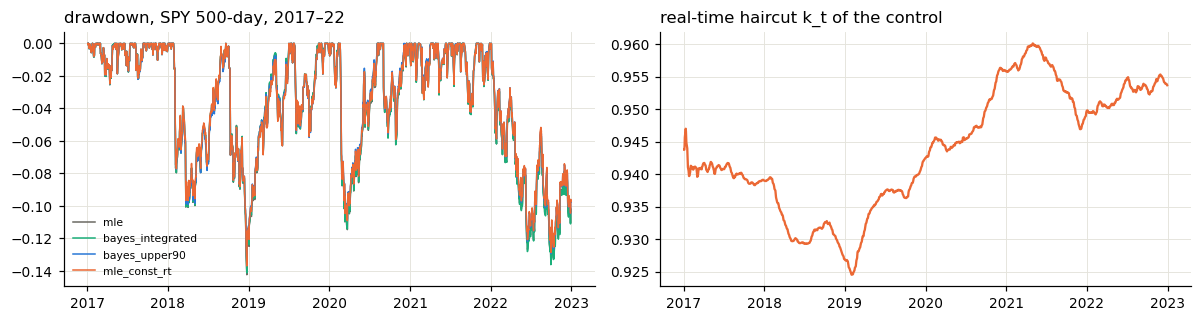

In [58]:
k_t = pf.trailing_mean_known(np.sqrt(f.variance_mle.to_numpy() / f.variance_bayes_q90.to_numpy()))
check('control weights == min(1, k_t * 0.10 / sqrt(252 h_MLE))', np.allclose(Wts['mle_const_rt'], np.minimum(1, k_t * .10 / np.sqrt(252 * f.variance_mle.to_numpy()))))
ff = f.copy(); ff.loc[ff.index >= 700, 'variance_bayes_q90'] *= 5            # change the future only
w_ff = strategies.strategy_weights(ff, 'SPY', 'ext')['mle_const_rt']
check('control uses only past rows: changing rows >= 700 leaves weights up to row 700 unchanged', np.array_equal(w_ff[:701], Wts['mle_const_rt'][:701]), level=FC)
names4 = ['mle', 'bayes_integrated', 'bayes_upper90', 'mle_const_rt']
res4 = {k: pf.portfolio(f, Wts[k]) for k in names4}
tbl4 = pd.DataFrame({k: v[0] for k, v in res4.items()}).T[['annualized_return', 'realized_annual_volatility', 'sharpe_excess_cash', 'max_drawdown', 'mean_exposure', 'mean_daily_turnover']]
check('SPY 500 2017-22: four rules == research table', np.allclose(tbl4.sharpe_excess_cash, saved_alloc.loc[names4, 'sharpe_excess_cash'], atol=1e-12))
display(tbl4.round(4))
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
for k, c in zip(names4, [MUTED, C[2], C[0], C[1]]):
    eq = res4[k][1].equity.to_numpy(); ax[0].plot(res4[k][1].date, eq / np.maximum.accumulate(eq) - 1, color=c, lw=1, label=k)
ax[0].set_title('drawdown, SPY 500-day, 2017–22', loc='left'); ax[0].legend(fontsize=7)
ax[1].plot(f.date, k_t, color=C[1]); ax[1].set_title('real-time haircut k_t of the control', loc='left'); plt.tight_layout(); plt.show()

**How well is exposure matched, and does the control explain the drawdowns?** Mean ETF weight against maximum
drawdown for every asset × window configuration, from the saved forecasts (🔵). If explanation A holds, the control
should land on top of upper-90.

PASS  exposure match: upper-90 minus control +0.1 pp (2017-22), -0.3 pp (2023-26)


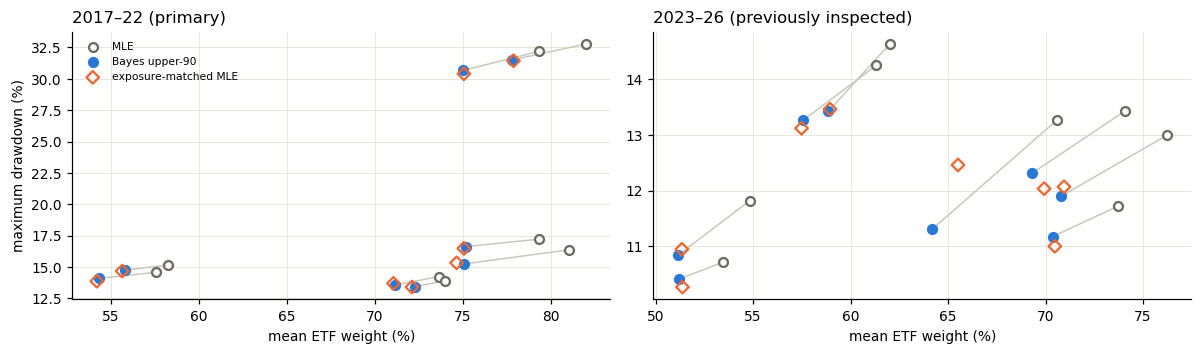

In [59]:
ex_rows = []
for s in SEGS:
    Sx = pd.read_csv(cfg.SAVED_PRIMARY / f'alloc_summary_{s}.csv').pivot_table(index=['asset', 'window'], columns='strategy', values=['mean_exposure', 'max_drawdown'])
    for (a, w), e_, d_ in zip(Sx.index, Sx['mean_exposure'].itertuples(index=False), Sx['max_drawdown'].itertuples(index=False)):
        ex_rows.append(dict(period=SEGL[s], asset=a, window=w, **{f'exp_{k}': getattr(e_, k) for k in ('mle', 'bayes_upper90', 'mle_const_rt')},
                            **{f'dd_{k}': -getattr(d_, k) for k in ('mle', 'bayes_upper90', 'mle_const_rt')}))
EX = pd.DataFrame(ex_rows)
gapx = 100 * (EX.exp_bayes_upper90 - EX.exp_mle_const_rt)
display(EX.assign(gap_vs_MLE_pp=100 * (EX.exp_bayes_upper90 - EX.exp_mle), gap_vs_control_pp=gapx).groupby('period')[['gap_vs_MLE_pp', 'gap_vs_control_pp']]
        .agg(['mean', 'min', 'max']).round(2).style.set_caption('Exposure gaps of upper-90 (percentage points), 8 configurations per period'))
check('exposure match: upper-90 minus control +0.1 pp (2017-22), -0.3 pp (2023-26)',
      round(gapx[EX.period == SEGL['ext']].mean(), 1) == 0.1 and round(gapx[EX.period == SEGL['test']].mean(), 1) == -0.3, level=FC)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
for a_, s in zip(ax, SEGS):
    sub = EX[EX.period == SEGL[s]]
    for _, r_ in sub.iterrows(): a_.plot([100 * r_.exp_mle, 100 * r_.exp_bayes_upper90], [100 * r_.dd_mle, 100 * r_.dd_bayes_upper90], color='#c9c7bd', lw=1)
    for k, lab, c, mk, fcol in [('mle', 'MLE', MUTED, 'o', 'white'), ('bayes_upper90', 'Bayes upper-90', C[0], 'o', C[0]), ('mle_const_rt', 'exposure-matched MLE', C[1], 'D', 'none')]:
        a_.scatter(100 * sub[f'exp_{k}'], 100 * sub[f'dd_{k}'], s=34, marker=mk, facecolor=fcol, edgecolor=c, lw=1.5, label=lab, zorder=3)
    a_.set_title(SEGL[s] + (' (primary)' if s == 'ext' else ' (previously inspected)'), loc='left'); a_.set_xlabel('mean ETF weight (%)')
ax[0].set_ylabel('maximum drawdown (%)'); ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()

### 13.5 Stage 2 results: upper-90 versus exposure-matched MLE

The same metrics as Stage 1, now with the control in place of MLE (2017–22, means over the 8 single-ETF configurations;
paired block-bootstrap intervals). ⚪ *saved research tables* (verified identical in §13.6).

In [60]:
tab2, n_sh2, n_dd2, ci2 = stage_table('mle_const_rt', 'exposure-matched MLE')
display(tab2.round(3).style.set_caption('Stage 2, 2017–22 (report Table 7): means over the 8 single-ETF configurations'))
print(f'configurations whose 95% CI excludes 0: Sharpe {n_sh2} of 8, max drawdown {n_dd2} of 8')
display(ci2.round(4).style.set_caption('Four-ETF sleeve: upper-90 − exposure-matched MLE, paired block-bootstrap 95% CIs'))
check('Stage 2: no Sharpe or drawdown CI excludes 0 (8 configurations); volatility 9.81 vs 9.85%, Sharpe 0.520 vs 0.516',
      (n_sh2, n_dd2) == (0, 0) and list(tab2.iloc[:2, 2].round(2)) == [9.85, 9.81] and list(tab2.iloc[:2, 3].round(3)) == [0.516, 0.520], level=FC)
txt1 = (cfg.REPORT_SOURCE / 'tables' / 'exposure_stage1.tex').read_text()
check('report stage tables carry the same numbers', '73.1\\%' in txt1 and '9.81\\%' in txt1 and '8 of 8' in txt1, level=ART)

,ETF exposure (%),return (%),volatility (%),Sharpe,max drawdown (%)
exposure-matched MLE,69.446000,6.013000,9.847000,0.516000,-18.662000
Bayesian upper-90,69.565000,6.055000,9.814000,0.520000,-18.735000
difference (upper-90 − exposure-matched MLE),0.119000,0.042000,-0.032000,0.003000,-0.074000


configurations whose 95% CI excludes 0: Sharpe 0 of 8, max drawdown 0 of 8


,d_sharpe,d_sharpe_lo,d_sharpe_hi,d_maxdd,d_maxdd_lo,d_maxdd_hi
500,0.009400,-0.016400,0.036400,-0.000100,-0.002200,0.004300
1000,0.004600,-0.015500,0.027500,-0.000300,-0.002000,0.004500


PASS  Stage 2: no Sharpe or drawdown CI excludes 0 (8 configurations); volatility 9.81 vs 9.85%, Sharpe 0.520 vs 0.516
PASS  report stage tables carry the same numbers


**Observation.** Once average exposure is approximately matched (+0.1 points), realised volatility, maximum drawdown and
the Sharpe ratio are very similar; upper-90's drawdown is smaller in only 2 of 8 configurations, and no configuration
interval excludes zero for either metric. For the sleeve, the drawdown advantage over MLE (Stage 1) has intervals
excluding zero, whereas against the control it does not, and the Sharpe-difference intervals contain zero.

**Interpretation.** The Stage 1 drawdown gain is reproduced by a strategy that holds the same average risk without any
posterior information, supporting explanation A. Sharpe point estimates are small and of either sign; they should not be
read as gains or losses. §13.6–13.8 confirm this for both periods, the four-ETF sleeve, the bootstrap and costs.

### 13.6 The full comparison: four-ETF sleeves in both periods (report Tables 8–10)

For each period and window, the **sleeve** is the equal-weight average of the four single-ETF strategy returns.
The cell recomputes every single-ETF backtest (13 strategies × 8 configurations × 2 periods) and every paired block
bootstrap (11 pairs × (8 configurations + 2 sleeves) × 2 periods, 2,000 replications each), using the same code as
quick mode, and checks every number against the research tables. 🔵 *saved forecasts* + 🟢 *raw data* (prices, DFF)

In [61]:
t0 = time.perf_counter(); alloc = {}
for s in SEGS:
    alloc[s] = tables.allocation_tables(s)
    for i, nm in enumerate(['alloc_summary', 'alloc_pairs', 'alloc_pooled_summary', 'alloc_pooled_pairs']):
        refa = pd.read_csv(cfg.SAVED_PRIMARY / f'{nm}_{s}.csv'); new = alloc[s][i]; num = refa.select_dtypes('number').columns
        check(f'{nm} {SEGL[s]} == research table', np.allclose(new[num].to_numpy(float), refa[num].to_numpy(float), atol=1e-12, rtol=0, equal_nan=True))
print(f'recomputed in {time.perf_counter()-t0:.0f} s')
T3_ROWS = [('buy_hold', 'Buy and hold'), ('static_target', 'Static weight'), ('ewma', 'EWMA'), ('t_garch', 'Student-t GARCH'), ('mle', 'Gaussian GARCH, MLE'),
           ('bayes_integrated', 'Bayes, integrated'), ('bayes_upper90', 'Bayes, upper-90'), ('mle_const_rt', 'MLE × real-time haircut (control)'), ('laplace_upper90', 'Laplace upper-90')]
T3 = pd.concat({SEGL[s]: alloc[s][2].set_index(['strategy', 'window'])[['sharpe', 'max_dd']].unstack('window') for s in SEGS}, axis=1).loc[[k for k, _ in T3_ROWS]]
T3.index = [lab for _, lab in T3_ROWS]
display(T3.round(3).style.set_caption('Report Table 9 — equal-weight four-ETF sleeve: Sharpe ratio and maximum drawdown'))
gauss_rules = ['mle', 'map', 'bayes_meanplug', 'bayes_integrated', 'bayes_upper90', 'mle_const_rt', 'meanplug_const_rt', 'laplace_upper90']
spread = lambda rules: {SEGL[s]: round(alloc[s][2][alloc[s][2].strategy.isin(rules)].groupby('window').sharpe.agg(lambda x: x.max() - x.min()).max(), 3) for s in SEGS}
check('Gaussian-GARCH rules (MLE, MAP, Bayes, Laplace, controls) within 0.02 Sharpe of one another in each period (report §7)', max(spread(gauss_rules).values()) <= .02, str(spread(gauss_rules)))
print('max Sharpe spread including Student-t GARCH:', spread(gauss_rules + ['t_garch']), '(the corrected report §7 states 0.047 in 2017–22)')

PASS  alloc_summary 2017–22 == research table
PASS  alloc_pairs 2017–22 == research table
PASS  alloc_pooled_summary 2017–22 == research table
PASS  alloc_pooled_pairs 2017–22 == research table
PASS  alloc_summary 2023–26 == research table
PASS  alloc_pairs 2023–26 == research table
PASS  alloc_pooled_summary 2023–26 == research table
PASS  alloc_pooled_pairs 2023–26 == research table
recomputed in 19 s


PASS  Gaussian-GARCH rules (MLE, MAP, Bayes, Laplace, controls) within 0.02 Sharpe of one another in each period (report §7)  [{'2017–22': 0.019, '2023–26': 0.016}]
max Sharpe spread including Student-t GARCH: {'2017–22': 0.047, '2023–26': 0.016} (the corrected report §7 states 0.047 in 2017–22)


In [62]:
PAIRS4 = [('bayes_upper90', 'mle', 'Upper-90 − MLE'), ('bayes_upper90', 'mle_const_rt', 'Upper-90 − control (MLE × haircut)'),
          ('bayes_upper90', 'laplace_upper90', 'Upper-90 − Laplace upper-90'), ('bayes_integrated', 'mle', 'Integrated − MLE')]
PP = {s: alloc[s][3].set_index(['a', 'b', 'window']) for s in SEGS}
T4 = pd.DataFrame({(SEGL[s], f'W={w}'): [f"{PP[s].loc[(a, b, w), 'd_sharpe']:+.3f} [{PP[s].loc[(a, b, w), 'd_sharpe_lo']:+.3f}, {PP[s].loc[(a, b, w), 'd_sharpe_hi']:+.3f}]"
                                          for a, b, _ in PAIRS4] for s in SEGS for w in WINDOWS}, index=[lab for _, _, lab in PAIRS4])
display(T4.style.set_caption('Report Table 10 — paired ΔSharpe, four-ETF sleeve [95% circular block-bootstrap CI]'))
sel = pd.concat([alloc[s][3] for s in SEGS]); sel = sel[(sel.a == 'bayes_upper90') & sel.b.isin(['mle', 'mle_const_rt', 'laplace_upper90'])]
check('every 95% CI for upper-90 vs MLE / control / Laplace contains zero (both periods, both windows)', ((sel.d_sharpe_lo < 0) & (sel.d_sharpe_hi > 0)).all(), f'{len(sel)} intervals')
bvc = pd.concat([alloc[s][3] for s in SEGS]); bvc = bvc[bvc.a.str.startswith('bayes') & bvc.b.isin(['mle', 'mle_const_rt', 'meanplug_const_rt', 'laplace_upper90'])]
check('all Bayesian-minus-classical sleeve Sharpe differences within ±0.02 (abstract)', bvc.d_sharpe.abs().max() <= .02, f'max |ΔSharpe| {bvc.d_sharpe.abs().max():.4f}')

PASS  every 95% CI for upper-90 vs MLE / control / Laplace contains zero (both periods, both windows)  [12 intervals]
PASS  all Bayesian-minus-classical sleeve Sharpe differences within ±0.02 (abstract)  [max |ΔSharpe| 0.0193]


In [63]:
rows5 = []
for s in SEGS:
    S = alloc[s][0].pivot_table(index=['asset', 'window'], columns='strategy', values=['mean_exposure', 'max_drawdown', 'sharpe_excess_cash'])
    de = S['mean_exposure']['bayes_upper90'] - S['mean_exposure']['mle']
    d1 = S['max_drawdown']['bayes_upper90'] - S['max_drawdown']['mle']; d2 = S['max_drawdown']['bayes_upper90'] - S['max_drawdown']['mle_const_rt']
    ds = S['sharpe_excess_cash']['bayes_upper90'] - S['sharpe_excess_cash']['mle_const_rt']
    rows5.append({'period': SEGL[s], 'Δexposure vs MLE (pp)': 100 * de.mean(), 'ΔMaxDD vs MLE (pp)': 100 * d1.mean(), 'smaller DD than MLE': f'{int((d1 > 0).sum())}/8',
                  'ΔMaxDD vs control (pp)': 100 * d2.mean(), 'smaller DD than control': f'{int((d2 > 0).sum())}/8', 'ΔSharpe vs control': ds.mean(),
                  'range Δexposure (pp)': f'{100*de.min():+.1f}..{100*de.max():+.1f}', '_de': de, '_d1': d1})
T5 = pd.DataFrame(rows5).set_index('period')
display(T5.drop(columns=['_de', '_d1']).round(4).style.set_caption('Report Table 8 — upper-90 minus comparators, mean over 8 asset–window configurations'))
check('upper-90 has a smaller max drawdown than MLE in 8/8 configurations in both periods, by 0.8-1.0 pp on average',
      all((r['_d1'] > 0).all() for r in rows5) and all(.75 <= 100 * r['_d1'].mean() <= 1.05 for r in rows5))
check('... because it holds 3.6-4.1 pp less exposure', all(-4.15 <= 100 * r['_de'].mean() <= -3.55 for r in rows5), str([round(100 * r['_de'].mean(), 2) for r in rows5]))
check('vs the control: ΔMaxDD -0.07 and +0.09 pp, ΔSharpe +0.003 and -0.001 (report §7)',
      [round(v, 2) for v in T5['ΔMaxDD vs control (pp)']] == [-.07, .09] and [round(v, 3) for v in T5['ΔSharpe vs control']] == [.003, -.001])

,Δexposure vs MLE (pp),ΔMaxDD vs MLE (pp),smaller DD than MLE,ΔMaxDD vs control (pp),smaller DD than control,ΔSharpe vs control,range Δexposure (pp)
period,,,,,,,
2017–22,-3.564200,0.815600,8/8,-0.073600,2/8,0.003400,-6.0..-1.7
2023–26,-4.097000,1.024300,8/8,0.089800,4/8,-0.001100,-6.4..-2.3


PASS  upper-90 has a smaller max drawdown than MLE in 8/8 configurations in both periods, by 0.8-1.0 pp on average
PASS  ... because it holds 3.6-4.1 pp less exposure  [[-3.56, -4.1]]
PASS  vs the control: ΔMaxDD -0.07 and +0.09 pp, ΔSharpe +0.003 and -0.001 (report §7)


**The four data figures `fig1`–`fig4`, regenerated.** The report's figure code (`bgarch_experiments.figures.make_all`) is
run on the tables recomputed in this notebook, and its output is compared pixel for pixel with `artifacts/figures/fig*.png`. In
the restructured report these are Figure 3 (`fig1_logscore_gains`, drawn in §10.2), Figure 9 (`fig2_sharpe_differences`)
and `fig3_weight_paths_spy2020`, both shown here, and Figure 5 (`fig4_kurtosis`, shown in §14). `fig3` shows the
posterior-mean-plug-in control; the restructured report's Figure 7 shows the same window with the exposure-matched
MLE control instead (`course/presentations/source/figures/weights_spy2020.pdf`).

PASS  regenerated report figure fig1_logscore_gains.png is pixel-identical
PASS  regenerated report figure fig2_sharpe_differences.png is pixel-identical
PASS  regenerated report figure fig3_weight_paths_spy2020.png is pixel-identical
PASS  regenerated report figure fig4_kurtosis.png is pixel-identical


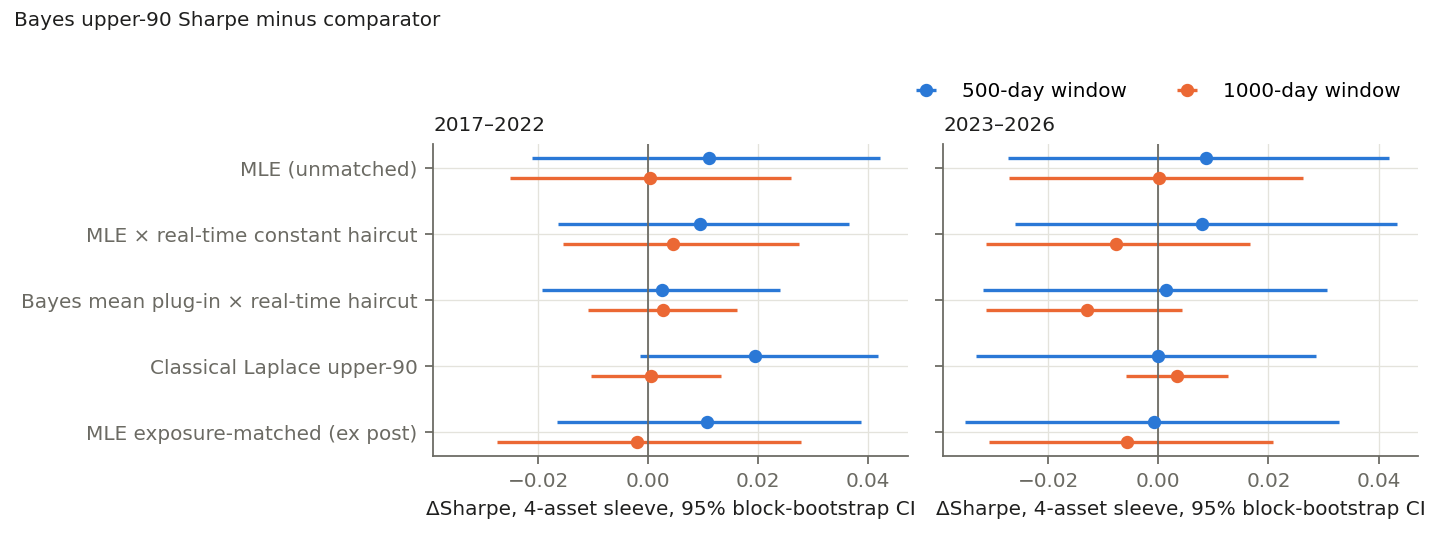

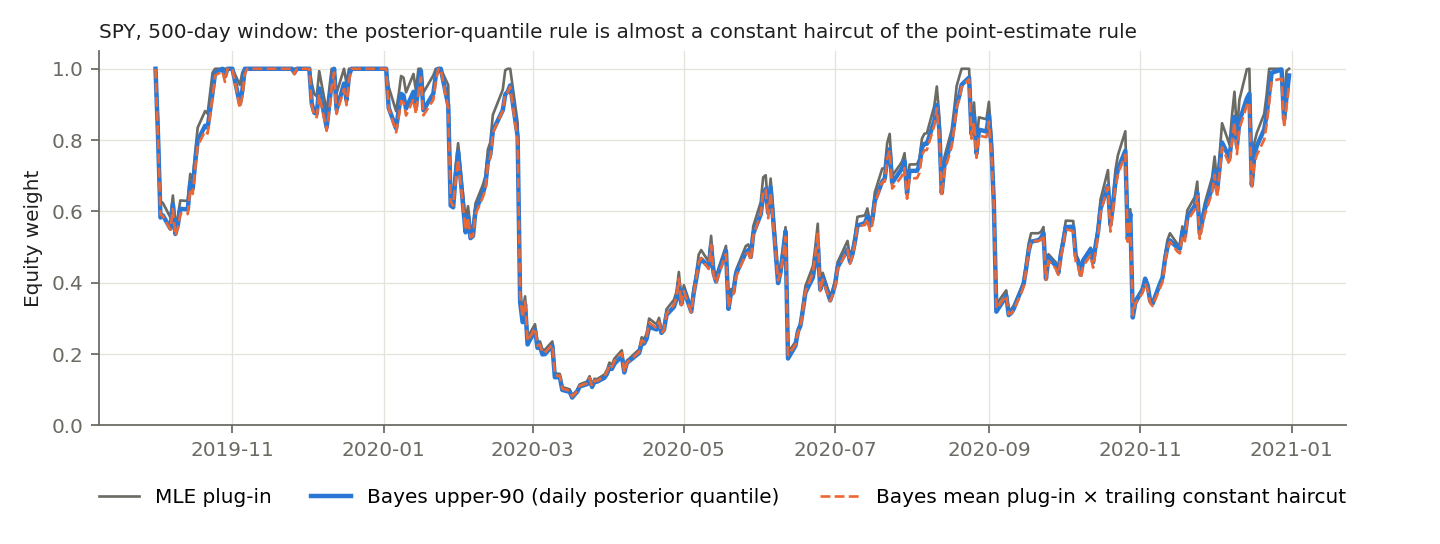

In [64]:
TAB = OUT / 'tables'; TAB.mkdir()
for s in SEGS:
    pooled[s].to_csv(TAB / f'forecast_pooled_{s}.csv', index=False); alloc[s][3].to_csv(TAB / f'alloc_pooled_pairs_{s}.csv', index=False)
    info[s].to_csv(TAB / f'info_{s}.csv', index=False)
with N.script_style():                           # as when quick mode runs the figure code from the command line
    figs = FG.make_all(TAB, STORE, OUT / 'figs')
for p_ in figs:
    check(f'regenerated report figure {Path(p_).name} is pixel-identical', N.png_identical(p_, cfg.FIGURES / Path(p_).name))
for nm in ['fig2_sharpe_differences.png', 'fig3_weight_paths_spy2020.png']:
    display(Image(filename=str(OUT / 'figs' / nm), width=860))

**Reading report Figures 7 and 9 and Tables 8–10.**
- **Sharpe ratios (equal-weight four-ETF sleeve).** All Gaussian-GARCH rules (MLE, MAP, Bayesian, Laplace, controls) lie within about 0.02 of one
  another in each period. Every 95% interval
  for upper-90 versus MLE, versus the implementable control, and versus the classical Laplace upper-90 contains zero.
  The point estimates are within ±0.02.
- **Drawdowns (means over the 8 single-ETF configurations).** Upper-90 has a smaller maximum drawdown than MLE in 8 of 8 configurations in both periods, by
  0.8–1.0 percentage points, because it holds 3.6–4.1 points less exposure. Against the exposure-matched control,
  the drawdown difference is −0.07 and +0.09 points and the Sharpe difference is +0.003 and −0.001.
- **Report Figure 7 (and `fig3`).** The posterior-quantile weights are very close to a constant haircut of the point-estimate weights.
  The posterior adds almost no *timing* information.
- **Larger differences come from modelling choices unrelated to Bayes**: Student-$t$ versus Gaussian GARCH, EWMA
  versus GARCH, or dynamic versus static allocation. The latter's sign flips between periods. Even those are not
  statistically reliable over 4–6 years.

> **Corrected discrepancy.** The original report (§5 at the time; now §7) said that "all GARCH-based rules have Sharpe ratios within about
> 0.03 of one another in each period". This holds for the Gaussian-GARCH rules (spread at most 0.02), but **Student-$t$
> GARCH** sits up to 0.047 above the lowest rule in 2017–22 ($W=500$: 0.903 vs 0.856). The Bayesian-versus-classical
> conclusions are unaffected. The course report was corrected on 2026-11-06; see `docs/notebook_coverage.md`.

### 13.7 Uncertainty quantification: the paired circular block bootstrap

**Why not ordinary resampling?** Daily returns are dependent: volatility clusters (§2.2), and drawdowns are
path-dependent by definition. Resampling individual days independently destroys that dependence. The resulting
standard errors are then misstated, usually too small when the dependence is positive, and the resampled paths no
longer contain realistic crash episodes. Resampling blocks of consecutive days keeps the dependence within each
block and is valid whatever its sign, provided it dies out within a few blocks.

**The procedure** (`evaluation.paired_bootstrap`; Politis & Romano, 1992):
1. Wrap the $n$ days on a circle. Draw $\lceil n/20\rceil$ random starting days and take 20 consecutive days from
   each, giving one resampled path of length $n$.
2. Apply the **same** indices to both strategies and to cash. This preserves their very strong correlation: the
   difference of two highly correlated Sharpe ratios is far more precise than either alone.
3. Compute $\Delta\text{Sharpe}$ and $\Delta\text{MaxDD}$ on the resampled path, and repeat $B=2{,}000$ times.
4. The 95% interval is the 2.5–97.5% percentile range. The seed is a fixed hash of the pair name, so tables are
   reproducible.

🔵 *saved forecasts* — the sleeve for upper-90 versus the control (2017–22, $W=500$) reconstructed, its bootstrap
reproduced, and contrasted with an iid bootstrap and with other bootstrap seeds.

In [65]:
seg, w = 'ext', 500; rr = {'bayes_upper90': [], 'mle_const_rt': []}; rf_l = []
for a in ASSETS:
    fa = STORE.daily(a, w, seg); Wa = strategies.strategy_weights(fa, a, seg)
    for k in rr:
        _, c = pf.portfolio(fa, Wa[k]); rr[k].append(c.portfolio_return.to_numpy())
    rf_l.append(c.risk_free_return.to_numpy())
ra, rb, rf = np.mean(rr['bayes_upper90'], 0), np.mean(rr['mle_const_rt'], 0), np.mean(rf_l, 0)
bs = ev.paired_bootstrap(ra, rb, rf, B=2000, seed=zlib.crc32(f'{w}bayes_upper90mle_const_rt'.encode()))
row = PP[seg].loc[('bayes_upper90', 'mle_const_rt', w)]
check('hand-built sleeve + bootstrap == report Table 10 entry', np.isclose(bs['d_sharpe'], row.d_sharpe) and np.isclose(bs['d_sharpe_lo'], row.d_sharpe_lo) and np.isclose(bs['d_sharpe_hi'], row.d_sharpe_hi))
iid = ev.paired_bootstrap(ra, rb, rf, B=2000, block=1, seed=1)
seeds = pd.DataFrame([ev.paired_bootstrap(ra, rb, rf, B=2000, seed=sd_) for sd_ in range(1, 9)])
display(pd.DataFrame({'ΔSharpe 95% CI': [f"[{bs['d_sharpe_lo']:+.4f}, {bs['d_sharpe_hi']:+.4f}]", f"[{iid['d_sharpe_lo']:+.4f}, {iid['d_sharpe_hi']:+.4f}]"],
                      'ΔMaxDD 95% CI (pp)': [f"[{100*bs['d_maxdd_lo']:+.2f}, {100*bs['d_maxdd_hi']:+.2f}]", f"[{100*iid['d_maxdd_lo']:+.2f}, {100*iid['d_maxdd_hi']:+.2f}]"]},
                     index=['circular block bootstrap, 20-day blocks', 'iid bootstrap (block = 1)']))
print(f"point estimate ΔSharpe {bs['d_sharpe']:+.4f};  Monte Carlo spread of the CI endpoints over 8 bootstrap seeds: "
      f"lower {seeds.d_sharpe_lo.min():+.4f}..{seeds.d_sharpe_lo.max():+.4f}, upper {seeds.d_sharpe_hi.min():+.4f}..{seeds.d_sharpe_hi.max():+.4f}")
print(f'lag-1..5 autocorrelation of squared sleeve returns: {np.round(dg.acf(ra**2, 5), 3)}  (dependence the blocks preserve)')

PASS  hand-built sleeve + bootstrap == report Table 10 entry


,ΔSharpe 95% CI,ΔMaxDD 95% CI (pp)
"circular block bootstrap, 20-day blocks","[-0.0164, +0.0364]","[-0.22, +0.43]"
iid bootstrap (block = 1),"[-0.0234, +0.0436]","[-0.32, +0.47]"


point estimate ΔSharpe +0.0094;  Monte Carlo spread of the CI endpoints over 8 bootstrap seeds: lower -0.0191..-0.0164, upper +0.0348..+0.0362
lag-1..5 autocorrelation of squared sleeve returns: [0.058 0.022 0.018 0.073 0.019]  (dependence the blocks preserve)


**Interpretation.**
- **Block versus iid.** Here the iid intervals are somewhat *wider* than the block intervals. The daily return
  differences between two nearly identical rules are slightly negatively autocorrelated, as the control's haircut
  catches up with the posterior quantile, so ignoring dependence happens to err on the conservative side. Volatility
  targeting has also removed most of the clustering: the squared sleeve returns have autocorrelations of only about
  0.02–0.07. The block bootstrap is used because it is valid either way, and both intervals contain zero.
- **Monte Carlo variability.** Varying the bootstrap seed moves the CI endpoints only in the third or fourth
  decimal. Bootstrap noise is negligible next to the width of the intervals. MCMC seed noise in the upper-90 Sharpe
  ratio is up to about 0.01 (§5.7), the same order as the point differences being tested. Sharpe differences of
  that size cannot be interpreted.
- **Power.** The 95% intervals are about ±0.02–0.04 wide. With 4–6 years of data, Sharpe differences below about
  0.05 cannot be resolved. A non-significant difference here is *absence of evidence*, not *evidence of equality*.

### 13.8 Transaction-cost sensitivity

🔵 *saved forecasts* — Sharpe ratios at 0, 5 and 20 bp recomputed and checked against the research's cost table.

In [66]:
cost_rows = []
for s in SEGS:
    refc = pd.read_csv(cfg.SAVED_PRIMARY / f'cost_sensitivity_{s}.csv'); new = []
    for cb in sorted(refc.cost_bps.unique()):
        for a in ASSETS:
            for w in WINDOWS:
                fa = STORE.daily(a, w, s); Wa = strategies.strategy_weights(fa, a, s); rec = dict(cost_bps=cb, asset=a, window=w)
                for k in ['mle', 'bayes_upper90', 'mle_const_rt', 'bayes_integrated', 'static_target']:
                    s_, _ = pf.portfolio(fa, Wa[k], cb); rec[f'sharpe_{k}'] = s_['sharpe_excess_cash']; rec[f'turnover_{k}'] = s_['mean_daily_turnover']
                new.append(rec)
    new = pd.DataFrame(new)[refc.columns]
    check(f'cost-sensitivity table {SEGL[s]} == research table', np.allclose(new.select_dtypes('number').to_numpy(float), refc.select_dtypes('number').to_numpy(float), rtol=0, atol=1e-12))
    cost_rows.append(new.assign(period=SEGL[s]))
CS = pd.concat(cost_rows).assign(d_upper90_minus_control=lambda x: x.sharpe_bayes_upper90 - x.sharpe_mle_const_rt, d_upper90_minus_mle=lambda x: x.sharpe_bayes_upper90 - x.sharpe_mle)
display(CS.groupby(['period', 'cost_bps'])[['sharpe_mle', 'sharpe_bayes_upper90', 'sharpe_mle_const_rt', 'd_upper90_minus_mle', 'd_upper90_minus_control', 'turnover_mle']].mean().round(4))

PASS  cost-sensitivity table 2017–22 == research table
PASS  cost-sensitivity table 2023–26 == research table


sharpe_mle  sharpe_bayes_upper90  sharpe_mle_const_rt  d_upper90_minus_mle  d_upper90_minus_control  turnover_mle
period  cost_bps                                                                                                                   
2017–22 0.0           0.5593                0.5647               0.5603               0.0054                   0.0045        0.0343
        5.0           0.5176                0.5199               0.5165               0.0023                   0.0034        0.0343
        20.0          0.3925                0.3853               0.3850              -0.0072                   0.0003        0.0343
2023–26 0.0           0.6221                0.6263               0.6251               0.0042                   0.0013        0.0229
        5.0           0.5936                0.5947               0.5958               0.0011                  -0.0011        0.0229
        20.0          0.5079                0.4998               0.5079              -0.0081                  -0.0081        0.0229

**H3: not supported by the evidence.**
- *Drawdowns.* The conservative Bayesian rule's smaller drawdowns are fully explained by its lower average exposure.
- *Against the control.* Against an implementable exposure-matched control there is no statistically supported
  improvement in return, Sharpe ratio or drawdown, in either period or window.
- *Costs.* Turnover is similar across GARCH rules, so costs of 0–20 bp shift all of them alike and reverse no
  conclusion.
- *Interpretation.* The posterior's day-to-day variation is almost a deterministic function of the variance level
  (§11.7). It therefore adds no timing information beyond a constant haircut, which a lower volatility target would
  achieve just as well.

> **Finding 2.** The observed drawdown reduction is largely consistent with reduced risky exposure rather than
> demonstrably superior risk timing from Bayesian parameter uncertainty. Better-looking portfolio performance must be
> examined against appropriately controlled alternatives.

This does not rule out every possible benefit of Bayesian inference for allocation (other decision rules or models
might use the posterior differently), and matching average exposure is not a perfect control for all differences in
portfolio risk.

<a id="s14"></a>
## 14. Discussion, limitations and report cross-check

### 14.1 Findings by hypothesis

| | Finding | Key evidence (this notebook) |
|---|---|---|
| **H1** variance forecasts | **Not supported by the evidence.** No statistically reliable QLIKE improvement from shrinkage or integration | §9.4: no Bayesian contrast significant, all at the $10^{-3}$ scale |
| **H2** density forecasts | **Supported, but small.** Log-score gain of 0.0015–0.005 nats/day, significant in every pooled test; Laplace captures 43–89% of it; Student-$t$ gains about 5–6× more in 2017–22 (3.6–7.5× across all cells) | §10.1–10.3, report Figure 3 |
| **H3** portfolios | **Not supported by the evidence.** Lower drawdowns come from about 4 pp lower exposure; versus an exposure-matched control, no statistically supported gain in return, Sharpe ratio or drawdown | §13.6–13.8, report Tables 6–10, Figures 7–9 |

**Why integration modestly improves densities but not variances.**
- *Variances.* The integrated variance $E[h(\theta)]$ differs from the plug-in only through a second-order Jensen
  term, so QLIKE, which sees only the variance, hardly moves.
- *Densities.* The mixture is a slightly *wider-tailed* distribution than any single Gaussian with the same
  variance. The log score rewards exactly that on the many days when Gaussian tails are too thin (§11).

**Why Student-$t$ does much better.** The conditional distribution of returns is fat-tailed: excess kurtosis of the
out-of-sample $z$ is about 2–3. Integration over parameters can supply only $3\,\mathrm{CV}^2\approx0.02$–$0.05$ of
excess kurtosis; Student-$t$ innovations supply the right order of magnitude.

**Why conservative allocation reduces drawdowns only through exposure.** The upper-90 rule is almost a constant
haircut of the MLE rule (report Figure 7). A constant haircut reduces volatility and drawdown proportionally and leaves the
Sharpe ratio unchanged (§13.3). The control reproduces it in real time.

**Why better forecasts need not mean better decisions.**
- The portfolio rule uses only $\sqrt{h_t}$. It is blind to the density shape, which is where the Bayesian gain lives.
- Its sensitivity to the variance is $\partial w/w\approx-\tfrac12\,\partial h/h$, so variance differences of
  0.1–1% move weights negligibly.
- The weight is capped at 1, so in calm periods every rule is fully invested whatever its forecast.

A statistically detectable improvement in a proper scoring rule can therefore be economically irrelevant for a
particular decision rule.

<a id="s14-2"></a>
### 14.2 Cross-check against the final report

The report's LaTeX tables were produced by `scripts/make_report_tables.py` from quick-mode tables. Here that script is run
**unchanged** on the tables recomputed in *this* notebook. Each regenerated `.tex` file is compared byte for byte
with the one in `reports/source/tables/` that the report includes. Together with the pixel comparisons of the figures (§11,
§13) and the claim checks above, this verifies the report's numerical content against the daily data.

,report_table,identical,lines
0,reports/source/tables/forecasts.tex,True,15
1,reports/source/tables/allocation.tex,True,14
2,reports/source/tables/paired.tex,True,8
3,reports/source/tables/exposure.tex,True,5
4,reports/source/tables/var.tex,True,10
5,reports/source/tables/fits.tex,True,5
6,reports/source/tables/adequacy.tex,True,18
7,reports/source/tables/forecasts_qlike.tex,True,9
8,reports/source/tables/forecasts_logscore.tex,True,9
9,reports/source/tables/ratios.tex,True,8


PASS  all 13 report tables regenerated from notebook computations are byte-identical to reports/source/tables/*.tex  [13/13]


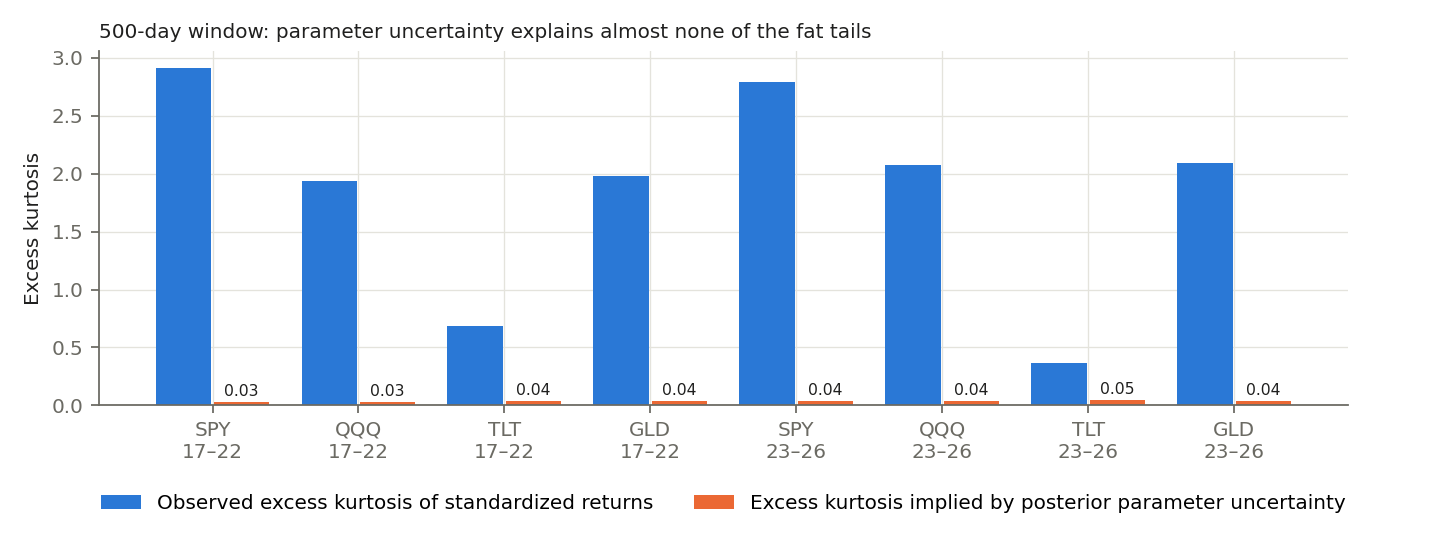

In [67]:
nb_tables = {'fit_summary': fs}
for s in SEGS:
    nb_tables |= {f'forecast_pooled_{s}': pooled[s], f'alloc_pooled_summary_{s}': alloc[s][2], f'alloc_pooled_pairs_{s}': alloc[s][3],
                  f'alloc_summary_{s}': alloc[s][0], f'alloc_pairs_{s}': alloc[s][1], f'tail_{s}': tail[s]}
RT = N.report_tables(nb_tables, diag_ext, OUT / 'report_tables')
display(RT)
check('all 13 report tables regenerated from notebook computations are byte-identical to reports/source/tables/*.tex', RT.identical.all() and len(RT) == 13, f'{int(RT.identical.sum())}/{len(RT)}')
display(Image(filename=str(OUT / 'figs' / 'fig4_kurtosis.png'), width=800))

### 14.3 Limitations

- **Model specification.** Only symmetric, zero-mean Gaussian GARCH(1,1) receives a Bayesian treatment. Bayesian
  Student-$t$ or asymmetric (GJR, skewed-$t$) models, whose additional parameters are weakly identified, could show
  larger effects of parameter uncertainty. The diagnostics of §11 show that asymmetry and jumps are the first-order
  misspecifications.
- **Data coverage and power.** Four ETFs, two dependent windows and 6 + 4 years. Sharpe differences below about 0.05
  cannot be resolved, so "not supported" means *not detected*, not *absent*. The 2023–26 period was inspected
  before, so it is not independent evidence.
- **Numerical uncertainty.** Bayesian quantities are Monte Carlo estimates: platform-dependent at the 0.5–1.7% level
  for variance quantiles and up to about 0.01 in Sharpe. 4 of 320 refits miss the strict convergence rule
  marginally, without consequence for the comparisons (§10.4). The MLE persistence bound binds in 30 of 320 refits
  (§4.5).
- **Design choices.** Posteriors are refreshed only quarterly, and one prior (with a broad-prior check) and one
  volatility target were used.
- **Portfolio assumptions.** Close-to-close execution, flat 5 bp costs, DFF cash, single-asset rules in an
  equal-weight sleeve, and no leverage.

### 14.4 Future research (not started here)

- Bayesian treatment of Student-$t$ and asymmetric GARCH, where parameter uncertainty about $\nu$ and the leverage
  term is larger.
- Daily or sequential posterior updating, e.g. sequential Monte Carlo, instead of quarterly refits.
- Decision rules that use the *whole* predictive distribution (e.g. VaR- or expected-shortfall-targeting) and could
  therefore benefit from density improvements.
- Multivariate allocation across the four ETFs with correlated volatility.
- Realised-volatility proxies from intraday data, to sharpen the evaluation of variance forecasts.

<a id="s15"></a>
## 15. Reproducibility and research appendix

### 15.1 Environment and package

In [68]:
import scipy, numba, statsmodels
vers = {'python': platform.python_version(), 'platform': platform.platform(), 'machine': platform.machine(), 'numpy': np.__version__,
        'scipy': scipy.__version__, 'pandas': pd.__version__, 'numba': numba.__version__, 'arviz': az.__version__,
        'statsmodels': statsmodels.__version__, 'matplotlib': matplotlib.__version__, 'bgarch': bgarch.__version__}
display(pd.Series(vers, name='version').to_frame())
import bgarch as _b, bgarch_experiments as _e
print(_b.__doc__.split('Modules')[0].strip()); print()
display(pd.DataFrame([(m, (getattr(__import__(f'bgarch.{m}', fromlist=['x']), '__doc__') or '').strip().splitlines()[0]) for m in _b.__all__ if m != 'paths'],
                     columns=['bgarch module', 'purpose']).set_index('bgarch module'))

,version
python,3.12.2
platform,macOS-26.6.2-arm64-arm-64bit
machine,arm64
numpy,1.26.4
scipy,1.12.0
pandas,2.2.2
numba,0.59.1
arviz,0.21.0
statsmodels,0.14.2
matplotlib,3.8.4


bgarch: a small library for Bayesian and classical GARCH(1,1) volatility forecasting and volatility targeting.



,purpose
bgarch module,
data,Market data and return construction.
garch,"Gaussian zero-mean GARCH(1,1): parameter trans..."
bayes,"Bayesian GARCH(1,1): prior, posterior mode, MC..."
forecast,Posterior-predictive and plug-in forecasts for...
student_t,"Student-t GARCH(1,1) MLE (innovation-misspecif..."
ewma,"RiskMetrics-style EWMA benchmark, imported unc..."
evaluation,Forecast-evaluation and paired-comparison stat...
diagnostics,Out-of-sample forecast diagnostics on plain ar...
portfolio,Volatility targeting and portfolio accounting ...


**Architecture.**
- **`src/bgarch/`** is the reusable library. It contains models, inference, forecasts, evaluation, diagnostics and
  portfolio accounting, and it contains no experiment settings. It re-exports the validated numerical core of the
  original project (`src/*.py`) unchanged, so no algorithm exists twice.
- **`src/bgarch_experiments/`** is the study itself:
  - the configuration (`config`: periods, windows, seeds, artifact paths);
  - the strategy set;
  - the rolling engine (`walkforward`);
  - the report tables and figures;
  - the adequacy study;
  - checksums;
  - the reproduction CLI;
  - this notebook's helpers.
- **Installation.** `pip install -e .` at the repository root installs both packages (see the repository `README.md`). Without
  installation, the notebook locates the repository root and adds `src/` to `sys.path` itself.

### 15.2 Random seeds

| Quantity | Seed |
|---|---|
| master seed of a job | 102026 (2017–22), 2026 (2023–26) |
| MCMC starting points, refit $i$ | master + 173 $i$ |
| MCMC chain $k$ of that refit | master + 173 $i$ + 1000 + 97 $k$ |
| subsample of $M=300$ posterior draws | `default_rng(master)`, one stream across refits |
| Laplace draws | `default_rng(master + 7,777,777)`, one stream across refits |
| block bootstrap | `zlib.crc32` hash of asset, window and pair names |
| this notebook's extra demos | 0, 1, 5, 11 (stated in each cell) |

### 15.3 Saved artifacts and workflows

In [69]:
arts = []
for s in SEGS:
    for a in ASSETS:
        for w in WINDOWS:
            for suf in ['daily.csv.gz', 'fits.csv', 'draws.npz', 'meta.json']:
                p_ = cfg.SAVED_FORECASTS / f'{STORE.name(a, w, s)}_{suf}'; arts.append(dict(kind=suf, bytes=p_.stat().st_size))
display(pd.DataFrame(arts).groupby('kind').agg(files=('bytes', 'size'), total_MB=('bytes', lambda b: round(b.sum() / 1e6, 1))))
print('location:', cfg.rel(cfg.SAVED_FORECASTS), '| research tables:', cfg.rel(cfg.SAVED_PRIMARY),
      '| checksums: artifacts/results/artifact_manifest.json (48 files), artifacts/results/adequacy_manifest.json (16 files)')

,files,total_MB
kind,,
daily.csv.gz,16,5.9
draws.npz,16,23.0
fits.csv,16,0.1
meta.json,16,0.0


location: artifacts/forecasts/. | research tables: agent_research/results/primary | checksums: artifacts/results/artifact_manifest.json (48 files), artifacts/results/adequacy_manifest.json (16 files)


**Quick workflow (saved rolling forecasts; about 2 minutes in total).**
```bash
pip install -e .                                         # once, at the repository root; or: conda env create -f environment.yml
pytest                                                   # unit + reproduction tests (~6 s)
python -m bgarch_experiments.reproduce quick             # verify 48 checksums, rebuild all tables/figures, compare (~20 s)
python -m bgarch_experiments.adequacy                    # adequacy tables and figures (~15 s)
jupyter nbconvert --to notebook --execute --inplace notebooks/walkthrough.ipynb   # this notebook (~1.5 min)
```
**Full workflow (re-estimate everything from market data).**
```bash
python -m bgarch_experiments.reproduce full --out /tmp/bgarch_full_run   # 320 refits, ~70 s on 7 cores; new/empty dir only
python scripts/make_report_tables.py && cd reports/source && latexmk -pdf research_report.tex   # report tables and PDF
```
`python -m bgarch.reproduce` and `python -m bgarch.adequacy` are kept as aliases, because the report cites them.
Market data are not redistributed; see the repository `README.md` ("Data and saved artifacts") for how to obtain them. A fresh download extends the
sample and changes all results.

**Tolerances.**
- Classical quantities (MLE, EWMA, Student-$t$, portfolio accounting, every test statistic) are deterministic and are
  checked to $10^{-12}$ or better.
- Bayesian quantities are checked exactly on the platform that produced them; on another platform expect
  Monte Carlo-level differences (§5.7).
- The mixture log score recomputed from the float32-stored draws agrees with the float64 original to about $10^{-6}$.

<a id="s15-4"></a>
### 15.4 Derivations

**(a) Multi-step variance forecast.** For $k\ge2$, $E[r^2_{t+k-1}\mid\mathcal F_t]=E[h_{t+k-1}\mid\mathcal F_t]$, so
$$E[h_{t+k}\mid\mathcal F_t]=\omega+(\alpha+\beta)E[h_{t+k-1}\mid\mathcal F_t].$$
Subtracting $V=\omega+pV$ gives $E[h_{t+k}\mid\mathcal F_t]-V=p\,(E[h_{t+k-1}\mid\mathcal F_t]-V)$, and by induction
$=p^{k-1}(h_{t+1}-V)$. The half-life solves $p^{k}=1/2$.

**(b) Kurtosis of a Gaussian scale mixture.** If $r\mid H\sim N(0,H)$, then $E[r^2]=E[H]$ and
$E[r^4]=E[E[r^4\mid H]]=3E[H^2]$. So $\operatorname{kurt}(r)=3E[H^2]/E[H]^2=3(1+\mathrm{CV}^2_H)$, and the excess
kurtosis is $3\,\mathrm{CV}_H^2$. With $H=h_t(\theta)$, $\theta\sim$ posterior, this bounds what integration can
add; with $H=h_t$ over time, it explains GARCH's fat unconditional tails.

**(c) QLIKE is minimised by the true variance.** $E[\log h+r^2/h\mid\mathcal F]=\log h+h^\ast/h$, with derivative
$1/h-h^\ast/h^2$. This is zero at $h=h^\ast$, and the second derivative there is $1/h^{\ast2}>0$.

**(d) The Metropolis kernel is reversible.** For $u\ne u'$ the kernel density is $K(u,u')=q(u'\mid u)\,a(u,u')$
with symmetric $q$. Then
$$\pi(u)K(u,u')=q(u'\mid u)\min\{\pi(u),\pi(u')\},$$
which is symmetric in $(u,u')$. Detailed balance holds, so $\pi$ is stationary. Frozen proposals keep this property
during sampling; adaptation during warm-up does not matter, because warm-up draws are discarded.

**(e) The log score is strictly proper.** For a true density $g$,
$E_g[\log g(r)]-E_g[\log p(r)]=\mathrm{KL}(g\Vert p)\ge0$, with equality only if $p=g$.

**(f) Stationary initialisation.** With $h_1=V$, $E[h_t]=V$ for all $t$ under the model. Any other start $h_1$
gives $E[h_t]-V=p^{t-1}(h_1-V)$, which decays geometrically. That is why the choice matters only when $p\approx1$.

### 15.5 Auxiliary results preserved from the research

⚪ *artifact* — results the report mentions as robustness checks. Recomputing them would require additional MCMC runs
with other priors and seeds, so they are displayed from the saved research tables rather than rerun.

In [70]:
sp_tab = sp.groupby(['segment', 'prior', 'seed']).agg(failed_fits=('failed_fits', 'sum'), refits=('n_refits', 'sum'),
          qlike_int_minus_mle=('qlike_int_minus_mle', 'mean'), ls_mix_minus_mle=('ls_mix_minus_mle', 'mean'),
          d_sharpe_upper90_vs_control=('d_sharpe_upper90_constrt', 'mean'), d_exposure_upper90_vs_mle=('d_exposure_upper90_mle', 'mean')).rename(index=SEGL)
display(sp_tab.round(4))
broad = sp[sp.prior == 'broad']; mod = sp[(sp.prior == 'moderate') & sp.seed.isin([102026, 2026])]
check('broad prior: same signs of the log-score gain and of the upper-90 exposure cut as the moderate prior',
      (broad.ls_mix_minus_mle.mean() > 0) == (mod.ls_mix_minus_mle.mean() > 0) and (broad.d_exposure_upper90_mle < 0).all(), level=ART)
dec = json.loads((cfg.PROJECT / 'agent_research/results/discovery/validation_decision.json').read_text())
print('exploratory strategy search (pre-registered validation gate): candidates that passed =', dec['passed'], '-> the final holdout was never used')

failed_fits  refits  qlike_int_minus_mle  ls_mix_minus_mle  d_sharpe_upper90_vs_control  d_exposure_upper90_vs_mle
segment prior    seed                                                                                                                      
2017–22 broad    102026           10     192              -0.0051            0.0048                       0.0078                    -0.0338
        moderate 100011            1     192              -0.0049            0.0047                       0.0035                    -0.0359
                 102026            2     192              -0.0055            0.0049                       0.0034                    -0.0356
2023–26 broad    2026              9     128              -0.0013            0.0036                      -0.0014                    -0.0382
        moderate 11                0     128              -0.0014            0.0034                      -0.0014                    -0.0406
                 12                4     128              -0.0015            0.0033                      -0.0021                    -0.0415
                 2026              2     128              -0.0021            0.0037                      -0.0011                    -0.0410

PASS  broad prior: same signs of the log-score gain and of the upper-90 exposure cut as the moderate prior
exploratory strategy search (pre-registered validation gate): candidates that passed = [] -> the final holdout was never used


**Reading.**
- *Broad prior.* It gives the same qualitative conclusions: a positive log-score gain from integration, and a lower
  exposure for upper-90 with no Sharpe gain against the control. It causes more convergence failures, including a
  bimodal TLT posterior.
- *Seeds.* Across MCMC seeds, the contrasts move only at the Monte Carlo level.
- *Strategy search.* The exploratory search for uncertainty-aware strategies was pre-registered with a validation
  gate. No candidate passed, so the final holdout was never used. Details are in `agent_research/final_report.md`.

<a id="s15-6"></a>
### 15.6 Summary of numerical checks

In [71]:
chk = check.frame()
display(chk.groupby('level').passed.agg(['count', 'sum']).rename(columns={'count': 'checks', 'sum': 'passed'}))
with pd.option_context('display.max_rows', 200, 'display.max_colwidth', 120):
    display(chk)
print(f'{int(chk.passed.sum())} / {len(chk)} checks passed;  notebook runtime {time.time() - T_START:.0f} s')
assert chk.passed.all(), chk[~chk.passed]

,checks,passed
level,,
artifact,7,7
raw data,28,28
saved forecasts,95,95


,check,passed,level,detail
0,saved forecast/fit artifacts match SHA-256 manifest,True,artifact,48 files
1,saved posterior-draw artifacts match SHA-256 manifest,True,artifact,16 files
2,all four ETFs share one trading calendar,True,raw data,
3,log returns equal log price ratios,True,raw data,
4,numba log-likelihood == plain-Python reference,True,raw data,1533.972001 vs 1533.972001
5,"every u in R^3 gives omega>0, alpha,beta>=0, alpha+beta<1",True,raw data,"10,000 random u"
6,"u -> (omega, alpha, beta) -> u round trip",True,raw data,
7,fresh MLE log-likelihood == saved research fit,True,raw data,
8,fresh MLE log-likelihood == original Milestone 10 fit,True,raw data,
9,independent Nelder-Mead agrees (log-lik within 1e-5),True,raw data,-3.2e-10


130 / 130 checks passed;  notebook runtime 38 s


<a id="s16"></a>
## 16. Final research summary

### H1 — Conditional variance
Bayesian posterior integration produces small numerical QLIKE improvements (about $-0.005$ in 2017–22, $p=0.10$ and
$0.08$), but they are not statistically reliable at the conventional 5% level in the primary evaluation (§9).

### H2 — Predictive distributions
Bayesian parameter integration modestly improves the predictive return density (0.002–0.005 nats/day, significant in
every cell), and a classical Laplace approximation captures 43–89% of that gain. Student-$t$ GARCH estimated by MLE
produces substantially larger improvements, five to six times as large in 2017–22 (3.6–7.5× across all cells), which
indicates that innovation-distribution specification matters more than Gaussian GARCH parameter uncertainty in the
tested setting (§10–§11).

### H3 — Portfolio allocation
Conservative Bayesian (upper-90) allocation reduces risky exposure (about 3.6 pp in 2017–22) and drawdowns (8 of 8
configurations). After comparison with exposure-matched MLE, the drawdown advantage disappears and every
Sharpe-difference interval contains zero: no statistically reliable incremental investment benefit is established
(§12–§13).

### Two central takeaways
1. **Better modelling of heavy-tailed innovations can matter more for predictive-density accuracy than integrating
   parameter uncertainty under a misspecified Gaussian model.**
2. **Better-looking portfolio performance must be examined against appropriately controlled alternatives.** Lower
   drawdown is not necessarily evidence of better forecasting or investment timing when average exposure also decreases.

### Overall conclusion
Better probabilistic forecasts do not automatically translate into economically better investment decisions. Model
specification, uncertainty quantification and fair, risk-controlled experiments are all essential to evaluating
practical value. Tested limitations and untested extensions are listed in §14.3–14.4.